# Explainability for the trained Constrained GCN-LSTM-PPO last-mile models (v4.1 run)
**Inference / read-only. No training, no checkpoint writes.** Everything generated goes to a **new** folder `explain_<preset>_<split>/` inside `WORK_DIR`; `runs_*`, `cache_*`, `report_*` are never written.

Run the sections top to bottom. **Do not run `## 4. Run the pipeline` of the training notebook**: it resumes unfinished stages = training. This notebook never calls `pipeline`, `train`, `bc` or `evaluate`.

Three levels:
- **Macro**: penalty weights (lambda) over PPO updates, from `train_log.jsonl`.
- **Decision**: one greedy rollout, per-candidate features and actor logits, from `best.pt` (inference only).
- **Route**: one route compared across models, baselines and driver, from `eval_test*.json` (+ optional environment replay, no model).
- **Route, all routes** (section 9): every test route and seed aggregated: coverage, distributions, seed vs route variability, constraint satisfaction and paired comparisons with the driver, Nearest Neighbor and OR-Tools baselines, from the same `eval_test*.json`.

## 1. Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Settings
Same values as `## 2. Settings` of the training notebook.

In [2]:
WORK_DIR = "/content/drive/MyDrive/lastmile_work_v4"
PRESET = "full"
SPLIT_BY = "stratified"
tag = f"{PRESET}_{SPLIT_BY}"
RUNS = f"{WORK_DIR}/runs_{tag}"
CACHE = f"{WORK_DIR}/cache_{tag}"
EXPLAIN_DIR = f"{WORK_DIR}/explain_{tag}"     # NEW output folder
print(RUNS); print(CACHE); print(EXPLAIN_DIR)

: 

### 2.1 Seed → run mapping and fresh-process runner
Mapping used by sections 6–9, taken from `lastmile_rl.make_run_dir`: run folder `RUNS/<name>_s<seed>/` with `best.pt`, `eval_test.json`, `eval_test_zls.json`. Seeds come from `MACRO_SEEDS` (section 5.1), so changing that one string changes every seed loop. Every script call is a **new Python process** (not `%run`, not import): `lastmile_rl.py` must load OR-Tools before torch, and the scripts import it first.


In [3]:
import os, sys, subprocess
from pathlib import Path

EXPLAIN_MODEL = "frozen_topk"                   # name part of RUNS/<name>_s<seed>: model explained in sections 6 and 7
ROUTE_MODELS = ["frozen_topk", "lagr_free_p3"]  # models compared in section 8 (same two as before)
EXPLAIN_SPLIT = "test"

def seeds():
    """Seeds from MACRO_SEEDS (defined in 5.1): single source for sections 5-8."""
    return [int(s) for s in MACRO_SEEDS.split(",") if s.strip()]

def run_dir(name, seed):                        # lastmile_rl.make_run_dir: <runs_dir>/<name>_s<seed>
    return Path(RUNS) / f"{name}_s{seed}"

def ckpt_path(name, seed):
    return run_dir(name, seed) / "best.pt"

def eval_files(name, seed, split=EXPLAIN_SPLIT):
    """eval_<split>.json (pure greedy policy) and eval_<split>_zls.json (policy + zone local search), if present."""
    return [p for p in (run_dir(name, seed) / f"eval_{split}.json", run_dir(name, seed) / f"eval_{split}_zls.json") if p.exists()]

def run_fresh(script, args, label):
    """One fresh python process per call; output streamed into the cell. Returns the exit code."""
    cmd = [sys.executable, f"/content/{script}", *[str(a) for a in args]]
    print(f"\n$ {label}")
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                         env={**os.environ, "LASTMILE_DIR": "/content"})
    for line in p.stdout:
        print(line, end="")
    return p.wait()


## 3. Write the scripts to the Colab runtime
File writes only (`/content/*.py`). Nothing is trained or evaluated here.

### 3.1 `lastmile_rl.py` (identical to `## 3. Write the script` of the training notebook)
Needed for the decision-level and replay scripts: it provides the environment, `Policy` and checkpoint-compatible code. Skip if `/content/lastmile_rl.py` already exists from this session.

In [4]:
%%writefile /content/lastmile_rl.py
"""
lastmile_rl.py - Constrained GCN-LSTM-PPO for the Amazon Last-Mile Routing dataset.

COLAB: the only input is the dataset path.

  from google.colab import drive; drive.mount('/content/drive')
  !python /content/drive/MyDrive/lastmile_rl.py pipeline --data-root "/content/drive/MyDrive/amazon_dataset"

  * --data-root may be any folder that contains the three eval_*.json files (searched recursively).
  * Outputs go to /content/drive/MyDrive/lastmile_work/ (cache, runs, report). Re-run the same cell
    after a disconnect: finished steps are skipped, training resumes from its last checkpoint.
  * Default --preset dev (300 routes, 1 seed) proves the pipeline end to end. For paper numbers
    run the same command with --preset full (all routes, 3 seeds, penalty sweep for the Pareto plot).
  * Run it with !python (a fresh process), not %run or import: OR-Tools must load before torch.
  * Speed: --workers 2 trains two seeds at once in separate processes (results identical to running them
    one after another); the Pareto penalty sweep runs on the preset's first seed only (--sweep-all-seeds
    restores it for every seed).
  * Every trained model is evaluated twice from one rollout: the pure policy (<name>) and the policy plus
    zone-preserving 2-opt (<name>+zls; never slower, zone order and re-entries unchanged, kept per route only
    if no behaviour cost gets worse).
  * Results: lastmile_work/report_<preset>_<split>/test/report.md, pareto.png; test_perturb/report.md.
  * Split: --split-by stratified (default) keeps the station x route-size mix equal in train/val/test.
    Also available: route (plain random) and station (whole stations held out, tests generalisation).
    Each (preset, split) pair gets its own cache/runs/report folders, so results never overwrite.

One file, one code path for training and evaluation. Subcommands map to the workflow:

  pipeline  all stages below in order, with skip/resume and the Stage-3 gate

  prepare   Stage 1   validate routes, cache matrices, train/val/test split, baselines
                      (driver, nearest-neighbour, NN+2-opt, OR-Tools)
  verify    Stage 2   environment correctness checks (exits non-zero on failure)
  bc        Stage 3a  behaviour cloning on driver sequences (warm start)
  train     Stage 3b  PPO with frozen penalties  (--penalty frozen)      = current system
            Stage 4   PPO-Lagrangian, driver-calibrated budgets (--penalty lagrangian)
  evaluate  Stage 6   greedy policy or random-within-mask on a split (+ travel-time perturbation)
  report    Stage 6   aggregate evals across seeds, paired Wilcoxon tests, Pareto plot

Manual sequence (what `pipeline` runs for you):

  python lastmile_rl.py prepare  --data-root /content/drive/MyDrive/amazon_dataset --max-routes 300
  python lastmile_rl.py verify   --mask topk
  python lastmile_rl.py verify   --mask free
  python lastmile_rl.py evaluate --random --mask topk --split val
  python lastmile_rl.py bc       --name bc_topk --mask topk
  python lastmile_rl.py train    --name frozen_topk --mask topk --penalty frozen \
                                 --init runs/bc_topk_s0/best.pt
  python lastmile_rl.py evaluate --ckpt runs/frozen_topk_s0/best.pt --split val
  python lastmile_rl.py train    --name lagr_free_p3 --mask free --phases 3 --penalty lagrangian \
                                 --init runs/bc_topk_s0/best.pt
  python lastmile_rl.py evaluate --ckpt runs/lagr_free_p3_s0/best.pt --split test
  python lastmile_rl.py report   --evals "runs/*/eval_test.json" --reference frozen_topk

Conventions
  * Tours are open paths: station -> all stops, no return leg (paper Eq. 1).
  * All times are seconds internally; reports show minutes.
  * Costs per step: zone_exit (0..1, scaled by stops left behind, capped at 5),
    zone_reentry (0/1, entering a zone previously left with stops remaining),
    far_jump (0/1, regret over the nearest unvisited stop > --farjump-regret seconds),
    pass_by (0..1, unvisited stops skipped although they lay on the way: w is on the way from u to v when
    T(u,w) + T(w,v) <= (1 + --passby-slack) * T(u,v); scaled by the number skipped, capped at 5).
    pass_by is the "drive past a stop and come back for it later" pattern, e.g. visiting B, A, C when
    A, B, C lie along one road.
  * Time of day: each route's real departure time (date_YYYY_MM_DD + departure_time_utc, converted to
    the station's local time) plus elapsed travel time is given to the LSTM as sin/cos of the local hour.
    The dataset has one static travel-time matrix per route: no traffic by hour exists in it, so time of
    day can only be learned from how drivers behave at different hours.
  * Driver budgets: the same costs measured by replaying the driver's actual sequence.
  * amazon_score: the challenge's route score (SeqDev x ERP-per-edit on the z-normalized matrix),
    reimplemented from the definitions in MIT-CAVE/rc-cli scoring/score.py and checked to give
    identical values. Lower = closer to the driver; the driver itself scores 0.
  * Determinism is guaranteed on CPU (default device). On CUDA, results may vary slightly.
  * Speed: routes are rolled out in lockstep (one batched forward pass per decision step for all
    routes of a PPO update, validation or evaluation chunk); every route is cached in memory after its
    first read; the actor's shared r_t half is computed once per step. PPO/BC keep one unpadded
    forward/backward pass per episode. The maths is unchanged; only the random-number stream of
    sampling differs from the earlier one-route-at-a-time version, so runs started with that
    version should be finished with it (or restarted) rather than resumed with this one.

Dependencies: numpy, torch (preinstalled on Colab); ijson, ortools, scipy, matplotlib are
installed automatically when missing (set LASTMILE_NO_AUTOINSTALL=1 to disable).
"""

from __future__ import annotations

import argparse
import glob
import json
import os
import random
import sys
import time
from collections import Counter, defaultdict
from dataclasses import asdict, dataclass
from pathlib import Path

import numpy as np


def _ensure_packages() -> None:
    """Install missing pip dependencies before torch is imported (OR-Tools must load first)."""
    import importlib.util
    import subprocess

    wanted = {"ijson": "ijson>=3.1", "ortools": "ortools", "scipy": "scipy", "matplotlib": "matplotlib"}
    missing = [pip for mod, pip in wanted.items() if importlib.util.find_spec(mod) is None]
    if missing and os.environ.get("LASTMILE_NO_AUTOINSTALL") != "1":
        print(f"Installing missing packages: {missing}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])


_ensure_packages()

try:  # must be imported before torch: both bundle abseil/protobuf and segfault in the other order
    from ortools.constraint_solver import pywrapcp, routing_enums_pb2
except ImportError:
    pywrapcp = routing_enums_pb2 = None

import torch
import torch.nn as nn
import torch.nn.functional as F

COST_NAMES = ("zone_exit", "zone_reentry", "far_jump", "pass_by")
K_COSTS = len(COST_NAMES)
BASELINE_NAMES = ("driver", "nn", "nn_2opt", "ortools")
MASKED_LOGIT = -1e9


# =====================================================================================
# Utilities
# =====================================================================================

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)


def load_json(path: Path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def write_json(path: Path, obj) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2)
    os.replace(tmp, path)


def score_sequence(seq, T: np.ndarray) -> float:
    s = np.asarray(seq, dtype=np.int64)
    return float(T[s[:-1], s[1:]].astype(np.float64).sum())


def normalized_matrix(T: np.ndarray) -> np.ndarray:
    z = (T - T.mean()) / T.std()
    return z - z.min()


def amazon_score(sub: list[int], actual: list[int], Mn: np.ndarray, g: float = 1000.0) -> float:
    """Challenge route score. sub/actual: closed tours (station at both ends), Mn: normalized_matrix(T)."""
    a_in = list(actual[1:-1])
    n = len(a_in)
    pos = {v: i for i, v in enumerate(a_in)}
    comp = np.array([pos[v] for v in sub[1:-1]])
    seq_dev = (2.0 / (n * (n - 1))) * float((np.abs(np.diff(comp)) - 1).sum())
    La, Ls = len(actual), len(sub)
    D = [[0.0] * (Ls + 1) for _ in range(La + 1)]   # ERP over suffixes actual[i:], sub[j:]
    C = [[0] * (Ls + 1) for _ in range(La + 1)]     # number of edits on the chosen path
    for j in range(Ls + 1):
        D[La][j], C[La][j] = g * (Ls - j), Ls - j
    for i in range(La + 1):
        D[i][Ls], C[i][Ls] = g * (La - i), La - i
    for i in range(La - 1, -1, -1):
        ai, Mrow, Dn, Cn, Di, Ci = actual[i], Mn[actual[i]], D[i + 1], C[i + 1], D[i], C[i]
        for j in range(Ls - 1, -1, -1):
            o1 = Dn[j + 1] + Mrow[sub[j]]
            o2 = Dn[j] + g
            o3 = Di[j + 1] + g
            d = min(o1, o2, o3)
            if d == o1:                     # same tie-breaking order as the official scorer
                c = Cn[j + 1] + (0 if ai == sub[j] else 1)
            elif d == o2:
                c = Cn[j] + 1
            else:
                c = Ci[j + 1] + 1
            Di[j], Ci[j] = d, c
    erp_per_edit = D[0][0] / C[0][0] if C[0][0] else 0.0
    return seq_dev * erp_per_edit


def amazon_route_score(seq, driver, T: np.ndarray) -> float:
    st = int(seq[0])
    return amazon_score([int(x) for x in seq] + [st], [int(x) for x in driver] + [st], normalized_matrix(T))


# The five metro areas of the Amazon Last-Mile Routing Research Challenge, keyed by station-code prefix.
STATION_TZ = {"DLA": "America/Los_Angeles", "DSE": "America/Los_Angeles", "DCH": "America/Chicago",
              "DAU": "America/Chicago", "DBO": "America/New_York"}


def departure_meta(routes: dict, ids: list[str]) -> tuple[dict, dict]:
    """Local departure hour per route from date_YYYY_MM_DD + departure_time_utc and the station's time zone."""
    from datetime import datetime, timezone
    from zoneinfo import ZoneInfo

    meta, notes = {}, Counter()
    for rid in ids:
        r = routes[rid]
        d, t = r.get("date_YYYY_MM_DD"), r.get("departure_time_utc")
        if not d or not t:
            raise SystemExit(f"Route {rid} has no date_YYYY_MM_DD / departure_time_utc; its keys: {sorted(r)}")
        when = datetime.fromisoformat(f"{d}T{t}").replace(tzinfo=timezone.utc)
        tz = STATION_TZ.get(str(r.get("station_code", ""))[:3])
        if tz is None:
            notes["station_time_zone_unknown_used_utc"] += 1
        else:
            when = when.astimezone(ZoneInfo(tz))
        meta[rid] = {"departure_local_hour": when.hour + when.minute / 60 + when.second / 3600,
                     "time_zone": tz or "UTC"}
    return meta, dict(notes)


def write_route_meta(cache: Path, routes_json: Path, ids: list[str]) -> None:
    meta, notes = departure_meta(load_json(routes_json), ids)
    write_json(cache / "route_meta.json", {"routes": meta, "notes": notes})
    print(f"route_meta.json: departure times for {len(meta)} routes; notes: {notes or 'none'}")


def make_run_dir(runs_dir: str, name: str, seed: int, overwrite: bool) -> Path:
    run_dir = Path(runs_dir) / f"{name}_s{seed}"
    if run_dir.exists() and any(run_dir.iterdir()) and not overwrite:
        raise SystemExit(f"{run_dir} already exists; pass --overwrite or use a new --name.")
    run_dir.mkdir(parents=True, exist_ok=True)
    return run_dir


# =====================================================================================
# Baseline solvers
# =====================================================================================

def nearest_neighbor(T: np.ndarray, start: int) -> list[int]:
    n = T.shape[0]
    visited = np.zeros(n, dtype=bool)
    visited[start] = True
    seq = [start]
    cur = start
    for _ in range(n - 1):
        row = np.where(visited, np.inf, T[cur])
        cur = int(np.argmin(row))
        visited[cur] = True
        seq.append(cur)
    return seq


def two_opt(seq: list[int], T: np.ndarray, max_rounds: int, fixed_end: bool = False) -> list[int]:
    """Best-improvement 2-opt on a path with fixed start (and fixed end if asked); exact for asymmetric T."""
    s = np.asarray(seq, dtype=np.int64).copy()
    n = len(s)
    last = n - 2 if fixed_end else n - 1        # highest position a reversed segment may reach
    for _ in range(max_rounds):
        improved = False
        for i in range(1, last):
            fwd = T[s[:-1], s[1:]].astype(np.float64)
            bwd = T[s[1:], s[:-1]].astype(np.float64)
            cf = np.concatenate([[0.0], np.cumsum(fwd)])
            cb = np.concatenate([[0.0], np.cumsum(bwd)])
            j = np.arange(i + 1, last + 1)
            nxt = s[np.minimum(j + 1, n - 1)]
            has_next = j < n - 1
            old = T[s[i - 1], s[i]] + (cf[j] - cf[i]) + np.where(has_next, T[s[j], nxt], 0.0)
            new = T[s[i - 1], s[j]] + (cb[j] - cb[i]) + np.where(has_next, T[s[i], nxt], 0.0)
            delta = new - old
            k = int(np.argmin(delta))
            if delta[k] < -1e-6:
                jj = int(j[k])
                s[i:jj + 1] = s[i:jj + 1][::-1].copy()
                improved = True
        if not improved:
            break
    return s.tolist()


def zone_local_search(seq: list[int], zone: np.ndarray, T: np.ndarray, max_rounds: int = 50) -> list[int]:
    """2-opt inside each block of consecutive same-zone stops, holding the stop before and after the block fixed.

    The order of zone blocks is untouched, so zone exits and re-entries are identical, and only improving
    moves are applied, so travel time never increases.
    """
    out = list(seq)
    i = 1
    while i < len(out):
        j = i
        while j + 1 < len(out) and zone[out[j + 1]] == zone[out[i]]:
            j += 1
        has_next = j + 1 < len(out)
        path = out[i - 1: j + 2] if has_next else out[i - 1: j + 1]
        if j > i and len(path) >= (4 if has_next else 3):
            order = two_opt(list(range(len(path))), T[np.ix_(path, path)], max_rounds, fixed_end=has_next)
            out[i - 1: i - 1 + len(path)] = [path[k] for k in order]
        i = j + 1
    return out


def ortools_sequence(T: np.ndarray, start: int, seconds: int) -> list[int]:
    n = T.shape[0]
    end = n  # dummy end node: zero cost from every node -> open path
    cost = np.zeros((n + 1, n + 1), dtype=np.int64)
    cost[:n, :n] = np.rint(T.astype(np.float64) * 10.0).astype(np.int64)  # deciseconds
    manager = pywrapcp.RoutingIndexManager(n + 1, 1, [start], [end])
    routing = pywrapcp.RoutingModel(manager)

    def transit(i, j):
        return int(cost[manager.IndexToNode(i), manager.IndexToNode(j)])

    cb = routing.RegisterTransitCallback(transit)
    routing.SetArcCostEvaluatorOfAllVehicles(cb)
    params = pywrapcp.DefaultRoutingSearchParameters()
    params.first_solution_strategy = routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
    params.local_search_metaheuristic = routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    params.time_limit.FromSeconds(int(seconds))
    solution = routing.SolveWithParameters(params)
    if solution is None:
        raise RuntimeError("OR-Tools found no solution")
    seq, idx = [], routing.Start(0)
    while not routing.IsEnd(idx):
        seq.append(manager.IndexToNode(idx))
        idx = solution.Value(routing.NextVar(idx))
    return seq


# =====================================================================================
# Stage 1 - prepare
# =====================================================================================

DATASET_FILES = {"routes": "eval_route_data.json", "travel": "eval_travel_times.json",
                 "sequences": "eval_actual_sequences.json"}


def dataset_files(root: Path) -> dict[str, Path]:
    """Locate the three evaluation files anywhere under `root` (download layouts differ)."""
    if not root.exists():
        raise SystemExit(f"Dataset path not found: {root}")
    hits = defaultdict(list)
    for dirpath, _, files in os.walk(root):
        for key, name in DATASET_FILES.items():
            if name in files:
                hits[key].append(Path(dirpath) / name)
    problems = [f"{name}: not found under {root}" for key, name in DATASET_FILES.items() if not hits[key]]
    problems += [f"{DATASET_FILES[k]}: {len(v)} copies found, keep one: {[str(x) for x in v]}"
                 for k, v in hits.items() if len(v) > 1]
    if problems:
        raise SystemExit("Dataset problem:\n  " + "\n  ".join(problems))
    return {k: v[0] for k, v in hits.items()}


def inspect_route(r: dict, seq: dict | None, a) -> tuple[dict | None, str]:
    if seq is None or "actual" not in seq:
        return None, "no_actual_sequence"
    if a.quality != "any" and r.get("route_score") != a.quality:
        return None, "quality_filtered"
    stops = r["stops"]
    node_ids = list(stops)
    n_deliv = len(node_ids) - 1
    if not (a.min_stops <= n_deliv <= a.max_stops):
        return None, "size_filtered"
    stations = [s for s in node_ids if str(stops[s].get("type", "")).lower() == "station"]
    if len(stations) != 1:
        return None, "station_count_not_1"
    actual = seq["actual"]
    if set(actual) != set(node_ids):
        return None, "sequence_stop_mismatch"
    if len(set(actual.values())) != len(node_ids):
        return None, "sequence_order_duplicates"
    order = sorted(node_ids, key=lambda s: actual[s])
    if order[0] != stations[0]:
        return None, "sequence_not_starting_at_station"
    idx = {s: i for i, s in enumerate(node_ids)}
    zones = []
    for s in node_ids:
        z = stops[s].get("zone_id")
        zones.append(z if (isinstance(z, str) and z and s != stations[0]) else "")
    return {
        "node_ids": node_ids,
        "station": idx[stations[0]],
        "driver": [idx[s] for s in order],
        "lat": [float(stops[s]["lat"]) for s in node_ids],
        "lng": [float(stops[s]["lng"]) for s in node_ids],
        "zones": zones,
        "is_dropoff": [str(stops[s].get("type", "")).lower() == "dropoff" for s in node_ids],
        "station_code": str(r.get("station_code", "")),
    }, "ok"


MIN_STRATUM = 6   # strata smaller than this are pooled by size bin only (15% of fewer than 6 rounds to 0)


def size_bins(ids: list[str], metas: dict) -> dict[str, int]:
    """Quartile bin (0..3) of the number of delivery stops, computed over the selected routes."""
    sizes = np.array([len(metas[r]["node_ids"]) - 1 for r in ids])
    edges = np.quantile(sizes, [0.25, 0.5, 0.75])
    return {r: int(np.searchsorted(edges, s, side="right")) for r, s in zip(ids, sizes)}


def stratified_splits(ids: list[str], metas: dict, a, rng: random.Random) -> dict[str, list[str]]:
    """Train/val/test split that keeps the station x route-size mix the same in every split.

    Stratum = (station_code, size quartile). Strata with fewer than MIN_STRATUM routes are pooled
    by size quartile alone so rare stations still contribute and fractions stay close to the targets.
    """
    bins = size_bins(ids, metas)
    strata = defaultdict(list)
    for rid in sorted(ids):
        strata[(metas[rid]["station_code"], bins[rid])].append(rid)
    pooled = defaultdict(list)
    for key in sorted(strata):
        if len(strata[key]) < MIN_STRATUM:
            pooled[("*", key[1])] += strata.pop(key)
    strata.update(pooled)
    splits = {"test": [], "val": [], "train": []}
    for key in sorted(strata):
        grp = strata[key]
        rng.shuffle(grp)
        n_t, n_v = int(round(len(grp) * a.test_frac)), int(round(len(grp) * a.val_frac))
        splits["test"] += grp[:n_t]
        splits["val"] += grp[n_t:n_t + n_v]
        splits["train"] += grp[n_t + n_v:]
    return splits


def print_split_summary(splits: dict[str, list[str]], metas: dict, ids: list[str]) -> dict:
    """Print and return per-split balance (routes, stations, mean stops, size-quartile mix)."""
    bins = size_bins(ids, metas)
    out = {}
    print(f"{'split':<6}{'routes':>8}{'stations':>10}{'mean_stops':>12}   size quartiles (Q1..Q4)")
    for name in ("train", "val", "test"):
        lst = splits[name]
        if not lst:
            out[name] = {"routes": 0}
            continue
        stops = [len(metas[r]["node_ids"]) - 1 for r in lst]
        stations = {metas[r]["station_code"] for r in lst}
        mix = [sum(1 for r in lst if bins[r] == b) / len(lst) for b in range(4)]
        out[name] = {"routes": len(lst), "stations": len(stations), "mean_stops": float(np.mean(stops)),
                     "size_quartile_mix": mix}
        print(f"{name:<6}{len(lst):>8}{len(stations):>10}{np.mean(stops):>12.1f}   "
              + " ".join(f"{m:.2f}" for m in mix))
    overlap = {s: len({metas[r]['station_code'] for r in splits[s]} &
                      {metas[r]['station_code'] for r in splits['train']}) for s in ("val", "test") if splits[s]}
    print(f"stations shared with train: {overlap}")
    return out


def make_splits(ids: list[str], metas: dict, a) -> dict[str, list[str]]:
    rng = random.Random(a.seed)
    n = len(ids)
    n_test, n_val = int(round(n * a.test_frac)), int(round(n * a.val_frac))
    if a.split_by == "route":
        return {"test": ids[:n_test], "val": ids[n_test:n_test + n_val], "train": ids[n_test + n_val:]}
    if a.split_by == "stratified":
        return stratified_splits(ids, metas, a, rng)
    groups = defaultdict(list)
    for rid in ids:
        groups[metas[rid]["station_code"]].append(rid)
    stations = sorted(groups)
    rng.shuffle(stations)
    splits = {"test": [], "val": [], "train": []}
    for st in stations:
        if len(splits["test"]) < n_test:
            splits["test"] += groups[st]
        elif len(splits["val"]) < n_val:
            splits["val"] += groups[st]
        else:
            splits["train"] += groups[st]
    return splits


def build_matrix(node_ids: list[str], mat: dict) -> np.ndarray | None:
    """Full float64 matrix including the diagonal, exactly as the official scorer reads it."""
    n = len(node_ids)
    T = np.zeros((n, n), dtype=np.float64)
    for i, o in enumerate(node_ids):
        row = mat.get(o)
        if row is None:
            return None
        for j, d in enumerate(node_ids):
            v = row.get(d)
            if v is None:
                return None
            T[i, j] = float(v)
    return T


def cmd_prepare(a) -> None:
    import ijson

    files = dataset_files(Path(a.data_root))
    for k, path in files.items():
        print(f"{k:<10} {path}")
    cache = Path(a.cache_dir)
    if (cache / "index.json").exists() and not a.overwrite:
        raise SystemExit(f"{cache} already prepared; pass --overwrite to rebuild.")
    (cache / "routes").mkdir(parents=True, exist_ok=True)
    if a.ortools_seconds > 0 and pywrapcp is None:
        raise SystemExit("OR-Tools not installed: pip install ortools, or pass --ortools-seconds 0.")

    print("Loading route data and actual sequences...")
    routes = load_json(files["routes"])
    seqs = load_json(files["sequences"])
    has_score = any("route_score" in r for r in routes.values())
    if a.quality != "any" and not has_score:
        raise SystemExit("--quality set but route data has no 'route_score' field.")

    skipped: Counter = Counter()
    metas = {}
    for rid in sorted(routes):
        meta, reason = inspect_route(routes[rid], seqs.get(rid), a)
        if meta is None:
            skipped[reason] += 1
        else:
            metas[rid] = meta
    ids = sorted(metas)
    random.Random(a.seed).shuffle(ids)
    if a.max_routes:
        ids = ids[:a.max_routes]
    wanted = set(ids)
    print(f"Valid routes: {len(metas)}  selected: {len(ids)}  skipped: {dict(skipped)}")

    print("Streaming travel-time matrices (one pass)...")
    cached = set()
    with open(files["travel"], "rb") as f:
        for rid, mat in ijson.kvitems(f, "", use_float=True):
            if rid not in wanted:
                continue
            m = metas[rid]
            T = build_matrix(m["node_ids"], mat)
            if T is None:
                skipped["travel_matrix_incomplete"] += 1
            else:
                np.savez_compressed(
                    cache / "routes" / f"{rid}.npz",
                    T=T, lat=np.array(m["lat"]), lng=np.array(m["lng"]),
                    zones=np.array(m["zones"]), is_dropoff=np.array(m["is_dropoff"]),
                    station=np.int64(m["station"]), driver=np.array(m["driver"], dtype=np.int64),
                    node_ids=np.array(m["node_ids"]), station_code=np.array(m["station_code"]),
                )
                cached.add(rid)
            if len(cached) + skipped["travel_matrix_incomplete"] == len(wanted):
                break
    skipped["no_travel_matrix"] += len(wanted) - len(cached) - skipped["travel_matrix_incomplete"]
    ids = [rid for rid in ids if rid in cached]
    splits = make_splits(ids, metas, a)
    print(f"split mode: {a.split_by}")
    split_summary = print_split_summary(splits, metas, ids)

    print("Computing baselines...")
    split_of = {rid: s for s, lst in splits.items() for rid in lst}
    baselines = {}
    for i, rid in enumerate(ids, 1):
        z = np.load(cache / "routes" / f"{rid}.npz")
        T, st, drv = z["T"], int(z["station"]), z["driver"].tolist()
        nn_seq = nearest_neighbor(T, st)
        b = {"driver": {"seq": drv, "time": score_sequence(drv, T)},
             "nn": {"seq": nn_seq, "time": score_sequence(nn_seq, T)}}
        if split_of[rid] != "train":
            opt = two_opt(nn_seq, T, a.two_opt_rounds)
            b["nn_2opt"] = {"seq": opt, "time": score_sequence(opt, T)}
            if a.ortools_seconds > 0:
                ort = ortools_sequence(T, st, a.ortools_seconds)
                b["ortools"] = {"seq": ort, "time": score_sequence(ort, T)}
            for v in b.values():
                v["amazon_score"] = amazon_route_score(v["seq"], drv, T)
        baselines[rid] = b
        if i % 100 == 0 or i == len(ids):
            print(f"  {i}/{len(ids)}")

    write_json(cache / "baselines.json", baselines)
    write_route_meta(cache, files["routes"], ids)
    write_json(cache / "index.json", {
        "created": time.strftime("%Y-%m-%d %H:%M:%S"),
        "args": {k: v for k, v in vars(a).items() if k != "func"},
        "has_route_score": has_score,
        "skipped": dict(skipped),
        "splits": splits,
        "split_summary": split_summary,
    })
    print(f"Prepared {len(ids)} routes in {cache}")


# =====================================================================================
# Routes, environment, features
# =====================================================================================

@dataclass(frozen=True)
class EnvConfig:
    mask: str = "topk"            # "topk" (top-k nearest UNION current-zone) or "free" (all unvisited)
    top_k: int = 12
    n_phases: int = 1
    farjump_regret_s: float = 300.0
    passby_slack: float = 0.10


@dataclass
class Route:
    rid: str
    T: np.ndarray                 # [N,N] float64 seconds
    zone: np.ndarray              # [N] int, -1 = no zone
    n_zones: int
    station: int
    driver: np.ndarray            # [N] visiting order, driver[0] == station
    tau: float                    # median positive travel time (feature scale)
    X: torch.Tensor               # [N,4] lat, lng, station, dropoff
    stats: torch.Tensor           # [N,4] normalized mean/median/min/max outgoing time
    A: torch.Tensor               # [N,N] normalized travel-time adjacency
    budget: np.ndarray            # [P,K] driver costs per phase
    dep_hour: float               # local departure time of day, hours


def _minmax(v: np.ndarray) -> np.ndarray:
    v = np.nan_to_num(v.astype(np.float64), nan=0.0)
    return (v - v.min()) / (v.max() - v.min() + 1e-8)


def build_route(rid: str, z, env_cfg: EnvConfig, device: torch.device, dep_hour: float) -> Route:
    T = z["T"].astype(np.float64)
    n = T.shape[0]
    names = [str(s) for s in z["zones"]]
    uniq = sorted({s for s in names if s})
    zid = {s: i for i, s in enumerate(uniq)}
    zone = np.array([zid[s] if s else -1 for s in names], dtype=np.int64)
    station = int(z["station"])
    pos = T[T > 0]
    tau = float(np.median(pos)) if pos.size else 1.0

    A = np.zeros_like(T)
    A[T > 0] = np.exp(-T[T > 0] / tau)
    np.fill_diagonal(A, 1.0)
    d = A.sum(1)
    dinv = np.where(d > 0, d ** -0.5, 0.0)
    A_norm = (dinv[:, None] * A * dinv[None, :]).astype(np.float32)

    station_ind = np.zeros(n, dtype=np.float32)
    station_ind[station] = 1.0
    X = np.stack([_minmax(z["lat"]), _minmax(z["lng"]), station_ind,
                  z["is_dropoff"].astype(np.float32)], 1).astype(np.float32)

    Tn = np.where(T > 0, T, np.nan).astype(np.float64)
    with np.errstate(all="ignore"):
        stats = np.stack([_minmax(np.nanmean(Tn, 1)), _minmax(np.nanmedian(Tn, 1)),
                          _minmax(np.nanmin(Tn, 1)), _minmax(np.nanmax(Tn, 1))], 1).astype(np.float32)

    route = Route(
        rid=rid, T=T, zone=zone, n_zones=len(uniq), station=station,
        driver=z["driver"].astype(np.int64), tau=tau,
        X=torch.tensor(X, device=device), stats=torch.tensor(stats, device=device),
        A=torch.tensor(A_norm, device=device),
        budget=np.zeros((env_cfg.n_phases, K_COSTS), dtype=np.float64), dep_hour=float(dep_hour),
    )
    route.budget = replay_costs(route, env_cfg, route.driver)
    return route


_ROUTES: dict = {}     # built routes shared by all commands of this process (see RouteStore.get)


class RouteStore:
    def __init__(self, cache_dir: str, env_cfg: EnvConfig, device: torch.device):
        self.dir = Path(cache_dir)
        if not (self.dir / "index.json").exists():
            raise SystemExit(f"No prepared cache at {self.dir}; run 'prepare' first.")
        self.index = load_json(self.dir / "index.json")
        self.baselines = load_json(self.dir / "baselines.json")
        if not (self.dir / "route_meta.json").exists():
            raise SystemExit(f"{self.dir} has no route_meta.json (cache made before time-of-day features); "
                             "run the pipeline, which adds it without redoing prepare.")
        self.meta = load_json(self.dir / "route_meta.json")["routes"]
        self.env_cfg, self.device = env_cfg, device

    def get(self, rid: str) -> Route:
        """Routes are kept for the whole process and shared by every command it runs (training runs,
        evaluations): each route is read from disk/Drive and built once per budget-relevant setting.
        About 0.3 MB host + 0.1 MB device memory per 150-stop route and setting."""
        c = self.env_cfg
        key = (str(self.dir.resolve()), rid, c.n_phases, c.farjump_regret_s, c.passby_slack, str(self.device))
        if key not in _ROUTES:
            _ROUTES[key] = self._load(rid)
        return _ROUTES[key]

    def split(self, name: str) -> list[str]:
        if name == "all":
            return [r for s in ("train", "val", "test") for r in self.index["splits"][s]]
        return list(self.index["splits"][name])

    def _load(self, rid: str) -> Route:
        with np.load(self.dir / "routes" / f"{rid}.npz") as z:
            return build_route(rid, z, self.env_cfg, self.device, self.meta[rid]["departure_local_hour"])


class RouteEnv:
    def __init__(self, route: Route, cfg: EnvConfig):
        self.r, self.cfg = route, cfg
        self.N = route.T.shape[0]
        self.n_deliv = self.N - 1
        self.zone_size = np.bincount(route.zone[route.zone >= 0], minlength=route.n_zones)
        self.reset()

    def reset(self) -> None:
        self.visited = np.zeros(self.N, dtype=bool)
        self.visited[self.r.station] = True
        self.cur = self.r.station
        self.completed = 0
        self.total = 0.0
        self.zone_left = self.zone_size.copy()
        self.open_exited: set[int] = set()
        self.seq = [self.r.station]

    @property
    def done(self) -> bool:
        return self.completed == self.n_deliv

    def phase(self) -> int:
        P = self.cfg.n_phases
        return min(P - 1, self.completed * P // self.n_deliv)

    def progress(self) -> np.ndarray:
        """[share delivered, elapsed / (tau * stops), sin and cos of the local time of day]."""
        angle = 2.0 * np.pi * ((self.r.dep_hour + self.total / 3600.0) % 24.0) / 24.0
        return np.array([self.completed / self.n_deliv, self.total / (self.r.tau * self.n_deliv),
                         np.sin(angle), np.cos(angle)], dtype=np.float32)

    def action_mask(self) -> np.ndarray:
        unv = ~self.visited
        if self.cfg.mask == "free":
            return unv
        idx = np.flatnonzero(unv)
        m = np.zeros(self.N, dtype=bool)
        k = self.cfg.top_k
        if idx.size > k:
            m[idx[np.argpartition(self.r.T[self.cur, idx], k - 1)[:k]]] = True
        else:
            m[idx] = True
        zc = self.r.zone[self.cur]
        if zc >= 0:
            m |= unv & (self.r.zone == zc)
        return m

    def step(self, a: int) -> tuple[float, np.ndarray, int]:
        a = int(a)
        if not (0 <= a < self.N) or self.visited[a]:
            raise ValueError(f"illegal action {a} on route {self.r.rid}")
        T, zone, cur = self.r.T, self.r.zone, self.cur
        p = self.phase()
        tt = float(T[cur, a])
        regret = tt - float(T[cur, ~self.visited].min())
        c = np.zeros(K_COSTS, dtype=np.float32)
        cz, tz = int(zone[cur]), int(zone[a])
        if cz >= 0 and tz != cz and self.zone_left[cz] > 0:
            c[0] = min(int(self.zone_left[cz]), 5) / 5.0
            self.open_exited.add(cz)
        if tz >= 0 and tz != cz and tz in self.open_exited:
            c[1] = 1.0
            self.open_exited.discard(tz)
        if regret > self.cfg.farjump_regret_s:
            c[2] = 1.0
        others = ~self.visited
        others[a] = False
        skipped = int((others & (T[cur] + T[:, a] <= (1.0 + self.cfg.passby_slack) * tt)).sum())
        if skipped:
            c[3] = min(skipped, 5) / 5.0
        self.visited[a] = True
        self.cur = a
        self.completed += 1
        self.total += tt
        self.seq.append(a)
        if tz >= 0:
            self.zone_left[tz] -= 1
        return tt, c, p


def replay_costs(route: Route, cfg: EnvConfig, seq) -> np.ndarray:
    """Per-phase costs [P,K] of a fixed visiting order: environment steps only, no features or mask.

    Same numbers as Episode.costs_by_phase of a "follow" rollout (same steps, same float64 summation order).
    """
    env = RouteEnv(route, cfg)
    out = np.zeros((cfg.n_phases, K_COSTS), dtype=np.float64)
    for a in seq[1:]:
        _, c, p = env.step(int(a))
        out[p] += c
    if not env.done:
        raise RuntimeError(f"replayed sequence does not visit every stop of route {route.rid}")
    return out


def dynamic_features(env: RouteEnv) -> np.ndarray:
    """Per-candidate features that depend on the current state: [N,5]."""
    r = env.r
    row = r.T[env.cur].astype(np.float64)
    unv = ~env.visited
    nearest = row[unv].min() if unv.any() else 0.0
    zc = r.zone[env.cur]
    same_zone = (r.zone == zc) & (zc >= 0)
    reentry = np.isin(r.zone, list(env.open_exited)) if env.open_exited else np.zeros(env.N, dtype=bool)
    # unvisited stops on the way to each candidate v (would be skipped by going to v): [w, v] test, w != v
    on_way = (row[:, None] + r.T <= (1.0 + env.cfg.passby_slack) * row[None, :]) & unv[:, None]
    np.fill_diagonal(on_way, False)
    passby = np.minimum(on_way.sum(0), 5) / 5.0
    return np.stack([row / r.tau, np.maximum(row - nearest, 0.0) / r.tau,
                     same_zone, reentry, passby], 1).astype(np.float32)


# =====================================================================================
# Model
# =====================================================================================

class GCN(nn.Module):
    def __init__(self, d_in: int = 4, d_hidden: int = 16, d_out: int = 16):
        super().__init__()
        self.l1, self.l2 = nn.Linear(d_in, d_hidden), nn.Linear(d_hidden, d_out)

    def forward(self, X: torch.Tensor, A: torch.Tensor) -> torch.Tensor:
        return F.relu(self.l2(A @ F.relu(self.l1(A @ X))))


class Policy(nn.Module):
    """GCN node embeddings -> LSTM route context -> candidate-aware actor + critic."""

    GCN_DIM, STATS_DIM, DYN_DIM, PROG_DIM, LSTM_DIM = 16, 4, 5, 4, 32

    def __init__(self, hidden: int = 128):
        super().__init__()
        static_dim = self.GCN_DIM + self.STATS_DIM
        self.gcn = GCN(4, 16, self.GCN_DIM)
        self.lstm = nn.LSTM(static_dim + self.PROG_DIM, self.LSTM_DIM, batch_first=True)
        self.cand = nn.Sequential(nn.Linear(static_dim + self.DYN_DIM, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU())
        self.route = nn.Sequential(nn.Linear(self.LSTM_DIM, hidden), nn.ReLU(),
                                   nn.Linear(hidden, hidden), nn.ReLU())
        self.actor = nn.Sequential(nn.Linear(2 * hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))
        self.critic = nn.Sequential(nn.Linear(self.LSTM_DIM + hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def static(self, route: Route) -> torch.Tensor:
        return torch.cat([self.gcn(route.X, route.A), route.stats], -1)          # [N,20]

    def statics(self, routes: list[Route]) -> torch.Tensor:
        """Static features of several routes, zero-padded to the largest: [B, N_max, 20]."""
        n_max = max(r.T.shape[0] for r in routes)
        out = routes[0].X.new_zeros(len(routes), n_max, self.GCN_DIM + self.STATS_DIM)
        for b, r in enumerate(routes):
            out[b, : r.T.shape[0]] = self.static(r)
        return out

    def heads(self, static, dyn, h, mask, unv):
        # static [S,N,20]  dyn [S,N,4]  h [S,32]  mask/unv [S,N] bool  ->  logits [S,N], value [S]
        c = self.cand(torch.cat([static, dyn], -1))
        r = self.route(h)
        # actor(cat[c, r]) computed exactly but without repeating the r_t half for every stop:
        # W [c; r] + b = W_c c + (W_r r + b), with W_r r + b shared by all stops of a step
        first, last = self.actor[0], self.actor[2]
        hid = c.shape[-1]
        pre = F.linear(c, first.weight[:, :hid]) + F.linear(r, first.weight[:, hid:], first.bias).unsqueeze(1)
        logits = last(F.relu(pre)).squeeze(-1)
        logits = logits.masked_fill(~mask, MASKED_LOGIT)
        w = unv.float().unsqueeze(-1)
        pooled = (c * w).sum(1) / w.sum(1).clamp_min(1.0)
        return logits, self.critic(torch.cat([h, pooled], -1)).squeeze(-1)

    def step(self, static, hc, cur, prog, dyn, mask, unv):
        """One decision for B routes. static [B,N,20], cur [B], prog [B,2], dyn [B,N,4], mask/unv [B,N]."""
        dev = static.device
        rows = torch.arange(static.shape[0], device=dev)
        x = torch.cat([static[rows, torch.as_tensor(cur, device=dev)], torch.as_tensor(prog, device=dev)], -1)
        out, hc = self.lstm(x.unsqueeze(1), hc)
        logits, value = self.heads(static, torch.as_tensor(dyn, device=dev), out[:, 0],
                                   torch.as_tensor(mask, device=dev), torch.as_tensor(unv, device=dev))
        return logits, value, hc

    def evaluate(self, routes: list[Route], eps: list["Episode"]):
        """Forward with gradients over whole trajectories, padded to the longest episode and largest route.

        Returns logits [B,S,N], values [B,S] and the valid-step mask [B,S]. Valid entries equal what
        `step` produced during the rollout (padded nodes are masked, padded steps come after real ones).
        """
        dev = routes[0].X.device
        static = self.statics(routes)
        B, N = static.shape[:2]
        S = max(len(e.actions) for e in eps)
        cur, prog = np.zeros((B, S), np.int64), np.zeros((B, S, self.PROG_DIM), np.float32)
        dyn = np.zeros((B, S, N, self.DYN_DIM), np.float32)
        mask, unv, valid = np.zeros((B, S, N), bool), np.zeros((B, S, N), bool), np.zeros((B, S), bool)
        for b, e in enumerate(eps):
            s, n = e.dyn.shape[:2]
            cur[b, :s], prog[b, :s], dyn[b, :s, :n] = e.cur, e.prog, e.dyn
            mask[b, :s, :n], unv[b, :s, :n], valid[b, :s] = e.mask, e.unv, True
        t = lambda x: torch.as_tensor(x, device=dev)  # noqa: E731
        x = torch.cat([static[torch.arange(B, device=dev)[:, None], t(cur)], t(prog)], -1)     # [B,S,22]
        h, _ = self.lstm(x)
        st = static.unsqueeze(1).expand(B, S, N, static.shape[-1]).reshape(B * S, N, -1)
        logits, values = self.heads(st, t(dyn).reshape(B * S, N, self.DYN_DIM), h.reshape(B * S, -1),
                                    t(mask).reshape(B * S, N), t(unv).reshape(B * S, N))
        return logits.view(B, S, N), values.view(B, S), t(valid)


# =====================================================================================
# Episodes (single code path for sampling, greedy eval, random baseline, replay)
# =====================================================================================

@dataclass
class Episode:
    actions: np.ndarray       # [S]
    cur: np.ndarray           # [S] node before each action
    prog: np.ndarray          # [S,2]
    dyn: np.ndarray           # [S,N,4]
    mask: np.ndarray          # [S,N]
    unv: np.ndarray           # [S,N]
    logp: np.ndarray          # [S]
    values: np.ndarray        # [S]
    travel: np.ndarray        # [S] seconds
    costs: np.ndarray         # [S,K]
    phases: np.ndarray        # [S]
    sequence: list[int]

    @property
    def total_time(self) -> float:
        return float(self.travel.sum())

    def costs_by_phase(self, n_phases: int) -> np.ndarray:
        out = np.zeros((n_phases, K_COSTS), dtype=np.float64)
        np.add.at(out, self.phases, self.costs)
        return out


@torch.no_grad()
def run_episodes(routes: list[Route], cfg: EnvConfig, mode: str, policy: Policy | None = None,
                 rng: np.random.Generator | None = None, follows=None) -> list[Episode]:
    """Roll out several routes in lockstep with one batched forward pass per decision step.

    mode: sample | greedy (need policy) | random (need rng) | follow (fixed action list per route).
    Training, validation, evaluation, baselines and replays all use this one function.
    """
    envs = [RouteEnv(r, cfg) for r in routes]
    B, n_max = len(envs), max(e.N for e in envs)
    eps = [Episode(np.zeros(e.n_deliv, np.int64), np.zeros(e.n_deliv, np.int64),
                   np.zeros((e.n_deliv, Policy.PROG_DIM), np.float32), np.zeros((e.n_deliv, e.N, Policy.DYN_DIM), np.float32),
                   np.zeros((e.n_deliv, e.N), bool), np.zeros((e.n_deliv, e.N), bool),
                   np.zeros(e.n_deliv, np.float32), np.zeros(e.n_deliv, np.float32),
                   np.zeros(e.n_deliv, np.float64), np.zeros((e.n_deliv, K_COSTS), np.float32),
                   np.zeros(e.n_deliv, np.int64), []) for e in envs]
    if policy is not None:
        static = policy.statics(routes)
        h = static.new_zeros(1, B, policy.LSTM_DIM)
        c = static.new_zeros(1, B, policy.LSTM_DIM)
    for t in range(max(e.n_deliv for e in envs)):
        live = [b for b in range(B) if not envs[b].done]
        k = len(live)
        mask, unv = np.zeros((k, n_max), bool), np.zeros((k, n_max), bool)
        dyn = np.zeros((k, n_max, Policy.DYN_DIM), np.float32)
        prog, cur = np.zeros((k, Policy.PROG_DIM), np.float32), np.zeros(k, np.int64)
        for j, b in enumerate(live):
            env = envs[b]
            m = env.action_mask()
            if not m.any() or (m & env.visited).any():
                raise RuntimeError(f"invalid action mask at step {t} on route {env.r.rid}")
            mask[j, :env.N], unv[j, :env.N] = m, ~env.visited
            dyn[j, :env.N], prog[j], cur[j] = dynamic_features(env), env.progress(), env.cur
        if mode == "follow":
            acts = [int(follows[b][t + 1]) for b in live]
        elif mode == "random":
            acts = [int(rng.choice(np.flatnonzero(mask[j]))) for j in range(k)]
        elif mode not in ("greedy", "sample"):
            raise ValueError(mode)
        if policy is not None:
            idx = torch.as_tensor(live, device=static.device)
            logits, value, (hn, cn) = policy.step(static[idx], (h[:, idx], c[:, idx]), cur, prog, dyn, mask, unv)
            h[:, idx], c[:, idx] = hn, cn
            if mode == "greedy":
                acts = logits.argmax(-1).tolist()
            elif mode == "sample":
                acts = torch.distributions.Categorical(logits=logits).sample().tolist()
            chosen = torch.as_tensor(acts, device=logits.device)
            logp = F.log_softmax(logits, -1).gather(1, chosen[:, None]).squeeze(1).tolist()
            vals = value.tolist()
        for j, b in enumerate(live):
            env, ep, n = envs[b], eps[b], envs[b].N
            ep.actions[t], ep.cur[t], ep.prog[t], ep.dyn[t] = acts[j], cur[j], prog[j], dyn[j, :n]
            ep.mask[t], ep.unv[t] = mask[j, :n], unv[j, :n]
            if policy is not None:
                ep.logp[t], ep.values[t] = logp[j], vals[j]
            ep.travel[t], ep.costs[t], ep.phases[t] = env.step(acts[j])
    for env, ep in zip(envs, eps):
        ep.sequence = env.seq
        if not env.done or sorted(ep.sequence) != list(range(env.N)):
            raise RuntimeError(f"incomplete or repeated tour on route {env.r.rid}")
    return eps


def run_episode(route: Route, cfg: EnvConfig, mode: str, policy: Policy | None = None,
                rng: np.random.Generator | None = None, follow=None) -> Episode:
    return run_episodes([route], cfg, mode, policy, rng, None if follow is None else [follow])[0]


# =====================================================================================
# PPO / PPO-Lagrangian
# =====================================================================================

def gae(r: np.ndarray, v: np.ndarray, gamma: float, lam: float) -> tuple[np.ndarray, np.ndarray]:
    adv = np.zeros_like(r)
    last = 0.0
    for t in reversed(range(len(r))):
        nv = v[t + 1] if t + 1 < len(r) else 0.0
        last = r[t] + gamma * nv - v[t] + gamma * lam * last
        adv[t] = last
    return adv, adv + v


def shaped_rewards(ep: Episode, lam: np.ndarray, reward_scale: float) -> np.ndarray:
    penalty = (ep.costs * lam[ep.phases]).sum(1)
    return (-(ep.travel + penalty) / reward_scale).astype(np.float64)


def ppo_update(policy: Policy, opt, batch: list[tuple[Route, Episode]], lam: np.ndarray, a) -> dict:
    dev = next(policy.parameters()).device
    targets = []
    for _, ep in batch:
        adv, ret = gae(shaped_rewards(ep, lam, a.reward_scale), ep.values.astype(np.float64),
                       a.gamma, a.gae_lambda)
        targets.append((adv, ret))
    all_adv = np.concatenate([t[0] for t in targets])
    mu, sd = all_adv.mean(), all_adv.std() + 1e-8
    stats = defaultdict(list)
    order = np.arange(len(batch))
    for _ in range(a.ppo_epochs):
        np.random.shuffle(order)
        kls = []
        for start in range(0, len(order), a.minibatch_eps):
            mb = order[start:start + a.minibatch_eps]
            n_steps = sum(len(batch[i][1].actions) for i in mb)
            opt.zero_grad()
            for i in mb:                 # one episode per pass: no padding (measured faster than padded batches)
                route, ep = batch[i]
                adv = torch.as_tensor((targets[i][0] - mu) / sd, dtype=torch.float32, device=dev)
                ret = torch.as_tensor(targets[i][1], dtype=torch.float32, device=dev)
                logits, values, _ = policy.evaluate([route], [ep])
                dist = torch.distributions.Categorical(logits=logits[0])
                logp = dist.log_prob(torch.as_tensor(ep.actions, device=dev))
                old = torch.as_tensor(ep.logp, device=dev)
                ratio = torch.exp(logp - old)
                actor = -torch.min(ratio * adv, torch.clamp(ratio, 1 - a.clip, 1 + a.clip) * adv)
                critic = (values[0] - ret) ** 2
                ent = dist.entropy()
                loss = (actor + a.vf_coef * critic - a.ent_coef * ent).sum() / n_steps
                loss.backward()
                kls.append(float((old - logp).mean().detach()))
                stats["actor"].append(float(actor.mean().detach()))
                stats["critic"].append(float(critic.mean().detach()))
                stats["entropy"].append(float(ent.mean().detach()))
            stats["grad_norm"].append(float(nn.utils.clip_grad_norm_(policy.parameters(), a.max_grad_norm)))
            opt.step()
        stats["approx_kl"].append(float(np.mean(kls)))
        if np.mean(kls) > a.target_kl:
            break
    return {k: float(np.mean(v)) for k, v in stats.items()}


# =====================================================================================
# Validation and evaluation records
# =====================================================================================

def validate(policy: Policy, store: RouteStore, ids: list[str], cfg: EnvConfig, active: np.ndarray,
             batch_size: int) -> dict:
    ratios, gaps, excess = [], [], []
    routes = [store.get(rid) for rid in ids]
    eps = [ep for s in range(0, len(routes), batch_size)
           for ep in run_episodes(routes[s:s + batch_size], cfg, "greedy", policy)]
    for rid, route, ep in zip(ids, routes, eps):
        b = store.baselines[rid]
        ratios.append(ep.total_time / b["nn"]["time"])
        gaps.append(ep.total_time / b["driver"]["time"] - 1.0)
        excess.append(ep.costs_by_phase(cfg.n_phases).sum(0) - route.budget.sum(0))
    ex = np.mean(excess, 0)
    return {"ratio_vs_nn": float(np.mean(ratios)), "gap_vs_driver": float(np.mean(gaps)),
            "mean_excess": dict(zip(COST_NAMES, map(float, ex))),
            "feasible": bool((ex[active] <= 0).all())}


def selection_key(val: dict, constrained: bool, active: np.ndarray) -> tuple:
    if not constrained or val["feasible"]:
        return (0, val["ratio_vs_nn"])
    ex = np.array([val["mean_excess"][n] for n in COST_NAMES])
    return (1, float(np.clip(ex[active], 0, None).sum()))


def save_ckpt(path: Path, policy, opt, lam, env_cfg, a, step: int, val: dict | None,
              resume_state: dict | None = None) -> None:
    tmp = path.with_suffix(".tmp")
    torch.save({"policy": policy.state_dict(), "optimizer": opt.state_dict(), "lam": lam.tolist(),
                "env_cfg": asdict(env_cfg), "args": {k: v for k, v in vars(a).items() if k != "func"},
                "step": step, "val": val, "resume": resume_state}, tmp)
    os.replace(tmp, path)


def capture_rng(rng: np.random.Generator) -> dict:
    return {"np_gen": rng.bit_generator.state, "np_global": np.random.get_state(),
            "torch": torch.get_rng_state(), "py": random.getstate(),
            "torch_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}


def restore_rng(state: dict, rng: np.random.Generator) -> None:
    rng.bit_generator.state = state["np_gen"]
    np.random.set_state(state["np_global"])
    torch.set_rng_state(state["torch"].cpu())   # torch.load(map_location="cuda") moves saved states to the GPU
    cuda_state = state.get("torch_cuda")        # absent in checkpoints written before this field existed
    if cuda_state is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([s.cpu() for s in cuda_state])
    random.setstate(state["py"])

# =====================================================================================
# Stage 2 - verify
# =====================================================================================

def cmd_verify(a) -> None:
    set_seed(a.seed)
    device = torch.device(a.device)
    cfg = env_cfg_from_args(a)
    store = RouteStore(a.cache_dir, cfg, device)
    ids = store.split(a.split)
    rng = np.random.default_rng(a.seed)
    failures, coverage = [], []
    for i, rid in enumerate(ids, 1):
        route = store.get(rid)
        b = store.baselines[rid]
        try:
            ep = run_episode(route, cfg, "follow", follow=route.driver)
            assert abs(ep.total_time - b["driver"]["time"]) < 1e-3, "driver replay time mismatch"
            assert ep.sequence == route.driver.tolist(), "driver replay sequence mismatch"
            coverage.append(float(ep.mask[np.arange(len(ep.actions)), ep.actions].mean()))
            nn_seq = nearest_neighbor(route.T, route.station)
            assert nn_seq == b["nn"]["seq"], "nearest-neighbour differs from prepared baseline"
            ep_nn = run_episode(route, cfg, "follow", follow=nn_seq)
            assert abs(ep_nn.total_time - b["nn"]["time"]) < 1e-3, "NN replay time mismatch"
            ep_r = run_episode(route, cfg, "random", rng=rng)
            assert abs(ep_r.total_time - score_sequence(ep_r.sequence, route.T)) < 1e-3, "time accounting"
            assert np.isfinite(ep_r.dyn).all(), "non-finite dynamic features"
            for t in (route.X, route.stats, route.A):
                assert torch.isfinite(t).all(), "non-finite static features"
        except (AssertionError, RuntimeError, ValueError) as e:
            failures.append({"route": rid, "error": str(e)})
        if i % 100 == 0 or i == len(ids):
            print(f"  verified {i}/{len(ids)}  failures={len(failures)}")

    policy = Policy().to(device).eval()
    route = store.get(ids[0])
    e1 = run_episode(route, cfg, "greedy", policy)
    e2 = run_episode(route, cfg, "greedy", policy)
    deterministic = e1.sequence == e2.sequence
    if not deterministic:
        failures.append({"route": ids[0], "error": "greedy rollout not deterministic"})
    rep = {"env_cfg": asdict(cfg), "split": a.split, "routes": len(ids), "failures": failures,
           "deterministic_greedy": deterministic,
           "driver_step_coverage_by_mask": {"mean": float(np.mean(coverage)) if coverage else None,
                                             "min": float(np.min(coverage)) if coverage else None}}
    out = Path(a.cache_dir) / f"verify_{cfg.mask}.json"
    write_json(out, rep)
    print(json.dumps({k: v for k, v in rep.items() if k != "failures"}, indent=2))
    print(f"failures: {len(failures)} (details in {out})")
    if failures:
        sys.exit(1)


# =====================================================================================
# Stage 3a - behaviour cloning
# =====================================================================================

def cmd_bc(a) -> None:
    set_seed(a.seed)
    device = torch.device(a.device)
    cfg = env_cfg_from_args(a)
    store = RouteStore(a.cache_dir, cfg, device)
    run_dir = make_run_dir(a.runs_dir, a.name, a.seed, a.overwrite)
    train_ids = store.split("train")[: a.max_train_routes or None]
    val_ids = store.split("val")[: a.val_routes]
    policy = Policy().to(device)
    opt = torch.optim.Adam(policy.parameters(), lr=a.lr)
    lam = np.zeros((cfg.n_phases, K_COSTS))
    no_constraints = np.zeros(K_COSTS, dtype=bool)
    rng = np.random.default_rng(a.seed)
    best = None
    log = open(run_dir / "train_log.jsonl", "w", encoding="utf-8")
    for epoch in range(1, a.epochs + 1):
        t0 = time.time()
        losses, coverage = [], []
        order = rng.permutation(train_ids)
        for s in range(0, len(order), a.routes_per_batch):
            routes = [store.get(rid) for rid in order[s:s + a.routes_per_batch]]
            batch = list(zip(routes, run_episodes(routes, cfg, "follow", follows=[r.driver for r in routes])))
            valid = [ep.mask[np.arange(len(ep.actions)), ep.actions] for _, ep in batch]
            n_valid = int(sum(v.sum() for v in valid))
            coverage.append(n_valid / sum(len(v) for v in valid))
            if n_valid == 0:
                continue
            opt.zero_grad()
            batch_loss = 0.0
            for (route, ep), v in zip(batch, valid):
                logits, _, _ = policy.evaluate([route], [ep])
                vt = torch.as_tensor(v, device=device)
                loss = F.cross_entropy(logits[0][vt], torch.as_tensor(ep.actions, device=device)[vt],
                                       reduction="sum") / n_valid
                loss.backward()
                batch_loss += float(loss.detach())
            nn.utils.clip_grad_norm_(policy.parameters(), a.max_grad_norm)
            opt.step()
            losses.append(batch_loss)
        val = validate(policy, store, val_ids, cfg, no_constraints, a.eval_batch)
        rec = {"epoch": epoch, "bc_loss": float(np.mean(losses)), "driver_coverage": float(np.mean(coverage)),
               "val": val, "seconds": round(time.time() - t0, 1)}
        log.write(json.dumps(rec) + "\n")
        log.flush()
        print(f"epoch {epoch}: loss={rec['bc_loss']:.4f} coverage={rec['driver_coverage']:.3f} "
              f"val_ratio_vs_nn={val['ratio_vs_nn']:.4f}")
        save_ckpt(run_dir / "last.pt", policy, opt, lam, cfg, a, epoch, val)
        key = selection_key(val, False, no_constraints)
        if best is None or key < best:
            best = key
            save_ckpt(run_dir / "best.pt", policy, opt, lam, cfg, a, epoch, val)
    log.close()
    write_json(run_dir / "done.json", {"best_val_ratio_vs_nn": best[1], "epochs": a.epochs})
    print(f"best val ratio vs NN: {best[1]:.4f}  -> {run_dir / 'best.pt'}")


# =====================================================================================
# Stage 3b / 4 - PPO and PPO-Lagrangian
# =====================================================================================

def cmd_train(a) -> None:
    set_seed(a.seed)
    device = torch.device(a.device)
    cfg = env_cfg_from_args(a)
    store = RouteStore(a.cache_dir, cfg, device)
    run_dir = Path(a.runs_dir) / f"{a.name}_s{a.seed}"
    if a.resume and (run_dir / "done.json").exists():
        print(f"{run_dir} already finished; nothing to resume.")
        return
    resuming = a.resume and (run_dir / "last.pt").exists()
    if not resuming:
        run_dir = make_run_dir(a.runs_dir, a.name, a.seed, a.overwrite or a.resume)
    train_ids = store.split("train")[: a.max_train_routes or None]
    val_ids = store.split("val")[: a.val_routes]
    policy = Policy().to(device)
    opt = torch.optim.Adam(policy.parameters(), lr=a.lr)
    lam = np.tile(np.array(a.lambda_init, dtype=np.float64), (cfg.n_phases, 1))
    active = np.array([n in a.active for n in COST_NAMES])
    constrained = a.penalty == "lagrangian"
    rng = np.random.default_rng(a.seed)
    start, best = 1, None
    if resuming:
        ck = torch.load(run_dir / "last.pt", map_location=device, weights_only=False)
        policy.load_state_dict(ck["policy"])
        opt.load_state_dict(ck["optimizer"])
        lam = np.array(ck["lam"], dtype=np.float64)
        restore_rng(ck["resume"]["rng"], rng)
        best = tuple(ck["resume"]["best_key"])
        start = ck["step"] + 1
        lines = (run_dir / "train_log.jsonl").read_text(encoding="utf-8").splitlines()
        kept = [ln for ln in lines if ln and json.loads(ln)["update"] <= ck["step"]]
        (run_dir / "train_log.jsonl").write_text("".join(ln + "\n" for ln in kept), encoding="utf-8")
        print(f"resuming {run_dir} at update {start}")
    elif a.init:
        policy.load_state_dict(torch.load(a.init, map_location=device, weights_only=False)["policy"])
    print(f"params={sum(p.numel() for p in policy.parameters())} train_routes={len(train_ids)} "
          f"penalty={a.penalty} dual_ascent={[n for n, x in zip(COST_NAMES, active) if x and constrained]} "
          f"env={asdict(cfg)}")
    log = open(run_dir / "train_log.jsonl", "a" if resuming else "w", encoding="utf-8")
    for u in range(start, a.updates + 1):
        t0 = time.time()
        picks = rng.choice(train_ids, a.routes_per_update, replace=len(train_ids) < a.routes_per_update)
        routes = [store.get(str(rid)) for rid in picks]
        batch = list(zip(routes, run_episodes(routes, cfg, "sample", policy)))
        stats = ppo_update(policy, opt, batch, lam, a)
        excess = np.mean([ep.costs_by_phase(cfg.n_phases) - r.budget for r, ep in batch], 0)
        if constrained:
            lam[:, active] = np.maximum(0.0, lam[:, active] + a.dual_lr * excess[:, active])
        rec = {"update": u,
               "train_ratio_vs_nn": float(np.mean([ep.total_time / store.baselines[r.rid]["nn"]["time"]
                                                   for r, ep in batch])),
               "train_excess": dict(zip(COST_NAMES, map(float, excess.sum(0)))),
               "lambda": lam.tolist(), **stats, "seconds": round(time.time() - t0, 1)}
        is_eval = u % a.eval_every == 0 or u == a.updates
        improved = False
        if is_eval:
            val = validate(policy, store, val_ids, cfg, active, a.eval_batch)
            rec["val"] = val
            key = selection_key(val, constrained, active)
            improved = best is None or key < best
            if improved:
                best = key
        log.write(json.dumps(rec) + "\n")      # log before checkpoint: resume never loses a line
        log.flush()
        if is_eval:
            if improved:
                save_ckpt(run_dir / "best.pt", policy, opt, lam, cfg, a, u, val)
            save_ckpt(run_dir / "last.pt", policy, opt, lam, cfg, a, u, val,
                      {"rng": capture_rng(rng), "best_key": list(best)})
            print(f"update {u}: train_ratio={rec['train_ratio_vs_nn']:.4f} val_ratio={val['ratio_vs_nn']:.4f} "
                  f"feasible={val['feasible']} kl={stats.get('approx_kl', 0):.4f} lambda={np.round(lam, 1).tolist()}")
    log.close()
    write_json(run_dir / "done.json", {"best_key": list(best), "updates": a.updates})
    print(f"best checkpoint -> {run_dir / 'best.pt'}  (selection key {best})")


# =====================================================================================
# Stage 6 - evaluate and report
# =====================================================================================

def summarize(records: list[dict]) -> dict:
    out = {"routes": len(records), "mean_time_min": float(np.mean([r["time"] for r in records]) / 60.0)}
    for b in BASELINE_NAMES:
        rs = [r for r in records if b in r["baselines"]]
        if rs:
            out[f"ratio_vs_{b}"] = float(np.mean([r["time"] / r["baselines"][b] for r in rs]))
    for k in COST_NAMES:
        out[f"mean_{k}"] = float(np.mean([r["costs"][k] for r in records]))
        out[f"driver_mean_{k}"] = float(np.mean([r["driver_costs"][k] for r in records]))
        out[f"satisfied_{k}"] = float(np.mean([r["costs"][k] <= r["driver_costs"][k] + 1e-9 for r in records]))
    time_ok = [r["time"] <= r["baselines"]["driver"] + 1e-6 for r in records]
    cost_ok = [all(r["costs"][k] <= r["driver_costs"][k] + 1e-9 for k in COST_NAMES) for r in records]
    out["share_time_le_driver"] = float(np.mean(time_ok))
    out["share_costs_le_driver"] = float(np.mean(cost_ok))
    out["share_both_le_driver"] = float(np.mean([x and y for x, y in zip(time_ok, cost_ok)]))
    for b in BASELINE_NAMES[1:]:
        rs = [r for r in records if b in r["baseline_costs"]]
        for k in COST_NAMES:
            if rs:
                out[f"{b}_mean_{k}"] = float(np.mean([r["baseline_costs"][b][k] for r in rs]))
    out["amazon_score"] = float(np.mean([r["amazon_score"] for r in records]))
    for b in BASELINE_NAMES[1:]:
        rs = [r for r in records if b in r["baseline_amazon"]]
        if rs:
            out[f"amazon_score_{b}"] = float(np.mean([r["baseline_amazon"][b] for r in rs]))
    return out


def cmd_evaluate(a) -> None:
    set_seed(a.seed)
    device = torch.device(a.device)
    if a.ckpt:
        ck = torch.load(a.ckpt, map_location=device, weights_only=False)
        cfg = EnvConfig(**ck["env_cfg"])   # evaluation always uses the training environment
        policy = Policy().to(device).eval()
        policy.load_state_dict(ck["policy"])
        label, seed, lam = ck["args"]["name"], ck["args"]["seed"], ck["lam"]
        out_dir = Path(a.ckpt).parent
        mode = "greedy"
    else:
        cfg = env_cfg_from_args(a)
        policy, lam, mode = None, None, "random"
        label, seed = f"random_{cfg.mask}", a.seed
        out_dir = Path(a.runs_dir) / f"{label}_s{seed}"
    store = RouteStore(a.cache_dir, cfg, device)
    ids = store.split(a.split)
    rng = np.random.default_rng(a.seed)
    noise_rng = np.random.default_rng(a.seed + 1)
    routes = [store.get(rid) for rid in ids]
    eps = []
    for s0 in range(0, len(routes), a.eval_batch):
        eps += run_episodes(routes[s0:s0 + a.eval_batch], cfg, mode, policy, rng=rng)
        print(f"  evaluated {len(eps)}/{len(ids)}")
    records, ls_records, ls_kept = [], [], 0
    for rid, route, ep in zip(ids, routes, eps):
        T_eval = route.T
        if a.perturb > 0:
            T_eval = route.T * noise_rng.uniform(1 - a.perturb, 1 + a.perturb, route.T.shape).astype(np.float32)
        b = store.baselines[rid]
        shared = {
            "route": rid, "stops": int(len(ep.actions)),
            "baselines": {k: score_sequence(b[k]["seq"], T_eval) for k in BASELINE_NAMES if k in b},
            "driver_costs": dict(zip(COST_NAMES, map(float, route.budget.sum(0)))),
            "baseline_costs": {k: dict(zip(COST_NAMES, map(float, replay_costs(route, cfg, b[k]["seq"]).sum(0))))
                               for k in BASELINE_NAMES[1:] if k in b},
            "baseline_amazon": {k: b[k]["amazon_score"] for k in BASELINE_NAMES if "amazon_score" in b.get(k, {})},
        }

        def record(seq, costs):
            return {**shared, "time": score_sequence(seq, T_eval), "costs": dict(zip(COST_NAMES, map(float, costs))),
                    "amazon_score": amazon_route_score(seq, route.driver, route.T), "sequence": seq}

        records.append(record(ep.sequence, ep.costs.sum(0)))
        if a.local_search and mode == "greedy":
            # nominal T only (no peeking at perturbed times); kept only if no behaviour cost gets worse
            seq = zone_local_search(ep.sequence, route.zone, route.T)
            costs = run_episode(route, cfg, "follow", follow=seq).costs.sum(0)
            if (costs > ep.costs.sum(0) + 1e-9).any():
                seq, costs = ep.sequence, ep.costs.sum(0)
            else:
                ls_kept += 1
            ls_records.append(record(seq, costs))
    # deployment latency: one route at a time (batched rollouts above amortise this and would understate it)
    lat_rng = np.random.default_rng(a.seed)
    latencies, ls_latencies = [], []
    for route in routes[: a.latency_routes]:
        t0 = time.perf_counter()
        seq = run_episode(route, cfg, mode, policy, rng=lat_rng).sequence
        latencies.append(time.perf_counter() - t0)
        if ls_records:
            zone_local_search(seq, route.zone, route.T)
            ls_latencies.append(time.perf_counter() - t0)
    summary = summarize(records)
    summary["mean_latency_ms"] = float(np.mean(latencies) * 1000.0)
    summary["latency_routes"] = len(latencies)
    suffix = f"_perturb{a.perturb:g}" if a.perturb > 0 else ""
    out = out_dir / f"eval_{a.split}{suffix}.json"
    result = {"label": label, "seed": seed, "split": a.split, "perturb": a.perturb, "mode": mode,
              "env_cfg": asdict(cfg), "lambda": lam, "ckpt": a.ckpt, "summary": summary,
              "records": records}
    write_json(out, result)
    print(json.dumps(result["summary"], indent=2))
    print(f"-> {out}")
    if ls_records:
        ls_summary = {**summarize(ls_records), "local_search_applied": ls_kept / len(ls_records),
                      "mean_latency_ms": float(np.mean(ls_latencies) * 1000.0), "latency_routes": len(ls_latencies)}
        out_ls = out_dir / f"eval_{a.split}{suffix}_zls.json"
        write_json(out_ls, {**result, "label": f"{label}+zls", "summary": ls_summary, "records": ls_records})
        print(f"policy + zone local search: ratio_vs_driver {ls_summary['ratio_vs_driver']:.4f} "
              f"(applied on {ls_kept}/{len(ls_records)} routes) -> {out_ls}")

def paired_wilcoxon(x: list[float], y: list[float]) -> float:
    from scipy.stats import wilcoxon
    try:
        return float(wilcoxon(x, y).pvalue)
    except ValueError:      # all differences zero
        return float("nan")


def cmd_report(a) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    paths = sorted({p for pat in a.evals for p in glob.glob(pat)})
    if not paths:
        raise SystemExit("No evaluation files matched.")
    groups = defaultdict(list)
    for p in paths:
        e = load_json(Path(p))
        groups[(e["label"], e["split"], e["perturb"])].append(e)

    def per_route_mean(evals, key):
        acc = defaultdict(list)
        for e in evals:
            for r in e["records"]:
                acc[r["route"]].append(key(r))
        return {rid: float(np.mean(v)) for rid, v in acc.items()}

    rows, pareto = [], []
    ref = {k: v for k, v in groups.items() if k[0] == a.reference}
    for (label, split, perturb), evals in sorted(groups.items()):
        sums = [e["summary"] for e in evals]
        row = {"label": label, "split": split, "perturb": perturb, "seeds": len(evals),
               "routes": sums[0]["routes"]}
        for key in ("mean_time_min", *[f"ratio_vs_{b}" for b in BASELINE_NAMES],
                    *[f"mean_{k}" for k in COST_NAMES], *[f"satisfied_{k}" for k in COST_NAMES],
                    "share_time_le_driver", "share_costs_le_driver", "share_both_le_driver",
                    *[f"{b}_mean_{k}" for b in BASELINE_NAMES[1:] for k in ("zone_reentry", "pass_by")],
                    "amazon_score", *[f"amazon_score_{b}" for b in BASELINE_NAMES[1:]], "mean_latency_ms"):
            vals = [s[key] for s in sums if key in s]
            if vals:
                row[key] = f"{np.mean(vals):.4f} ± {np.std(vals):.4f}" if len(vals) > 1 else f"{vals[0]:.4f}"
        times = per_route_mean(evals, lambda r: r["time"])
        for b in BASELINE_NAMES:
            base = per_route_mean(evals, lambda r, b=b: r["baselines"].get(b, np.nan))
            rids = [rid for rid in times if not np.isnan(base[rid])]
            if rids:
                row[f"p_vs_{b}"] = paired_wilcoxon([times[r] for r in rids], [base[r] for r in rids])
        ref_key = (a.reference, split, perturb)
        if a.reference and ref_key in ref and label != a.reference:
            rt = per_route_mean(ref[ref_key], lambda r: r["time"])
            rids = sorted(set(times) & set(rt))
            row[f"p_vs_{a.reference}"] = paired_wilcoxon([times[r] for r in rids], [rt[r] for r in rids])
        rows.append(row)
        if not perturb:     # Pareto compares methods on nominal travel times only
            pareto.append((label, np.mean([s["mean_zone_reentry"] for s in sums]),
                           np.mean([s["ratio_vs_nn"] for s in sums])))
    first = next((e["summary"] for evals in groups.values() for e in evals if not e["perturb"]), None)
    if first is not None:   # driver point is only meaningful on unperturbed times
        pareto.append(("driver", first["driver_mean_zone_reentry"], first["ratio_vs_nn"] / first["ratio_vs_driver"]))

    out_dir = Path(a.out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    cols = list(dict.fromkeys(k for r in rows for k in r))
    with open(out_dir / "report.csv", "w", encoding="utf-8") as f:
        f.write(",".join(cols) + "\n")
        for r in rows:
            f.write(",".join(f'"{r.get(c, "")}"' for c in cols) + "\n")
    with open(out_dir / "report.md", "w", encoding="utf-8") as f:
        f.write("| " + " | ".join(cols) + " |\n|" + "---|" * len(cols) + "\n")
        for r in rows:
            f.write("| " + " | ".join(str(r.get(c, "")) for c in cols) + " |\n")
    if not pareto:
        print(open(out_dir / "report.md", encoding="utf-8").read())
        print(f"-> {out_dir} (no unperturbed evaluations: Pareto plot skipped)")
        return
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for name, x, y in pareto:
        ax.scatter(x, y)
        ax.annotate(name, (x, y), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel("Mean zone re-entries per route")
    ax.set_ylabel("Mean travel time / nearest-neighbour")
    ax.set_title("Travel time vs zone fragmentation")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(out_dir / "pareto.png", dpi=150)
    print(open(out_dir / "report.md", encoding="utf-8").read())
    print(f"-> {out_dir}")


# =====================================================================================
# Pipeline - every stage in order, idempotent, resumable
# =====================================================================================

PRESETS = {
    "dev":  {"max_routes": 300, "seeds": [0], "bc_epochs": 5, "updates": 100, "val_routes": 30, "sweep": False},
    "full": {"max_routes": 0, "seeds": [0, 1, 2], "bc_epochs": 10, "updates": 300, "val_routes": 50, "sweep": True},
}


STATUS_EVERY_S = 120          # how often the parallel pipeline prints each worker's latest line


def default_work_dir() -> str:
    drive = Path("/content/drive/MyDrive")
    return str(drive / "lastmile_work") if drive.exists() else "lastmile_work"


def run_cli(argv: list[str]) -> None:
    print("\n$ lastmile_rl.py " + " ".join(argv), flush=True)
    ns = build_parser().parse_args(argv)
    ns.func(ns)


def stage3_gate(runs: Path, seed: int) -> None:
    """Stage-3 gate: the frozen-penalty policy must beat random-within-mask on validation."""
    pol = load_json(runs / f"frozen_topk_s{seed}" / "eval_val.json")
    rnd = {r["route"]: r["time"] for r in load_json(runs / "random_topk_s0" / "eval_val.json")["records"]}
    x = [r["time"] for r in pol["records"]]
    y = [rnd[r["route"]] for r in pol["records"]]
    ratio = float(np.mean(np.array(x) / np.array(y)))
    p = paired_wilcoxon(x, y)
    passed = ratio < 1.0 and p < 0.05
    write_json(runs / f"gate_stage3_s{seed}.json",
               {"ratio_policy_over_random": ratio, "wilcoxon_p": p, "passed": passed})
    print(f"Stage-3 gate (seed {seed}): policy/random = {ratio:.4f}, p = {p:.3g} -> {'PASS' if passed else 'FAIL'}")
    if not passed:
        raise SystemExit("Stage-3 gate failed: the policy does not beat random-within-mask on validation. "
                         "Novelty runs would be meaningless; inspect frozen_topk train_log.jsonl "
                         "(or rerun with --ignore-gate).")


def run_seed(a, p: dict, seed: int, runs: Path, common: list[str]) -> None:
    """Stages 3-6 for one seed: behaviour cloning, every training variant, gate, evaluations."""
    variants = [("frozen_topk", ["--mask", "topk", "--penalty", "frozen"]),
                ("lagr_topk_p1", ["--mask", "topk", "--penalty", "lagrangian"]),
                ("lagr_topk_p3", ["--mask", "topk", "--phases", "3", "--penalty", "lagrangian"]),
                ("lagr_free_p3", ["--mask", "free", "--phases", "3", "--penalty", "lagrangian"]),
                ("frozen_topk_lr1e3", ["--mask", "topk", "--penalty", "frozen", "--lr", "1e-3"]),
                ("lagr_free_p3_lr1e3", ["--mask", "free", "--phases", "3", "--penalty", "lagrangian", "--lr", "1e-3"])]
    if p["sweep"] and (a.sweep_all_seeds or seed == p["seeds"][0]):      # Pareto sweep: first seed unless asked
        variants += [(f"frozen_topk_x{s:g}", ["--mask", "topk", "--penalty", "frozen",
                                               "--lambda-init", f"{75 * s:g},{30 * s:g},0,0"])
                     for s in (0, 0.5, 2, 4)]
    bc_dir = runs / f"bc_topk_s{seed}"
    if not (bc_dir / "done.json").exists():                                         # Stage 3a
        run_cli(["bc", *common, "--name", "bc_topk", "--seed", str(seed), "--mask", "topk",
                 "--epochs", str(p["bc_epochs"]), "--val-routes", str(p["val_routes"]), "--overwrite"])
    for name, extra in variants:                                                    # Stage 3b / 4
        rd = runs / f"{name}_s{seed}"
        if not (rd / "done.json").exists():
            run_cli(["train", *common, "--name", name, "--seed", str(seed), "--init", str(bc_dir / "best.pt"),
                     "--updates", str(p["updates"]), "--val-routes", str(p["val_routes"]), "--resume", *extra])
        # Stage 6: test for every run (+ zone local search); validation only for the Stage-3 gate
        if not (rd / "eval_test.json").exists():
            run_cli(["evaluate", *common, "--ckpt", str(rd / "best.pt"), "--split", "test", "--local-search"])
        if name == "frozen_topk":
            if not (rd / "eval_val.json").exists():
                run_cli(["evaluate", *common, "--ckpt", str(rd / "best.pt"), "--split", "val"])
            if not a.ignore_gate:
                stage3_gate(runs, seed)
    for name in ("frozen_topk", "lagr_free_p3"):                                     # robustness
        rd = runs / f"{name}_s{seed}"
        if not (rd / "eval_test_perturb0.2.json").exists():
            run_cli(["evaluate", *common, "--ckpt", str(rd / "best.pt"), "--split", "test", "--perturb", "0.2",
                     "--local-search"])


def _last_line(path: Path) -> str:
    with open(path, "rb") as f:
        f.seek(max(0, path.stat().st_size - 4096))
        lines = [ln for ln in f.read().decode("utf-8", "replace").splitlines() if ln.strip()]
    return lines[-1][:160] if lines else "(no output yet)"


def run_seeds_in_parallel(a, seeds: list[int], runs: Path) -> None:
    """Run seeds as separate processes, `a.workers` at a time; each logs to runs/pipeline_seed<s>.log.

    Every seed's runs are independent and seeded on their own, so results equal a sequential run.
    """
    import subprocess

    cmd = [sys.executable, os.path.abspath(__file__), "pipeline", "--data-root", a.data_root,
           "--work-dir", a.work_dir, "--preset", a.preset, "--split-by", a.split_by, "--device", a.device,
           "--ortools-seconds", str(a.ortools_seconds), "--workers", "1", "--no-report"]
    cmd += ["--ignore-gate"] * a.ignore_gate + ["--sweep-all-seeds"] * a.sweep_all_seeds
    env = {**os.environ, "OMP_NUM_THREADS": "1", "MKL_NUM_THREADS": "1",    # one CPU thread per worker
           "PYTHONUNBUFFERED": "1"}                                         # status lines show current output
    queue, live = list(seeds), {}
    try:
        while queue or live:
            while queue and len(live) < a.workers:
                seed = queue.pop(0)
                log = runs / f"pipeline_seed{seed}.log"
                fh = open(log, "w", encoding="utf-8")
                live[seed] = (subprocess.Popen(cmd + ["--seeds", str(seed)], stdout=fh, stderr=subprocess.STDOUT,
                                               env=env), fh, log)
                print(f"seed {seed}: started (log {log})", flush=True)
            time.sleep(STATUS_EVERY_S)
            for seed, (proc, fh, log) in list(live.items()):
                rc = proc.poll()
                if rc is None:
                    print(f"seed {seed}: {_last_line(log)}", flush=True)
                    continue
                fh.close()
                del live[seed]
                if rc != 0:
                    raise SystemExit(f"seed {seed} failed (exit {rc}); see {log}")
                print(f"seed {seed}: finished", flush=True)
    finally:
        for proc, fh, _ in live.values():
            proc.terminate()
            fh.close()


def cmd_pipeline(a) -> None:
    p = PRESETS[a.preset]
    work = Path(a.work_dir).expanduser()
    tag = f"{a.preset}_{a.split_by}"
    cache, runs, rep = work / f"cache_{tag}", work / f"runs_{tag}", work / f"report_{tag}"
    common = ["--cache-dir", str(cache), "--runs-dir", str(runs), "--device", a.device]
    t0 = time.time()

    if not (cache / "index.json").exists():                                         # Stage 1
        run_cli(["prepare", *common, "--overwrite", "--data-root", a.data_root,
                 "--split-by", a.split_by, "--max-routes", str(p["max_routes"]),
                 "--ortools-seconds", str(a.ortools_seconds)])

    if not (cache / "route_meta.json").exists():                                    # older cache: add it
        write_route_meta(cache, dataset_files(Path(a.data_root))["routes"],
                         [r for v in load_json(cache / "index.json")["splits"].values() for r in v])

    for mask in ("topk", "free"):                                                   # Stage 2
        vf = cache / f"verify_{mask}.json"
        if not vf.exists() or load_json(vf)["failures"]:
            run_cli(["verify", *common, "--mask", mask])

    for mask in ("topk", "free"):                                                   # random baselines
        for split in (("val", "test") if mask == "topk" else ("test",)):         # val feeds only the gate
            if not (runs / f"random_{mask}_s0" / f"eval_{split}.json").exists():
                run_cli(["evaluate", *common, "--random", "--mask", mask, "--split", split])

    seeds = a.seeds or p["seeds"]
    if a.workers > 1 and len(seeds) > 1:
        run_seeds_in_parallel(a, seeds, runs)
    else:
        for seed in seeds:
            run_seed(a, p, seed, runs, common)
    if a.no_report:
        return
    for name, pattern in (("test", "eval_test"), ("test_perturb", "eval_test_perturb0.2")):
        run_cli(["report", "--evals", str(runs / "*" / f"{pattern}.json"), str(runs / "*" / f"{pattern}_zls.json"),
                 "--reference", "frozen_topk", "--out-dir", str(rep / name)])
    print(f"\nPipeline complete in {(time.time() - t0) / 3600:.2f} h. Results: {rep / 'test' / 'report.md'}")


# =====================================================================================
# CLI
# =====================================================================================

def env_cfg_from_args(a) -> EnvConfig:
    return EnvConfig(mask=a.mask, top_k=a.top_k, n_phases=a.phases, farjump_regret_s=a.farjump_regret,
                     passby_slack=a.passby_slack)


def floats(s: str) -> list[float]:
    v = [float(x) for x in s.split(",")]
    if len(v) != K_COSTS:
        raise argparse.ArgumentTypeError(f"expected {K_COSTS} comma-separated values")
    return v


def names(s: str) -> list[str]:
    v = [x.strip() for x in s.split(",") if x.strip()]
    bad = [x for x in v if x not in COST_NAMES]
    if bad:
        raise argparse.ArgumentTypeError(f"unknown constraints {bad}; choose from {COST_NAMES}")
    return v


def build_parser() -> argparse.ArgumentParser:
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    sub = p.add_subparsers(dest="cmd", required=True)

    def common(sp):
        sp.add_argument("--cache-dir", default="cache")
        sp.add_argument("--runs-dir", default="runs")
        sp.add_argument("--seed", type=int, default=0)
        sp.add_argument("--device", default="cpu")
        sp.add_argument("--overwrite", action="store_true")

    def env_args(sp):
        sp.add_argument("--mask", choices=("topk", "free"), default="topk")
        sp.add_argument("--top-k", type=int, default=12)
        sp.add_argument("--phases", type=int, default=1)
        sp.add_argument("--farjump-regret", type=float, default=300.0, help="seconds")
        sp.add_argument("--passby-slack", type=float, default=0.10,
                        help="w is on the way from u to v if T(u,w)+T(w,v) <= (1+slack) T(u,v)")

    def optim_args(sp, lr):
        sp.add_argument("--lr", type=float, default=lr)
        sp.add_argument("--max-grad-norm", type=float, default=0.5)
        sp.add_argument("--max-train-routes", type=int, default=0, help="0 = all")
        sp.add_argument("--val-routes", type=int, default=50)
        sp.add_argument("--eval-batch", type=int, default=32, help="routes rolled out together in validation")

    sp = sub.add_parser("prepare")
    common(sp)
    sp.add_argument("--data-root", required=True, help="folder containing almrrc2021-data-evaluation/")
    sp.add_argument("--min-stops", type=int, default=10)
    sp.add_argument("--max-stops", type=int, default=300)
    sp.add_argument("--max-routes", type=int, default=0, help="0 = all valid routes")
    sp.add_argument("--quality", default="any", help="'any' or a route_score value such as High")
    sp.add_argument("--split-by", choices=("route", "station", "stratified"), default="stratified",
                    help="route=random, station=held-out stations, stratified=station x size mix kept equal")
    sp.add_argument("--val-frac", type=float, default=0.15)
    sp.add_argument("--test-frac", type=float, default=0.15)
    sp.add_argument("--two-opt-rounds", type=int, default=50)
    sp.add_argument("--ortools-seconds", type=int, default=2, help="0 disables OR-Tools")
    sp.set_defaults(func=cmd_prepare)

    sp = sub.add_parser("verify")
    common(sp)
    env_args(sp)
    sp.add_argument("--split", choices=("all", "train", "val", "test"), default="all")
    sp.set_defaults(func=cmd_verify)

    sp = sub.add_parser("bc")
    common(sp)
    env_args(sp)
    optim_args(sp, 1e-3)
    sp.add_argument("--name", required=True)
    sp.add_argument("--epochs", type=int, default=10)
    sp.add_argument("--routes-per-batch", type=int, default=8)
    sp.set_defaults(func=cmd_bc)

    sp = sub.add_parser("train")
    common(sp)
    env_args(sp)
    optim_args(sp, 3e-4)
    sp.add_argument("--name", required=True)
    sp.add_argument("--init", default="", help="checkpoint to warm-start from (e.g. BC best.pt)")
    sp.add_argument("--penalty", choices=("frozen", "lagrangian"), default="frozen")
    sp.add_argument("--lambda-init", type=floats, default=[75.0, 30.0, 0.0, 0.0],
                    help="seconds per unit cost: zone_exit,zone_reentry,far_jump,pass_by")
    sp.add_argument("--active", type=names, default=list(COST_NAMES), help="constraints updated by dual ascent")
    sp.add_argument("--dual-lr", type=float, default=1.0, help="seconds per unit of mean budget excess")
    sp.add_argument("--updates", type=int, default=300)
    sp.add_argument("--routes-per-update", type=int, default=16)
    sp.add_argument("--ppo-epochs", type=int, default=4)
    sp.add_argument("--minibatch-eps", type=int, default=4)
    sp.add_argument("--gamma", type=float, default=1.0)
    sp.add_argument("--gae-lambda", type=float, default=0.95)
    sp.add_argument("--clip", type=float, default=0.2)
    sp.add_argument("--vf-coef", type=float, default=0.5)
    sp.add_argument("--ent-coef", type=float, default=0.01)
    sp.add_argument("--target-kl", type=float, default=0.03)
    sp.add_argument("--reward-scale", type=float, default=1000.0)
    sp.add_argument("--eval-every", type=int, default=10)
    sp.add_argument("--resume", action="store_true", help="continue from last.pt if the run is unfinished")
    sp.set_defaults(func=cmd_train)

    sp = sub.add_parser("evaluate")
    common(sp)
    env_args(sp)
    who = sp.add_mutually_exclusive_group(required=True)
    who.add_argument("--ckpt", default="")
    who.add_argument("--random", action="store_true", help="uniform random within the action mask")
    sp.add_argument("--split", choices=("train", "val", "test"), default="test")
    sp.add_argument("--perturb", type=float, default=0.0, help="score under T * U(1-p, 1+p)")
    sp.add_argument("--eval-batch", type=int, default=32, help="routes rolled out together")
    sp.add_argument("--latency-routes", type=int, default=20, help="routes timed one at a time for latency")
    sp.add_argument("--local-search", action="store_true",
                    help="also write <eval>_zls.json: policy + zone-preserving 2-opt (labelled <name>+zls)")
    sp.set_defaults(func=cmd_evaluate)

    sp = sub.add_parser("report")
    sp.add_argument("--evals", nargs="+", required=True, help="glob(s) of eval_*.json")
    sp.add_argument("--reference", default="", help="label to test every other method against")
    sp.add_argument("--out-dir", default="report")
    sp.set_defaults(func=cmd_report)

    sp = sub.add_parser("pipeline", help="run every stage; only --data-root is required")
    sp.add_argument("--data-root", required=True, help="folder containing the eval_*.json files")
    sp.add_argument("--work-dir", default=default_work_dir())
    sp.add_argument("--split-by", choices=("route", "station", "stratified"), default="stratified")
    sp.add_argument("--preset", choices=tuple(PRESETS), default="dev")
    sp.add_argument("--device", default="cpu")
    sp.add_argument("--ortools-seconds", type=int, default=2)
    sp.add_argument("--ignore-gate", action="store_true")
    sp.add_argument("--seeds", type=int, nargs="+", default=None,
                    help="run only these seeds (default: the preset's); lets two machines share one run")
    sp.add_argument("--workers", type=int, default=1,
                    help="seeds trained at the same time in separate processes (2 suits a Colab T4)")
    sp.add_argument("--sweep-all-seeds", action="store_true",
                    help="run the Pareto penalty sweep for every seed, not only the preset's first")
    sp.add_argument("--no-report", action="store_true", help="skip the final report (used by parallel workers)")
    sp.set_defaults(func=cmd_pipeline)
    return p


def main() -> None:
    args = build_parser().parse_args()
    args.func(args)


if __name__ == "__main__":
    main()

Writing /content/lastmile_rl.py


### 3.2 `explain_penalties.py` (macro level)

In [5]:
%%writefile /content/explain_penalties.py
#!/usr/bin/env python3
"""
explain_penalties.py - MACRO-level explanation: how penalty weights (lambda) moved during training.

READ-ONLY on existing results. No training, no evaluation, no model forward pass.
Needs only: json, numpy, matplotlib. (torch only if --mark-best is passed.)

Input : <runs-dir>/<name>_s<seed>/train_log.jsonl   (written by `lastmile_rl.py train`)
Output: <out-dir>/lambda_over_updates.png / .pdf / .csv
        <out-dir>/excess_over_updates.png
        <out-dir>/run_summary.csv

What each train_log.jsonl line holds (verified against cmd_train in lastmile_rl.py):
  update            : 1..U
  lambda            : [n_phases][K] seconds-per-unit-cost, K = number of costs (v4.1: 4 =
                      zone_exit, zone_reentry, far_jump, pass_by; cost names are read from 'train_excess'),
                      value AFTER the dual-ascent step of this update (so it is the lambda used by update+1)
  train_excess      : {cost: mean over batch of (episode cost - driver budget), summed over phases}
  val (every eval-every updates only): {ratio_vs_nn, gap_vs_driver, mean_excess{...}, feasible}
Lambda at "update 0" (= --lambda-init) is NOT in the log; --mark-best reads it from best.pt args.

BC logs (bc_*_s*/train_log.jsonl) have no 'lambda' key and are skipped automatically.
Frozen-penalty runs have constant lambda: reported in run_summary.csv, not plotted unless --include-frozen.
"""
import argparse
import csv
import json
from pathlib import Path

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

COSTS = ("zone_exit", "zone_reentry", "far_jump", "pass_by")   # default; overwritten from the log (train_excess keys)


def read_log(path: Path):
    recs = []
    for ln in path.read_text(encoding="utf-8").splitlines():
        if ln.strip():
            r = json.loads(ln)
            if "lambda" in r:
                recs.append(r)
    return recs


def ckpt_info(run_dir: Path):
    """Optional, read-only: step of best.pt and lambda_init. Never writes."""
    try:
        import torch
        ck = torch.load(run_dir / "best.pt", map_location="cpu", weights_only=False)
        a = ck.get("args", {})
        return {"best_step": int(ck["step"]), "lambda_init": a.get("lambda_init"),
                "penalty": a.get("penalty"), "active": a.get("active")}
    except Exception as e:
        print(f"  (no ckpt info for {run_dir.name}: {type(e).__name__})")
        return None


def roll(x, w):
    if w <= 1 or len(x) < w:
        return np.asarray(x, float)
    k = np.ones(w) / w
    return np.convolve(np.pad(x, (w // 2, w - 1 - w // 2), mode="edge"), k, mode="valid")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--runs-dir", required=True, help="e.g. /content/drive/MyDrive/lastmile_work/runs_full")
    ap.add_argument("--out-dir", required=True, help="NEW folder, e.g. .../explain_full/macro")
    ap.add_argument("--runs", default="", help="comma list of run dir names (default: all with a lambda log)")
    ap.add_argument("--seeds", default="", help="comma list of seeds to keep, e.g. 0 (default: all; 3 seeds x 4 Lagrangian runs = 12 rows)")
    ap.add_argument("--include-frozen", action="store_true", help="also plot constant-lambda runs")
    ap.add_argument("--mark-best", action="store_true", help="read best.pt (read-only, needs torch) to mark selected update")
    ap.add_argument("--smooth", type=int, default=10, help="rolling window for train_excess")
    a = ap.parse_args()

    runs_dir, out = Path(a.runs_dir), Path(a.out_dir)
    want = {s for s in a.runs.split(",") if s}
    seeds = {x for x in a.seeds.split(",") if x}
    logs = sorted(p for p in runs_dir.glob("*/train_log.jsonl")
                  if (not want or p.parent.name in want) and (not seeds or p.parent.name.rsplit("_s", 1)[-1] in seeds))
    if not logs:
        raise SystemExit(f"no train_log.jsonl under {runs_dir}")
    out.mkdir(parents=True, exist_ok=True)

    runs = {}
    for p in logs:
        recs = read_log(p)
        if not recs:
            print(f"skip {p.parent.name}: no 'lambda' records (behaviour-cloning log?)")
            continue
        global COSTS
        COSTS = tuple(recs[0]["train_excess"])                       # cost names in COST_NAMES order
        lam = np.array([r["lambda"] for r in recs], float)          # [U, P, K]
        assert lam.shape[2] == len(COSTS), (lam.shape, COSTS)
        upd = np.array([r["update"] for r in recs])
        order = np.argsort(upd, kind="stable")
        runs[p.parent.name] = {
            "dir": p.parent, "upd": upd[order], "lam": lam[order], "recs": [recs[i] for i in order],
            "varies": bool(np.abs(lam - lam[0]).max() > 1e-12),
        }

    # ---- summary table (always, includes frozen runs) ----
    with open(out / "run_summary.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["run", "updates_logged", "phases", "lambda_varies", "cost", "phase",
                    "lambda_first_logged", "lambda_last_logged", "lambda_max"])
        for name, r in runs.items():
            for k, c in enumerate(COSTS):
                for ph in range(r["lam"].shape[1]):
                    s = r["lam"][:, ph, k]
                    w.writerow([name, len(s), r["lam"].shape[1], r["varies"], c, ph + 1,
                                f"{s[0]:.4g}", f"{s[-1]:.4g}", f"{s.max():.4g}"])
    frozen = [n for n, r in runs.items() if not r["varies"]]
    if frozen:
        print("constant lambda (frozen penalty) - not plotted:", ", ".join(frozen))

    plot = {n: r for n, r in runs.items() if r["varies"] or a.include_frozen}
    if not plot:
        raise SystemExit("no run with changing lambda; use --include-frozen to plot constant ones")

    info = {n: (ckpt_info(r["dir"]) if a.mark_best else None) for n, r in plot.items()}

    # ---- tidy CSV ----
    with open(out / "lambda_over_updates.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["run", "update", "phase", "cost", "lambda_after_update"])
        for n, r in plot.items():
            for i, u in enumerate(r["upd"]):
                for ph in range(r["lam"].shape[1]):
                    for k, c in enumerate(COSTS):
                        w.writerow([n, int(u), ph + 1, c, f"{r['lam'][i, ph, k]:.6g}"])

    # ---- figure 1: lambda ----
    R = len(plot)
    fig, axs = plt.subplots(R, len(COSTS), figsize=(3.4 * len(COSTS), 2.6 * R), squeeze=False, sharex="col")
    for i, (n, r) in enumerate(plot.items()):
        P = r["lam"].shape[1]
        for k, c in enumerate(COSTS):
            ax = axs[i, k]
            for ph in range(P):
                lab = "all stops" if P == 1 else f"phase {ph + 1}/{P}"
                ax.plot(r["upd"], r["lam"][:, ph, k], label=lab, lw=1.4)
            inf = info[n]
            if inf and inf["best_step"] is not None:
                ax.axvline(inf["best_step"], color="k", ls=":", lw=1)
            if i == 0:
                ax.set_title(c)
            if k == 0:
                ax.set_ylabel(f"{n}\nlambda (s / unit cost)")
            if i == R - 1:
                ax.set_xlabel("PPO update")
            ax.grid(alpha=0.3)
            if k == len(COSTS) - 1:
                ax.legend(fontsize=7, loc="best")
    note = "lambda logged after each dual-ascent step (= value used by next update); update-0 value not logged"
    if a.mark_best:
        note += "; dotted line = update of best.pt"
    fig.suptitle(note, fontsize=8, y=0.995)
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(out / f"lambda_over_updates.{ext}", dpi=150)
    plt.close(fig)

    # ---- figure 2: budget excess (what drives dual ascent) ----
    fig, axs = plt.subplots(R, 1, figsize=(8, 2.6 * R), squeeze=False, sharex=True)
    for i, (n, r) in enumerate(plot.items()):
        ax = axs[i, 0]
        for c in COSTS:
            y = np.array([rec["train_excess"][c] for rec in r["recs"]], float)
            ax.plot(r["upd"], roll(y, a.smooth), label=f"train {c} (roll {a.smooth})", lw=1.2)
            vx = [rec["update"] for rec in r["recs"] if "val" in rec]
            vy = [rec["val"]["mean_excess"][c] for rec in r["recs"] if "val" in rec]
            ax.scatter(vx, vy, s=10, marker="x")
        ax.axhline(0, color="k", lw=0.8)
        ax.set_ylabel(f"{n}\nexcess vs driver budget")
        ax.grid(alpha=0.3)
        if i == 0:
            ax.legend(fontsize=7, ncol=3)
    axs[-1, 0].set_xlabel("PPO update  (x = validation mean_excess, only every eval-every updates)")
    fig.tight_layout()
    fig.savefig(out / "excess_over_updates.png", dpi=150)
    plt.close(fig)
    print(f"wrote -> {out}")


if __name__ == "__main__":
    main()

Writing /content/explain_penalties.py


### 3.3 `explain_decision.py` (decision level + Captum Integrated Gradients)
Greedy rollout, candidate table at one step, and baseline-relative Integrated Gradients of the **pre-softmax logit of the chosen stop** (dynamic features, candidate static embedding, static embeddings of the visited history that feed the LSTM). Two baselines (`mean_valid` primary, `zero`), completeness gap saved. Not causal effects. Exports `decision_context` / `ig_with_ladder`, which `explain_time.py` imports, so run this cell before 3.5.


In [38]:
%%writefile /content/explain_decision.py
#!/usr/bin/env python3
"""
explain_decision.py - DECISION-level explanation for ONE route of a trained checkpoint (lastmile_rl.py v4.1).

Inference only. No training, no checkpoint writes. Run as a fresh process (`python`, not %run / import):
lastmile_rl.py must be imported before torch (OR-Tools load order), so this file imports it first.

Part 1  One greedy rollout. At one step (--step, default: first step where the policy does NOT take the
        nearest valid stop) it lists per-candidate dynamic features, actor logit, probability and one-step costs.

Part 2  Captum Integrated Gradients (IG) for the GREEDY SELECTED action. Target = the PRE-SOFTMAX actor
        logit of the chosen stop at that step (logits[t, chosen] of Policy.heads, after the same
        masking as in the rollout; the chosen stop is always unmasked).

        The forward function is the model's real path, with the real LSTM state recomputed from the whole
        history of the episode (exactly what Policy.evaluate does):
            LSTM input at step tau  = [static[cur_tau] (20), prog_tau (4)]       tau = 0..t
            h_t                     = LSTM(inputs 0..t)[-1]
            logit                   = Policy.heads(static, dyn_t, h_t, mask_t, unv_t)[chosen]
        The script checks that this function reproduces logits[t, chosen] of Policy.evaluate (|diff| < 1e-4)
        and aborts otherwise.

        IG inputs (all other inputs are held at their real values):
          dynamic           dyn_t[chosen]            (5)  t_cand/tau, extra_vs_nearest, same_zone, reentry, passby
          static_candidate  static[chosen]           (20) 16 GCN embedding dims + 4 route stats; enters the
                                                          candidate MLP (Policy.cand)
          static_history    static[cur_0..cur_t]     (t+1, 20) same 20 dims for every stop visited so far
                                                          (+ current stop); they enter the LSTM (route context).
                                                          Reported summed over the history steps.
        The progress inputs (share delivered, elapsed, sin/cos time of day) are NOT attributed here; they are
        held at their real values (time of day: see explain_time.py).

        Baselines (two, both saved; the first one is the primary):
          mean_valid  every IG input replaced by the average over the valid candidates of this step
                      (dyn: mean dyn row; static_candidate: mean static row; static_history: mean static row of
                      all route nodes at every history step). "Chosen stop vs an average valid alternative."
          zero        all IG inputs = 0 (dyn 0 = same travel time as 0 s, no flags; embedding 0). Off-distribution
                      for travel time, kept as a sensitivity check.
        Path: straight line baseline -> input, Gauss-Legendre quadrature. n_steps is raised along --ig-steps
        until the completeness gap is below --ig-tol (relative) or the ladder ends (then converged=false).

        Completeness: sum(all attributions) = logit(input) - logit(baseline). The saved gap is
        sum(attr) - (logit(input) - logit(baseline)). converged = |gap| <= max(--ig-tol * |logit diff|, 1e-4);
        the absolute floor 1e-4 (logit units) covers near-zero logit differences, so also read relative_gap.

        These are BASELINE-RELATIVE attributions of one logit of one trained model. They are not causal
        effects and not importance in general; a different baseline gives different numbers.

Outputs (--out-dir):
  <run>_<split>_<route>_step<t>.csv       candidate table (as before); attr_* columns filled on the chosen row (primary baseline)
  <run>_<split>_<route>_step<t>_ig.csv    long table: baseline, group, feature, signed_attr, magnitude, share, input/baseline value
  <run>_<split>_<route>_step<t>_ig.json   metadata, logits, convergence/completeness per baseline, group totals
"""
import argparse
import copy
import csv
import importlib
import importlib.util
import json
import os
import subprocess
import sys
from pathlib import Path
from types import SimpleNamespace

import numpy as np

sys.path.insert(0, os.environ.get("LASTMILE_DIR", "/content"))
import lastmile_rl as L          # noqa: E402  must precede torch (OR-Tools load order)
import torch                     # noqa: E402

if importlib.util.find_spec("captum") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "captum"])
    importlib.invalidate_caches()
from captum.attr import IntegratedGradients      # noqa: E402

FEATS = ["t_cand/tau", "extra_vs_nearest", "same_zone", "reentry", "passby"]
STAT_NAMES = [f"gcn_{i}" for i in range(L.Policy.GCN_DIM)] + ["out_time_mean", "out_time_median", "out_time_min", "out_time_max"]
COSTS = list(L.COST_NAMES)
CAVEAT = ("Baseline-relative Integrated Gradients attribution of one pre-softmax logit of one trained model; "
          "not a causal effect. Values depend on the chosen baseline.")


def clone_env(env):
    e = copy.copy(env)
    e.visited, e.zone_left = env.visited.copy(), env.zone_left.copy()
    e.open_exited, e.seq = set(env.open_exited), list(env.seq)
    return e


# ------------------------------------------------------------------------------------------------
# Real forward path as a function of the IG inputs (shared with explain_time.py)
# ------------------------------------------------------------------------------------------------
def decision_context(policy, route, ep, t, dev):
    """Everything Policy.evaluate would feed at step t, as tensors with batch dim 1."""
    with torch.no_grad():
        static = policy.static(route).unsqueeze(0).to(dev)                          # [1,N,20]
    cur = torch.as_tensor(ep.cur[: t + 1], dtype=torch.long, device=dev)
    return SimpleNamespace(
        static=static,                                                              # [1,N,20]
        stat_hist=static[0, cur].unsqueeze(0),                                      # [1,t+1,20]  static[cur_tau]
        prog=torch.as_tensor(ep.prog[: t + 1], device=dev),                         # [t+1,4]
        dyn=torch.as_tensor(ep.dyn[t], device=dev).unsqueeze(0),                    # [1,N,5]
        mask=torch.as_tensor(ep.mask[t], device=dev).unsqueeze(0),                  # [1,N]
        unv=torch.as_tensor(ep.unv[t], device=dev).unsqueeze(0),                    # [1,N]
    )


class ChosenLogit(torch.nn.Module):
    """f(dyn_c, stat_c, stat_hist) -> pre-softmax actor logit of `chosen` (batch of interpolation points)."""

    def __init__(self, policy, ctx, chosen):
        super().__init__()
        self.policy, self.ctx, self.chosen = policy, ctx, int(chosen)

    def forward(self, dyn_c, stat_c, stat_hist):
        c, B = self.ctx, dyn_c.shape[0]
        x = torch.cat([stat_hist, c.prog.unsqueeze(0).expand(B, -1, -1)], -1)       # [B,t+1,24]
        h_seq, _ = self.policy.lstm(x)
        st = c.static.expand(B, -1, -1).clone()
        st[:, self.chosen] = stat_c
        dy = c.dyn.expand(B, -1, -1).clone()
        dy[:, self.chosen] = dyn_c
        logits, _ = self.policy.heads(st, dy, h_seq[:, -1], c.mask.expand(B, -1), c.unv.expand(B, -1))
        return logits[:, self.chosen]


def ig_with_ladder(fn, inputs, baselines, ladder, tol, abs_tol=1e-4):
    """Run Captum IG, raising n_steps until the completeness gap is small. Returns (attr tuple, convergence dict)."""
    with torch.no_grad():
        f_x, f_b = float(fn(*inputs).sum()), float(fn(*baselines).sum())
    ig = IntegratedGradients(fn)
    attr, info = None, {}
    for n in ladder:
        with torch.enable_grad(), torch.backends.cudnn.flags(enabled=False):    # cuDNN LSTM has no backward in eval mode
            attr = ig.attribute(inputs=inputs, baselines=baselines, n_steps=int(n), method="gausslegendre",
                                internal_batch_size=min(int(n), 64))
        total = float(sum(a.sum() for a in attr))
        gap = total - (f_x - f_b)
        rel = abs(gap) / max(abs(f_x - f_b), 1e-12)
        ok = abs(gap) <= max(tol * abs(f_x - f_b), abs_tol)
        info = {"method": "gausslegendre", "n_steps": int(n), "logit_input": f_x, "logit_baseline": f_b,
                "logit_diff": f_x - f_b, "sum_attr": total, "completeness_gap": gap, "relative_gap": rel,
                "tol_relative": tol, "converged": bool(ok)}
        if ok:
            break
    return attr, info


# ------------------------------------------------------------------------------------------------
def make_baselines(kind, ctx, valid, chosen):
    dyn_c, stat_c, stat_h = ctx.dyn[:, chosen], ctx.static[:, chosen], ctx.stat_hist
    if kind == "zero":
        return torch.zeros_like(dyn_c), torch.zeros_like(stat_c), torch.zeros_like(stat_h)
    if kind == "mean_valid":
        v = torch.as_tensor(valid, dtype=torch.long, device=ctx.static.device)
        return (ctx.dyn[0, v].mean(0, keepdim=True),
                ctx.static[0, v].mean(0, keepdim=True),
                ctx.static[0].mean(0).view(1, 1, -1).expand_as(stat_h).clone())
    raise SystemExit(f"unknown baseline {kind}")


def attribution_rows(attr, inputs, baselines, kind, meta):
    a_dyn = attr[0][0].detach().cpu().numpy()                                       # [5]
    a_sc = attr[1][0].detach().cpu().numpy()                                        # [20]
    a_sh_steps = attr[2][0].detach().cpu().numpy()                                  # [t+1,20]
    a_sh = a_sh_steps.sum(0)                                                        # [20]
    total_abs = float(np.abs(a_dyn).sum() + np.abs(a_sc).sum() + np.abs(a_sh).sum()) or 1.0
    rows = []

    def add(group, names, vals, x=None, b=None):
        for i, (n, v) in enumerate(zip(names, vals)):
            rows.append({**meta, "baseline": kind, "group": group, "feature": n, "signed_attr": float(v),
                         "magnitude": abs(float(v)), "share_of_total_magnitude": abs(float(v)) / total_abs,
                         "input_value": "" if x is None else float(x[i]), "baseline_value": "" if b is None else float(b[i])})

    add("dynamic", FEATS, a_dyn, inputs[0][0].detach().cpu().numpy(), baselines[0][0].detach().cpu().numpy())
    add("static_candidate", STAT_NAMES, a_sc, inputs[1][0].detach().cpu().numpy(), baselines[1][0].detach().cpu().numpy())
    add("static_history", STAT_NAMES, a_sh)
    g = L.Policy.GCN_DIM
    totals = {
        "dynamic": {"signed": float(a_dyn.sum()), "magnitude": float(np.abs(a_dyn).sum())},
        "static_candidate": {"signed": float(a_sc.sum()), "magnitude": float(np.abs(a_sc).sum()),
                             "gcn_embedding_signed": float(a_sc[:g].sum()), "route_stats_signed": float(a_sc[g:].sum())},
        "static_history": {"signed": float(a_sh.sum()), "magnitude": float(np.abs(a_sh).sum()),
                           "gcn_embedding_signed": float(a_sh[:g].sum()), "route_stats_signed": float(a_sh[g:].sum()),
                           "current_node_signed": float(a_sh_steps[-1].sum()),
                           "earlier_nodes_signed": float(a_sh_steps[:-1].sum())},
    }
    return rows, totals, a_dyn, a_sc, a_sh


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--cache-dir", required=True)
    ap.add_argument("--ckpt", required=True)
    ap.add_argument("--split", default="test", choices=("train", "val", "test"))
    ap.add_argument("--route-id", default="")
    ap.add_argument("--route-index", type=int, default=0)
    ap.add_argument("--step", type=int, default=-1)
    ap.add_argument("--top", type=int, default=8)
    ap.add_argument("--baselines", default="mean_valid,zero", help="comma list; first = primary (mean_valid, zero)")
    ap.add_argument("--ig-steps", default="64,256,1024", help="n_steps ladder; stops at the first that meets --ig-tol")
    ap.add_argument("--ig-tol", type=float, default=0.02, help="max |completeness gap| / |logit(input)-logit(baseline)|")
    ap.add_argument("--device", default="cpu")
    ap.add_argument("--out-dir", required=True)
    a = ap.parse_args()

    dev = torch.device(a.device)
    L.set_seed(0)
    ck = torch.load(a.ckpt, map_location=dev, weights_only=False)
    cfg = L.EnvConfig(**ck["env_cfg"])
    policy = L.Policy().to(dev).eval()
    policy.load_state_dict(ck["policy"])
    for p_ in policy.parameters():
        p_.requires_grad_(False)
    lam = np.array(ck["lam"], float)
    run_name = f"{ck['args'].get('name', 'run')}_s{ck['args'].get('seed', '?')}"
    print(f"ckpt: {a.ckpt}\n  run={run_name} update={ck['step']} penalty={ck['args'].get('penalty')} env={ck['env_cfg']}")

    store = L.RouteStore(a.cache_dir, cfg, dev)
    ids = store.split(a.split)
    rid = a.route_id or ids[a.route_index]
    route = store.get(rid)
    with np.load(Path(a.cache_dir) / "routes" / f"{rid}.npz") as z:
        node_ids = [str(s) for s in z["node_ids"]]

    ep = L.run_episode(route, cfg, "greedy", policy)
    with torch.no_grad():
        logits, values, _ = policy.evaluate([route], [ep])
    logits, values = logits[0].cpu().numpy(), values[0].cpu().numpy()
    S, N = logits.shape
    logp = torch.log_softmax(torch.tensor(logits), -1).numpy()[np.arange(S), ep.actions]

    env = L.RouteEnv(route, cfg)
    rows_by_step, summary = [], []
    for t in range(S):
        valid = np.flatnonzero(ep.mask[t])
        ph = env.phase()
        recs = []
        for j in valid:
            tt, c, _ = clone_env(env).step(int(j))
            recs.append((int(j), float(tt), c, float((c * lam[ph]).sum())))
        rows_by_step.append((ph, recs))
        nearest_valid = int(valid[np.argmin(route.T[env.cur, valid])])
        summary.append({"step": t, "phase": ph + 1, "cur": node_ids[env.cur], "chosen": node_ids[int(ep.actions[t])],
                        "n_valid": int(valid.size), "chosen_is_nearest_valid": int(ep.actions[t]) == nearest_valid,
                        "p_chosen": float(np.exp(logp[t])), "critic_value": float(values[t])})
        env.step(int(ep.actions[t]))

    t = a.step if a.step >= 0 else next((s["step"] for s in summary if not s["chosen_is_nearest_valid"]), 0)
    ph, recs = rows_by_step[t]
    valid = [r[0] for r in recs]
    lg = logits[t][valid]
    pr = np.exp(lg - lg.max())
    pr /= pr.sum()
    order = np.argsort(-lg)
    chosen = int(ep.actions[t])
    show = list(order[: a.top])
    cpos = valid.index(chosen)
    if cpos not in show:
        show.append(cpos)

    print(f"\nDECISION step {t} (phase {ph + 1}/{cfg.n_phases}): at {node_ids[int(ep.cur[t])]}, {len(valid)} valid candidates.")
    print(f"CHOSEN (greedy = max logit): node {chosen} / stop {node_ids[chosen]}   logit={logits[t, chosen]:.4f}")

    # ----------------------------------------------------------------------------- Integrated Gradients
    print("\n--- CAPTUM INTEGRATED GRADIENTS (baseline-relative, target = pre-softmax logit of the chosen stop) ---")
    ctx = decision_context(policy, route, ep, t, dev)
    fn = ChosenLogit(policy, ctx, chosen).to(dev)
    inputs = (ctx.dyn[:, chosen].clone(), ctx.static[:, chosen].clone(), ctx.stat_hist.clone())
    with torch.no_grad():
        f_check = float(fn(*inputs))
    diff = abs(f_check - float(logits[t, chosen]))
    print(f"forward-path check: IG function {f_check:.6f} vs Policy.evaluate {logits[t, chosen]:.6f}  |diff|={diff:.2e}")
    if diff > 1e-4:
        raise SystemExit("IG forward function does not reproduce Policy.evaluate; refusing to write attributions.")

    ladder = [int(x) for x in a.ig_steps.split(",")]
    kinds = [k.strip() for k in a.baselines.split(",") if k.strip()]
    stem = f"{run_name}_{a.split}_{rid}"
    meta = {"run": run_name, "seed": ck["args"].get("seed"), "split": a.split, "route": rid, "step": t,
            "chosen_node": chosen, "chosen_stop_id": node_ids[chosen]}
    ig_rows, ig_json, primary = [], {}, None
    for k in kinds:
        base = make_baselines(k, ctx, valid, chosen)
        attr, info = ig_with_ladder(fn, inputs, base, ladder, a.ig_tol)
        rws, totals, a_dyn, a_sc, a_sh = attribution_rows(attr, inputs, base, k, meta)
        ig_rows += rws
        ig_json[k] = {"convergence": info, "group_totals": totals}
        if primary is None:
            primary = (k, a_dyn, a_sc, a_sh)
        print(f"\n[baseline={k}] logit(input)={info['logit_input']:.4f} logit(baseline)={info['logit_baseline']:.4f} "
              f"sum(attr)={info['sum_attr']:.4f} gap={info['completeness_gap']:.2e} (rel {info['relative_gap']:.2e}) "
              f"n_steps={info['n_steps']} converged={info['converged']}")
        if not info["converged"]:
            print(f"  WARNING: completeness gap above tolerance {a.ig_tol} at n_steps={info['n_steps']}; treat as approximate")
        for g in ("dynamic", "static_candidate", "static_history"):
            print(f"  {g:<17} signed={totals[g]['signed']:>9.4f}  magnitude={totals[g]['magnitude']:>9.4f}")
        top = sorted(rws, key=lambda r: -r["magnitude"])[:6]
        print("  top |attr|: " + ", ".join(f"{r['group']}:{r['feature']}={r['signed_attr']:+.3f}" for r in top))

    # ----------------------------------------------------------------------------- candidate table
    k0, a_dyn, a_sc, a_sh = primary
    out_rows = []
    for i in show:
        j, tt, c, pen = recs[i]
        d = ep.dyn[t, j]
        rank = int(np.where(order == i)[0][0]) + 1
        attr_cells = ([f"{v:.5f}" for v in a_dyn] + [f"{a_sc.sum():.5f}", f"{a_sh.sum():.5f}"]) if j == chosen else [""] * 7
        out_rows.append([rank, j, node_ids[j], f"{lg[i]:.5f}", f"{pr[i]:.5f}", *[f"{x:.5f}" for x in d],
                         f"{tt:.1f}", *[f"{x:.4f}" for x in c], f"{pen:.2f}", int(route.zone[j]), j == chosen, *attr_cells])

    out = Path(a.out_dir)
    out.mkdir(parents=True, exist_ok=True)
    with open(out / f"{stem}_step{t}.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["rank", "node", "stop_id", "logit", "prob", *FEATS, "travel_s", *[f"cost_{n}" for n in COSTS],
                    "penalty_s", "zone", "chosen", *[f"attr_{x}" for x in FEATS], "attr_static_candidate_sum",
                    "attr_static_history_sum"])
        w.writerows(out_rows)
    with open(out / f"{stem}_step{t}_ig.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(ig_rows[0].keys()))
        w.writeheader()
        w.writerows(ig_rows)
    with open(out / f"{stem}_step{t}_ig.json", "w", encoding="utf-8") as f:
        json.dump({**meta, "ckpt": str(a.ckpt), "update": int(ck["step"]), "phase": ph + 1, "n_valid": len(valid),
                   "p_chosen": float(pr[cpos]), "logit_chosen": float(logits[t, chosen]),
                   "forward_check_abs_diff": diff, "primary_baseline": k0,
                   "baseline_definitions": {"mean_valid": "mean over valid candidates of this step (dyn, static_candidate); "
                                                          "mean static row of all route nodes (static_history)",
                                            "zero": "all IG inputs = 0"},
                   "inputs": {"dynamic": FEATS, "static": STAT_NAMES,
                              "static_history_note": "static[cur_0..cur_t] entering the LSTM, summed over history steps in the CSV"},
                   "caveat": CAVEAT, "baselines": ig_json}, f, indent=2)
    print(f"\nwrote -> {out}/{stem}_step{t}.csv, _ig.csv, _ig.json")


if __name__ == "__main__":
    main()


Overwriting /content/explain_decision.py


### 3.4 `explain_route.py` (route level)
Single-route explanation (section 8) and, with `--aggregate`, the all-route aggregation of section 9 (JSON only, no torch; coverage, route-level table, statistics, paired comparisons, plots). Run this cell before sections 8 and 9.


In [39]:
%%writefile /content/explain_route.py
#!/usr/bin/env python3
"""
explain_route.py - ROUTE-level comparison for one route across existing eval_*.json files (lastmile_rl.py v4.1).

Part A (always, JSON only; needs numpy): reads eval_*.json 'records' and prints, for the selected route,
    time vs driver/nn/nn_2opt/ortools, amazon_score, behaviour costs (zone_exit, zone_reentry, far_jump, pass_by)
    of the model tour vs the driver budget AND vs the nn / nn_2opt / ortools tours ('baseline_costs' is stored
    in every v4.1 record). Pass eval_test.json (pure greedy policy) and eval_test_zls.json (label <name>+zls,
    policy + zone local search) to compare both.
Part B (--replay, needs lastmile_rl.py + --cache-dir; NO checkpoint, NO model forward pass):
    replays tours through the environment (run_episode mode="follow") to add what the JSON lacks: per-phase
    costs vs per-phase budget, zone switches, and the list of cost events (which stop pair caused a
    zone_exit / re-entry / far_jump / pass_by). In v4.1 stored 'costs' belong to the stored 'sequence', so the
    replay must reproduce them; a mismatch is printed as WARNING.

Phase 2 (--aggregate; JSON only, no torch, no checkpoint, no environment replay, any number of routes/seeds/models):
    aggregates ALL routes of the given eval files instead of one route. Per (route, seed, method) it derives the metrics with
    the definitions of lastmile_rl.summarize (time/baseline ratios, costs vs driver budget, amazon_score), adds the stored driver /
    nn / nn_2opt / ortools baselines of the same records, and writes (in --out-dir, nothing else is touched):
      route_level_results.csv   one row per route x seed x method (baselines are seed-independent: one row per route, NOT per seed)
      coverage.csv, missing_routes.csv, unmatched_routes.csv, baseline_inconsistencies.csv   what is missing / unmatched, explicit
      aggregate_results.csv     per seed and pooled over seeds: n, mean + bootstrap CI over routes, SD, median, IQR, 5/95 %, min/max
      satisfaction_results.csv  share of routes with cost <= driver budget (Wilson CI per seed, bootstrap pooled)
      seed_variability.csv      per-seed means, seed range/SD, route SD, within-route seed SD, route/seed/interaction variance shares
      paired_comparisons.csv    A - B on shared routes (policy vs driver/nn/nn_2opt/ortools, policy vs policy, baseline vs baseline)
      route_aggregation.json    all tables + manifest (files, definitions, issues);  *.png plots
    The expected route set is cache_dir/index.json splits[--split]; without --cache-dir it is inferred (and flagged).
    Missing values stay missing (NaN): a missing route, absent baseline or undefined amazon_score is never counted as zero.
    Example:
      !python /content/explain_route.py --aggregate --evals <runs>/frozen_topk_s0/eval_test.json <runs>/frozen_topk_s1/eval_test.json ... \\
         --cache-dir <cache> --split test --expect frozen_topk:0 frozen_topk:1 frozen_topk:2 --out-dir <explain>/route_all

Outputs go to --out-dir (NEW folder). Nothing in runs_*/ cache_*/ report_*/ is modified.
Run as a fresh process; with --replay lastmile_rl.py is imported before torch (OR-Tools load order).

Example:
  !python /content/explain_route.py \
     --evals "/content/drive/MyDrive/lastmile_work_v4/runs_full_stratified/frozen_topk_s0/eval_test*.json" \
              "/content/drive/MyDrive/lastmile_work_v4/runs_full_stratified/lagr_free_p3_s0/eval_test*.json" \
     --cache-dir /content/drive/MyDrive/lastmile_work_v4/cache_full_stratified \
     --auto worst:zone_reentry --replay \
     --out-dir /content/drive/MyDrive/lastmile_work_v4/explain_full_stratified/route
(careful: 'eval_test*.json' also matches eval_test_perturb0.2*.json; use eval_test.json and eval_test_zls.json explicitly if both exist)
"""
import argparse
import csv
import glob
import json
import os
import sys
from pathlib import Path

import numpy as np

try:
    import pandas as pd          # only needed for --aggregate
except ImportError:              # pragma: no cover
    pd = None

COSTS = ("zone_exit", "zone_reentry", "far_jump", "pass_by")   # overwritten from the first record
BASE = ("driver", "nn", "nn_2opt", "ortools")


def load(p):
    with open(p, encoding="utf-8") as f:
        return json.load(f)


def find(e, rid):
    return next((r for r in e["records"] if r["route"] == rid), None)


def choose_route(first, a):
    recs = first["records"]
    if a.route_id:
        return a.route_id
    if a.auto == "slowest_vs_driver":
        return max(recs, key=lambda r: r["time"] / r["baselines"]["driver"])["route"]
    if a.auto.startswith("worst:"):
        c = a.auto.split(":", 1)[1]
        if c not in recs[0]["costs"]:
            raise SystemExit(f"unknown cost {c}; available: {list(recs[0]['costs'])}")
        return max(recs, key=lambda r: r["costs"][c] - r["driver_costs"][c])["route"]
    return recs[a.route_index]["route"]


def fmt(x, w=8, p=3):
    return f"{x:>{w}.{p}f}" if isinstance(x, (int, float, np.floating)) else f"{str(x):>{w}}"


# =====================================================================================================
# Phase 2 - ALL-ROUTE aggregation (--aggregate).  JSON only: no torch, no checkpoint, no OR-Tools, no environment replay.
# Everything below reads the per-route 'records' that lastmile_rl.py evaluate already wrote.  Metric definitions are the
# ones of lastmile_rl.summarize(): time ratio = time / baselines[b]; cost satisfied = cost <= driver_costs + 1e-9;
# time <= driver + 1e-6 s; amazon_score = challenge score (driver = 0 by definition).  Nothing is imputed:
# a route that is missing, a baseline that is absent and a non-finite value stay missing (NaN) and are counted, never zero.
# =====================================================================================================
TIME_TOL_S = 1e-6          # seconds, same as lastmile_rl.summarize
COST_TOL = 1e-9            # same as lastmile_rl.summarize
HEADLINE = ("time_over_driver", "amazon_score")      # + stored_<cost> for every cost, see agg_metrics()
SAT_METRICS_SUFFIX = ("time_le_driver", "costs_le_driver", "both_le_driver")


def agg_metrics():
    cont = ["time_min"] + [f"time_over_{k}" for k in BASE] + ["amazon_score"] + [f"stored_{c}" for c in COSTS]
    excess = [f"excess_{c}" for c in COSTS]
    binary = [f"ok_{c}" for c in COSTS] + list(SAT_METRICS_SUFFIX)
    return cont, excess, binary


def _num(x):
    try:
        v = float(x)
    except (TypeError, ValueError):
        return float("nan")
    return v if np.isfinite(v) else float("nan")


def _kind(f):
    if f["mode"] == "random":
        return "random"
    return "policy_zls" if f["label"].endswith("+zls") else "policy"


def _z(ci):
    from statistics import NormalDist
    return NormalDist().inv_cdf(1 - (1 - ci) / 2)


def wilson(k, n, ci):
    if n == 0:
        return float("nan"), float("nan"), float("nan")
    z = _z(ci)
    p = k / n
    den = 1 + z * z / n
    mid = (p + z * z / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return p, max(0.0, mid - half), min(1.0, mid + half)


def paired_wilcoxon(x, y):
    """Same as lastmile_rl.paired_wilcoxon: scipy wilcoxon(x, y), nan if all differences are zero."""
    try:
        from scipy.stats import wilcoxon
    except ImportError:
        return float("nan")
    if len(x) < 1:
        return float("nan")
    try:
        return float(wilcoxon(x, y).pvalue)
    except ValueError:
        return float("nan")


def holm(p):
    p = np.asarray(p, dtype=float)
    out = np.full(p.shape, np.nan)
    ok = np.where(np.isfinite(p))[0]
    order = ok[np.argsort(p[ok])]
    m, run = len(order), 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i])
        out[i] = min(1.0, run)
    return out


class Boot:
    """Percentile bootstrap over ROUTES (route = resampling unit; all seeds of a route stay together)."""

    def __init__(self, n_boot, ci, seed):
        self.B, self.ci, self.alpha = int(n_boot), float(ci), 1.0 - float(ci)
        self.rng, self._idx = np.random.default_rng(seed), {}

    def idx(self, n):
        if n not in self._idx:
            self._idx[n] = self.rng.integers(0, n, size=(self.B, n), dtype=np.int32)
        return self._idx[n]

    def _q(self, stat):
        return tuple(float(v) for v in np.quantile(stat, [self.alpha / 2, 1 - self.alpha / 2]))

    def mean_ci(self, x):
        x = np.asarray(x, dtype=float)
        return (float("nan"), float("nan")) if len(x) < 2 else self._q(x[self.idx(len(x))].mean(axis=1))

    def median_ci(self, x):
        x = np.asarray(x, dtype=float)
        return (float("nan"), float("nan")) if len(x) < 2 else self._q(np.median(x[self.idx(len(x))], axis=1))


def _summ(x):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)
    if n == 0:
        return {"n": 0, **{k: float("nan") for k in ("mean", "sd", "median", "q25", "q75", "p05", "p95", "min", "max")}}
    q = np.quantile(x, [0.05, 0.25, 0.5, 0.75, 0.95])
    return {"n": n, "mean": float(x.mean()), "sd": float(x.std(ddof=1)) if n > 1 else float("nan"), "median": float(q[2]),
            "q25": float(q[1]), "q75": float(q[3]), "p05": float(q[0]), "p95": float(q[4]),
            "min": float(x.min()), "max": float(x.max())}


# ------------------------------------------------------------------------------------------------ loading
def agg_load(paths, split, perturb):
    files, skipped = [], []
    for p in paths:
        e = load(p)
        if e.get("split") != split or abs(float(e.get("perturb", 0.0)) - float(perturb)) > 1e-12:
            skipped.append({"path": p, "label": e.get("label"), "reason": f"split={e.get('split')} perturb={e.get('perturb')}; wanted {split} / {perturb}"})
            continue
        recs, dups = {}, []
        for r in e["records"]:
            if r["route"] in recs:
                dups.append(r["route"])
            else:
                recs[r["route"]] = r
        files.append({"path": p, "label": e["label"], "seed": int(e["seed"]), "mode": e["mode"], "env_cfg": e["env_cfg"],
                      "recs": recs, "dups": dups, "n_records": len(e["records"])})
    files.sort(key=lambda f: (f["label"], f["seed"], f["path"]))
    return files, skipped


def expected_routes(cache_dir, split, files, issues):
    if cache_dir:
        ip = Path(cache_dir) / "index.json"
        if ip.exists():
            sp = load(ip).get("splits", {})
            if split in sp:
                return list(sp[split]), f"{ip} splits['{split}']"
            issues.append(f"{ip} has no split '{split}'")
        else:
            issues.append(f"cache index.json not found at {ip}")
    ids = sorted({rid for f in files for rid in f["recs"]})
    issues.append("expected route set INFERRED as the union of routes in the loaded eval files: routes absent from every file cannot be detected")
    return ids, "union of routes in loaded eval files (INFERRED)"


# ------------------------------------------------------------------------------------------------ long table
def _flag(cond):
    return float("nan") if cond is None else float(bool(cond))


def _policy_row(f, kind, rid, r, in_exp):
    b, t = r.get("baselines", {}), _num(r.get("time"))
    row = {"route_id": rid, "seed": f["seed"], "method": f["label"], "kind": kind, "in_expected_split": in_exp,
           "stops": r.get("stops"), "time_min": t / 60.0}
    for k in BASE:
        row[f"time_over_{k}"] = t / b[k] if k in b and b[k] else float("nan")
    row["amazon_score"] = _num(r.get("amazon_score"))
    oks = []
    for c in COSTS:
        v, bud = _num(r["costs"].get(c)), _num(r["driver_costs"].get(c))
        row[f"stored_{c}"], row[f"budget_{c}"], row[f"excess_{c}"] = v, bud, v - bud
        ok = None if not (np.isfinite(v) and np.isfinite(bud)) else v <= bud + COST_TOL
        row[f"ok_{c}"] = _flag(ok)
        oks.append(ok)
    tle = None if ("driver" not in b or not np.isfinite(t)) else t <= b["driver"] + TIME_TOL_S
    cle = None if any(o is None for o in oks) else all(oks)
    row["time_le_driver"], row["costs_le_driver"] = _flag(tle), _flag(cle)
    row["both_le_driver"] = _flag(None if tle is None or cle is None else (tle and cle))
    row["source_file"] = f["path"]
    return row


def _payload(name, r):
    b = r.get("baselines", {})
    if name not in b:
        return None
    costs = r["driver_costs"] if name == "driver" else r.get("baseline_costs", {}).get(name)
    amz = float("nan") if name == "driver" else _num(r.get("baseline_amazon", {}).get(name))   # driver = 0 by definition: undefined, not a result
    return {"time": _num(b[name]), "costs": {c: _num(v) for c, v in costs.items()} if costs else None,
            "amazon": amz, "budget": {c: _num(v) for c, v in r["driver_costs"].items()}, "stops": r.get("stops")}


def _close(a, b, atol, rtol=0.0):
    if not (np.isfinite(a) and np.isfinite(b)):
        return bool(np.isnan(a) and np.isnan(b))
    return abs(a - b) <= atol + rtol * abs(a)


def _payload_mismatch(a, b):
    out = []
    if not _close(a["time"], b["time"], 1e-6, 1e-9):
        out.append(("time", a["time"], b["time"]))
    if not _close(a["amazon"], b["amazon"], 1e-9):
        out.append(("amazon_score", a["amazon"], b["amazon"]))
    for c in COSTS:
        if a["costs"] and b["costs"] and not _close(a["costs"][c], b["costs"][c], 1e-6):
            out.append((f"cost_{c}", a["costs"][c], b["costs"][c]))
        if not _close(a["budget"][c], b["budget"][c], 1e-6):
            out.append((f"driver_budget_{c}", a["budget"][c], b["budget"][c]))
    if a["stops"] != b["stops"]:
        out.append(("stops", a["stops"], b["stops"]))
    return out


def build_baselines(files, E):
    """One row per (baseline, route). Value = first eval file (sorted by label, seed) that has it; every later file is checked against it."""
    store, mism, presence = {}, [], []
    for f in files:
        for rid, r in f["recs"].items():
            for name in BASE:
                pl = _payload(name, r)
                if pl is None:
                    continue
                if (name, rid) not in store:
                    store[(name, rid)] = (pl, f["path"])
                else:
                    ref, rp = store[(name, rid)]
                    for m, va, vb in _payload_mismatch(ref, pl):
                        mism.append({"baseline": name, "route_id": rid, "field": m, "value_first_file": va, "value_other_file": vb,
                                     "first_file": rp, "other_file": f["path"]})
    times = {}
    for (name, rid), (pl, _) in store.items():
        times.setdefault(rid, {})[name] = pl["time"]
    rows = []
    for (name, rid), (pl, path) in sorted(store.items()):
        t, tt = pl["time"], times[rid]
        row = {"route_id": rid, "seed": pd.NA, "method": name, "kind": "baseline", "in_expected_split": rid in E,
               "stops": pl["stops"], "time_min": t / 60.0}
        for k in BASE:
            row[f"time_over_{k}"] = t / tt[k] if k in tt and tt[k] else float("nan")
        row["amazon_score"] = pl["amazon"]
        oks = []
        for c in COSTS:
            v = pl["costs"][c] if pl["costs"] else float("nan")
            bud = pl["budget"][c]
            row[f"stored_{c}"], row[f"budget_{c}"], row[f"excess_{c}"] = v, bud, v - bud
            ok = None if not (np.isfinite(v) and np.isfinite(bud)) else v <= bud + COST_TOL
            row[f"ok_{c}"] = _flag(ok)
            oks.append(ok)
        tle = None if "driver" not in tt else t <= tt["driver"] + TIME_TOL_S
        cle = None if any(o is None for o in oks) else all(oks)
        row["time_le_driver"], row["costs_le_driver"] = _flag(tle), _flag(cle)
        row["both_le_driver"] = _flag(None if tle is None or cle is None else (tle and cle))
        row["source_file"] = path
        rows.append(row)
    return rows, mism


def build_long(files, E):
    rows = []
    for f in files:
        kind = _kind(f)
        for rid, r in f["recs"].items():
            rows.append(_policy_row(f, kind, rid, r, rid in E))
    brows, mism = build_baselines(files, E)
    df = pd.DataFrame(rows + brows)
    df["seed"] = df["seed"].astype("Int64")
    return df, mism


def method_order(df):
    pol = [m for m in dict.fromkeys(df.loc[df.kind != "baseline", "method"])]
    bas = [b for b in BASE if b in set(df.loc[df.kind == "baseline", "method"])]
    return bas, pol


# ------------------------------------------------------------------------------------------------ coverage
def build_coverage(df, files, E, expect_pairs):
    Eset, n_exp = set(E), len(E)
    cov, miss, unm = [], [], []
    vm = ["time_min", "time_over_driver", "amazon_score"] + [f"stored_{c}" for c in COSTS]
    bas, pol = method_order(df)
    loaded = {(f["label"], f["seed"]): f for f in files}

    def row_for(g, method, seed, kind, path, status, dups=0):
        present = set(g["route_id"])
        matched, unmatched, missing = present & Eset, present - Eset, Eset - present
        gm = g[g.in_expected_split]
        r = {"method": method, "kind": kind, "seed": seed, "status": status, "eval_file": path, "expected_routes": n_exp,
             "present_routes": len(present), "matched_routes": len(matched), "unmatched_routes": len(unmatched),
             "missing_routes": len(missing), "duplicate_records_dropped": dups,
             "coverage": len(matched) / n_exp if n_exp else float("nan")}
        for m in vm:
            r[f"n_valid_{m}"] = int(gm[m].notna().sum())
        if kind != "baseline":
            for k in BASE:
                r[f"n_valid_time_over_{k}"] = int(gm[f"time_over_{k}"].notna().sum())
        r["note"] = "driver amazon_score = 0 by definition: undefined, not counted" if method == "driver" else ""
        return r, sorted(missing), sorted(unmatched)

    for m in pol:
        for s in sorted(df.loc[(df.method == m) & (df.kind != "baseline"), "seed"].dropna().unique()):
            s = int(s)
            g = df[(df.method == m) & (df.seed == s) & (df.kind != "baseline")]
            f = loaded.get((m, s))
            r, ms, us = row_for(g, m, s, g.kind.iloc[0], f["path"] if f else "", "loaded", len(f["dups"]) if f else 0)
            if ms:
                r["status"] = "partial: routes missing from eval file"
            cov.append(r)
            miss += [{"method": m, "seed": s, "route_id": x, "reason": "expected test route has no record in this eval file"} for x in ms]
            unm += [{"method": m, "seed": s, "route_id": x, "reason": "record present but route not in the expected test split"} for x in us]
            gm = g[g.in_expected_split]
            for k in BASE:
                bad = gm.loc[gm[f"time_over_{k}"].isna(), "route_id"]
                miss += [{"method": m, "seed": s, "route_id": x, "reason": f"baseline '{k}' absent in this record (no paired comparison vs {k})"} for x in sorted(bad)]
    for (m, s) in expect_pairs:
        if (m, s) not in loaded:
            cov.append({"method": m, "kind": "policy_zls" if m.endswith("+zls") else "policy", "seed": s, "status": "EVAL FILE MISSING",
                        "eval_file": "", "expected_routes": n_exp, "present_routes": 0, "matched_routes": 0, "unmatched_routes": 0,
                        "missing_routes": n_exp, "duplicate_records_dropped": 0, "coverage": 0.0,
                        **{f"n_valid_{x}": 0 for x in vm}, **{f"n_valid_time_over_{k}": 0 for k in BASE}, "note": ""})
            miss.append({"method": m, "seed": s, "route_id": "*", "reason": f"whole eval file missing: all {n_exp} expected routes uncovered"})
    for b in bas:
        g = df[(df.method == b) & (df.kind == "baseline")]
        r, ms, us = row_for(g, b, pd.NA, "baseline", "first eval file holding it (see manifest)", "loaded")
        if ms:
            r["status"] = "partial: routes missing"
        cov.append(r)
        miss += [{"method": b, "seed": pd.NA, "route_id": x, "reason": "expected test route has no baseline value in any loaded eval file"} for x in ms]
        unm += [{"method": b, "seed": pd.NA, "route_id": x, "reason": "baseline present but route not in expected test split"} for x in us]
    return pd.DataFrame(cov), pd.DataFrame(miss), pd.DataFrame(unm)


# ------------------------------------------------------------------------------------------------ aggregate / seed variability
def _wide(g, metric):
    return g.pivot(index="route_id", columns="seed", values=metric)


def build_aggregate(L, E, boot, metrics):
    rows, n_exp = [], len(E)
    bas, pol = method_order(L)

    def add(method, kind, scope, seed, n_seeds, metric, x, how):
        s = _summ(x)
        lo, hi = boot.mean_ci(x)
        rows.append({"method": method, "kind": kind, "scope": scope, "seed": seed, "n_seeds": n_seeds, "metric": metric,
                     "n_expected": n_exp, "n_valid": s["n"], "coverage": s["n"] / n_exp if n_exp else float("nan"),
                     "mean": s["mean"], "ci_lo": lo, "ci_hi": hi, "ci_method": how, "sd": s["sd"], "median": s["median"],
                     "q25": s["q25"], "q75": s["q75"], "p05": s["p05"], "p95": s["p95"], "min": s["min"], "max": s["max"]})
    how = f"percentile bootstrap over routes, B={boot.B}, level={boot.ci}"
    for b in bas:
        g = L[(L.method == b) & (L.kind == "baseline")]
        for m in metrics:
            add(b, "baseline", "baseline", pd.NA, 0, m, g[m].dropna().to_numpy(), how)
    for p in pol:
        g = L[(L.method == p) & (L.kind != "baseline")]
        seeds = sorted(int(s) for s in g.seed.dropna().unique())
        for m in metrics:
            for s in seeds:
                add(p, g.kind.iloc[0], "per_seed", s, 1, m, g.loc[g.seed == s, m].dropna().to_numpy(), how)
            w = _wide(g, m).reindex(columns=seeds).dropna()
            add(p, g.kind.iloc[0], "pooled_seeds", pd.NA, len(seeds), m, w.mean(axis=1).to_numpy(),
                how + f"; route value = mean over seeds {seeds}, routes complete in all of them only")
    df = pd.DataFrame(rows)
    df["seed"] = df["seed"].astype("Int64")
    return df


def build_satisfaction(L, E, boot, binary):
    rows, n_exp = [], len(E)
    bas, pol = method_order(L)
    for b in [x for x in bas if x != "driver"]:      # driver is within its own budget by definition
        g = L[(L.method == b) & (L.kind == "baseline")]
        for m in binary:
            x = g[m].dropna().to_numpy()
            p, lo, hi = wilson(int(x.sum()), len(x), boot.ci)
            rows.append({"method": b, "kind": "baseline", "scope": "baseline", "seed": pd.NA, "metric": m, "n_expected": n_exp,
                         "n_valid": len(x), "k_satisfied": int(x.sum()), "share": p, "ci_lo": lo, "ci_hi": hi, "ci_method": f"Wilson, level={boot.ci}"})
    for pm in pol:
        g = L[(L.method == pm) & (L.kind != "baseline")]
        seeds = sorted(int(s) for s in g.seed.dropna().unique())
        for m in binary:
            for s in seeds:
                x = g.loc[g.seed == s, m].dropna().to_numpy()
                p, lo, hi = wilson(int(x.sum()), len(x), boot.ci)
                rows.append({"method": pm, "kind": g.kind.iloc[0], "scope": "per_seed", "seed": s, "metric": m, "n_expected": n_exp,
                             "n_valid": len(x), "k_satisfied": int(x.sum()), "share": p, "ci_lo": lo, "ci_hi": hi, "ci_method": f"Wilson over routes, level={boot.ci}"})
            w = _wide(g, m).reindex(columns=seeds).dropna()
            xr = w.mean(axis=1).to_numpy()
            lo, hi = boot.mean_ci(xr)
            rows.append({"method": pm, "kind": g.kind.iloc[0], "scope": "pooled_seeds", "seed": pd.NA, "metric": m, "n_expected": n_exp,
                         "n_valid": len(xr), "k_satisfied": float("nan"), "share": float(xr.mean()) if len(xr) else float("nan"),
                         "ci_lo": lo, "ci_hi": hi, "ci_method": f"bootstrap over routes of per-route satisfied-share across seeds {seeds}"})
    df = pd.DataFrame(rows)
    df["seed"] = df["seed"].astype("Int64")
    return df


def variance_components(Y):
    """Two-way (route x seed), one value per cell, balanced. Returns SD of route, seed, residual (route x seed) components."""
    R, S = Y.shape
    if R < 2 or S < 2:
        return None
    g = Y.mean()
    ss_r = S * ((Y.mean(axis=1) - g) ** 2).sum()
    ss_s = R * ((Y.mean(axis=0) - g) ** 2).sum()
    ss_t = ((Y - g) ** 2).sum()
    ss_e = max(ss_t - ss_r - ss_s, 0.0)
    ms_r, ms_s, ms_e = ss_r / (R - 1), ss_s / (S - 1), ss_e / ((R - 1) * (S - 1))
    v_r, v_s, v_e = max(0.0, (ms_r - ms_e) / S), max(0.0, (ms_s - ms_e) / R), ms_e
    tot = v_r + v_s + v_e
    sh = (lambda v: v / tot) if tot > 0 else (lambda v: float("nan"))
    return {"sd_route": float(np.sqrt(v_r)), "sd_seed": float(np.sqrt(v_s)), "sd_residual": float(np.sqrt(v_e)),
            "share_route": float(sh(v_r)), "share_seed": float(sh(v_s)), "share_residual": float(sh(v_e))}


def build_seed_variability(L, ci, metrics):
    rows = []
    _, pol = method_order(L)
    tq = None
    try:
        from scipy.stats import t as _t
        tq = _t.ppf
    except ImportError:
        pass
    for p in pol:
        g = L[(L.method == p) & (L.kind != "baseline")]
        seeds = sorted(int(s) for s in g.seed.dropna().unique())
        if len(seeds) < 2:
            continue
        for m in metrics:
            w = _wide(g, m).reindex(columns=seeds)
            seed_means = [float(w[s].mean()) for s in seeds]
            wc = w.dropna()
            row = {"method": p, "metric": m, "n_seeds": len(seeds), "seeds": ",".join(map(str, seeds)),
                   **{f"mean_s{s}": v for s, v in zip(seeds, seed_means)},
                   "seed_mean_range": max(seed_means) - min(seed_means),
                   "seed_mean_sd": float(np.std(seed_means, ddof=1)),
                   "n_routes_complete": len(wc)}
            if tq is not None:
                half = float(tq(1 - (1 - ci) / 2, len(seeds) - 1)) * row["seed_mean_sd"] / np.sqrt(len(seeds))
                row["seed_mean_t_ci_lo"], row["seed_mean_t_ci_hi"] = float(np.mean(seed_means)) - half, float(np.mean(seed_means)) + half
            else:
                row["seed_mean_t_ci_lo"] = row["seed_mean_t_ci_hi"] = float("nan")
            if len(wc):
                Y = wc.to_numpy()
                row["route_to_route_sd_of_route_means"] = float(Y.mean(axis=1).std(ddof=1)) if len(wc) > 1 else float("nan")
                row["mean_within_route_seed_sd"] = float(Y.std(axis=1, ddof=1).mean())
                row["mean_within_route_seed_range"] = float((Y.max(axis=1) - Y.min(axis=1)).mean())
                row.update(variance_components(Y) or {})
            rows.append(row)
    return pd.DataFrame(rows)


# ------------------------------------------------------------------------------------------------ paired comparisons
PAIRED = [("time_min", "diff"), ("time_min", "pct"), ("amazon_score", "diff")] + [(f"stored_{c}", "diff") for c in COSTS]


def _tol(metric, transform):
    return TIME_TOL_S / 60.0 if (metric == "time_min" and transform == "diff") else 1e-9


def _pair_stats(a, b, d, metric, transform, boot):
    n = len(d)
    if n == 0:
        return {"n_pairs": 0}
    x = d.to_numpy()
    tol = _tol(metric, transform)
    lo, hi = boot.mean_ci(x)
    mlo, mhi = boot.median_ci(x)
    return {"n_pairs": n, "mean_diff": float(x.mean()), "ci_lo": lo, "ci_hi": hi, "median_diff": float(np.median(x)),
            "median_ci_lo": mlo, "median_ci_hi": mhi, "sd_diff": float(x.std(ddof=1)) if n > 1 else float("nan"),
            "n_A_lower": int((x < -tol).sum()), "n_tie": int((np.abs(x) <= tol).sum()), "n_A_higher": int((x > tol).sum()),
            "mean_A": float(a.mean()), "mean_B": float(b.mean()),
            "p_wilcoxon": paired_wilcoxon(a.to_numpy(), b.to_numpy())}


def _vec(A, B, metric, transform):
    j = pd.concat([A[metric].rename("a"), B[metric].rename("b")], axis=1, join="inner").dropna()
    if transform == "pct":
        j = j[j.b != 0]
        d = 100.0 * (j.a - j.b) / j.b
    else:
        d = j.a - j.b
    return j.a, j.b, d


def build_paired(L, E, boot):
    """A - B per route. Lower is better for every metric, so negative mean_diff = A lower (better) than B.
    Per seed (seeded methods) and pooled over seeds (route value = mean over the seeds both methods have, routes complete in all of them).
    p_wilcoxon is project-style: scipy wilcoxon on the paired values (pooled: on per-route means over seeds); it is the same for the two time transforms."""
    Le = L[L.in_expected_split]
    bas, pol = method_order(Le)
    frames, seeds_of = {}, {}
    for m in bas + pol:
        g = Le[Le.method == m]
        if m in bas:
            frames[(m, None)] = g.set_index("route_id")
            seeds_of[m] = [None]
        else:
            seeds_of[m] = sorted(int(s) for s in g.seed.dropna().unique())
            for s in seeds_of[m]:
                frames[(m, s)] = g[g.seed == s].set_index("route_id")
    pairs = [(p, b) for p in pol for b in bas] + [(a, b) for i, a in enumerate(pol) for b in pol[i + 1:]] + \
            [(a, b) for i, a in enumerate(bas) for b in bas[i + 1:] if a != b]
    rows, detail = [], {}
    for A, B in pairs:
        sa, sb = seeds_of[A], seeds_of[B]
        seeds = [None] if sa == [None] and sb == [None] else sb if sa == [None] else sa if sb == [None] else sorted(set(sa) & set(sb))
        for metric, tr in PAIRED:
            per = {}
            for s in seeds:
                fa, fb = frames[(A, None if sa == [None] else s)], frames[(B, None if sb == [None] else s)]
                a, b, d = _vec(fa, fb, metric, tr)
                per[s] = (a, b, d)
                st = _pair_stats(a, b, d, metric, tr, boot)
                rows.append({"A": A, "B": B, "metric": metric, "transform": tr, "scope": "unseeded" if s is None else "per_seed",
                             "seed": pd.NA if s is None else s, "n_expected": len(E), **st,
                             "ci_method": f"percentile bootstrap over routes, B={boot.B}, level={boot.ci}",
                             "note": "driver amazon_score = 0 by definition: no comparison" if (metric == "amazon_score" and "driver" in (A, B)) else ""})
            detail[(A, B, metric, tr)] = {"seeds": {s: v[2] for s, v in per.items() if s is not None}}
            if seeds != [None] and seeds:
                da = pd.concat({s: per[s][0] for s in seeds}, axis=1).dropna()
                db = pd.concat({s: per[s][1] for s in seeds}, axis=1).dropna()
                common = da.index.intersection(db.index)
                if tr == "pct":
                    dd = pd.concat({s: per[s][2] for s in seeds}, axis=1).dropna()
                    common = common.intersection(dd.index)
                a, b = da.loc[common].mean(axis=1), db.loc[common].mean(axis=1)
                if tr == "pct":
                    keep = b != 0
                    a, b = a[keep], b[keep]
                    d = 100.0 * (a - b) / b
                else:
                    d = a - b
                st = _pair_stats(a, b, d, metric, tr, boot)
                rows.append({"A": A, "B": B, "metric": metric, "transform": tr, "scope": "pooled_seeds", "seed": pd.NA, "n_expected": len(E),
                             **st, "ci_method": f"percentile bootstrap over routes, B={boot.B}, level={boot.ci}; route value = mean over seeds {seeds}",
                             "note": "driver amazon_score = 0 by definition: no comparison" if (metric == "amazon_score" and "driver" in (A, B)) else ""})
                detail[(A, B, metric, tr)]["pooled"] = d
    df = pd.DataFrame(rows)
    df["seed"] = df["seed"].astype("Int64")
    pooled = df["scope"].isin(["pooled_seeds", "unseeded"])
    df["p_holm"] = np.nan
    df.loc[pooled, "p_holm"] = holm(df.loc[pooled, "p_wilcoxon"].to_numpy())
    return df, detail


# ------------------------------------------------------------------------------------------------ plots
def _colors(bas, pol):
    import matplotlib.pyplot as plt
    greys = {"driver": "#222222", "nn": "#7f7f7f", "nn_2opt": "#a6a6a6", "ortools": "#c9c9c9"}
    tab = plt.get_cmap("tab10")
    col = {b: greys.get(b, "#888888") for b in bas}
    col.update({p: tab(i % 10) for i, p in enumerate(pol)})
    return col


SEED_MARK = {0: "o", 1: "s", 2: "^", 3: "D", 4: "v"}


def _ordered(bas, pol):
    return list(bas) + list(pol)


def plot_distributions(L, agg, out, bas, pol, boot):
    import matplotlib.pyplot as plt
    Le = L[L.in_expected_split]
    metrics = [("time_over_driver", "Travel time / driver time"), ("amazon_score", "Amazon score (lower = closer to driver)")] + \
              [(f"stored_{c}", f"{c} cost") for c in COSTS]
    methods = _ordered(bas, pol)
    col = _colors(bas, pol)
    rng = np.random.default_rng(0)
    fig, axes = plt.subplots(2, 3, figsize=(17, 9))
    for ax, (m, title) in zip(axes.ravel(), metrics):
        for xi, meth in enumerate(methods):
            g = Le[Le.method == meth]
            if meth in bas:
                v = g[m].dropna().to_numpy()
                seeds = []
            else:
                seeds = sorted(int(s) for s in g.seed.dropna().unique())
                v = _wide(g, m).reindex(columns=seeds).dropna().mean(axis=1).to_numpy()
            if len(v) == 0:
                ax.text(xi, 0.02, "n/a", transform=ax.get_xaxis_transform(), ha="center", fontsize=8, color="crimson")
                continue
            bp = ax.boxplot([v], positions=[xi], widths=0.45, whis=(5, 95), showfliers=False, patch_artist=True, manage_ticks=False)
            for b_ in bp["boxes"]:
                b_.set(facecolor=col[meth], alpha=0.30)
            for k in ("medians",):
                for l_ in bp[k]:
                    l_.set(color="black")
            ax.scatter(xi + rng.uniform(-0.18, 0.18, len(v)), v, s=4, alpha=0.20, color=col[meth], zorder=1)
            r = agg[(agg.method == meth) & (agg.metric == m) & (agg.scope.isin(["baseline", "pooled_seeds"]))]
            if len(r) and np.isfinite(r.iloc[0]["ci_lo"]):
                ax.errorbar([xi], [r.iloc[0]["mean"]], yerr=[[r.iloc[0]["mean"] - r.iloc[0]["ci_lo"]], [r.iloc[0]["ci_hi"] - r.iloc[0]["mean"]]],
                            fmt="D", color="black", ms=5, capsize=3, zorder=5)
            for k, s in enumerate(seeds):
                r = agg[(agg.method == meth) & (agg.metric == m) & (agg.scope == "per_seed") & (agg.seed == s)]
                if len(r) and np.isfinite(r.iloc[0]["mean"]):
                    xo = xi + 0.33 + 0.09 * k
                    lo, hi = r.iloc[0]["ci_lo"], r.iloc[0]["ci_hi"]
                    ax.errorbar([xo], [r.iloc[0]["mean"]], yerr=[[r.iloc[0]["mean"] - lo], [hi - r.iloc[0]["mean"]]] if np.isfinite(lo) else None,
                                fmt=SEED_MARK.get(s, "o"), color=col[meth], mec="black", ms=5, capsize=2, zorder=6)
        if m == "time_over_driver":
            ax.axhline(1.0, color="k", ls=":", lw=0.8)
        ax.set_xticks(range(len(methods)))
        ax.set_xticklabels(methods, rotation=35, ha="right", fontsize=8)
        ax.set_title(title, fontsize=10)
        ax.grid(alpha=0.25, axis="y")
    handles = [plt.Line2D([], [], marker="D", color="black", ls="", label=f"mean over routes ({int(boot.ci*100)}% bootstrap CI over routes)"),
               plt.Rectangle((0, 0), 1, 1, fc="grey", alpha=0.3, label="box: IQR; whiskers 5-95%; dots = routes (policy: mean over seeds)")]
    for s in sorted({int(x) for x in Le.seed.dropna().unique()}):
        handles.append(plt.Line2D([], [], marker=SEED_MARK.get(s, "o"), color="w", mfc="lightgrey", mec="black", ls="", label=f"seed {s} mean (CI over routes)"))
    fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=8, frameon=False)
    fig.suptitle("Route-to-route distribution (box + dots) and seed-to-seed spread (side markers), test routes", fontsize=12)
    fig.tight_layout(rect=(0, 0.07, 1, 0.96))
    fig.savefig(out / "route_distributions.png", dpi=150)
    plt.close(fig)


def plot_variability(L, sv, out, pol):
    import matplotlib.pyplot as plt
    if sv.empty:
        return False
    Le = L[L.in_expected_split]
    mets = [("time_over_driver", "time/driver"), ("amazon_score", "amazon"), *[(f"stored_{c}", c) for c in COSTS]]
    col = _colors([], pol)
    fig = plt.figure(figsize=(17, 8.5))
    gs = fig.add_gridspec(2, 6, height_ratios=[1.1, 1])
    ax = fig.add_subplot(gs[0, :])
    xt, xl, x = [], [], 0
    for m, short in mets:
        for p in [q for q in pol if not sv[(sv.method == q) & (sv.metric == m)].empty]:
            r = sv[(sv.method == p) & (sv.metric == m)].iloc[0]
            if "share_route" not in r or not np.isfinite(r.get("share_route", np.nan)):
                continue
            b = 0.0
            for key, c_, lab in (("share_route", "#4c72b0", "route-to-route"), ("share_seed", "#dd8452", "seed-to-seed (mean shift)"),
                                 ("share_residual", "#8c8c8c", "route x seed (route-specific seed sensitivity)")):
                ax.bar(x, r[key], bottom=b, color=c_, width=0.8, label=lab if x == 0 else None)
                b += r[key]
            xt.append(x)
            xl.append(f"{short}\n{p} (S={int(r['n_seeds'])})")
            x += 1
        x += 0.8
    ax.set_xticks(xt)
    ax.set_xticklabels(xl, rotation=60, ha="right", fontsize=7)
    ax.set_ylabel("share of variance (routes x seeds)")
    ax.set_title("Where the variance comes from: two-way route x seed decomposition, one value per cell (S = number of seeds; with S of 2-3 the seed and\n"
                 "interaction shares are rough). Component SDs in seed_variability.csv", fontsize=10, pad=26)
    ax.legend(fontsize=8, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
    for i, (m, short) in enumerate(mets):
        a2 = fig.add_subplot(gs[1, i])
        for xi, p in enumerate(pol):
            g = Le[(Le.method == p) & (Le.kind != "baseline")]
            seeds = sorted(int(s) for s in g.seed.dropna().unique())
            if len(seeds) < 2:
                continue
            w = _wide(g, m).reindex(columns=seeds).dropna()
            if w.empty:
                continue
            rg = (w.max(axis=1) - w.min(axis=1)).to_numpy()
            bp = a2.boxplot([rg], positions=[xi], widths=0.5, whis=(5, 95), showfliers=False, patch_artist=True, manage_ticks=False)
            for b_ in bp["boxes"]:
                b_.set(facecolor=col[p], alpha=0.35)
            a2.scatter(xi + np.random.default_rng(1).uniform(-0.15, 0.15, len(rg)), rg, s=3, alpha=0.2, color=col[p])
        a2.set_xticks(range(len(pol)))
        a2.set_xticklabels(pol, rotation=40, ha="right", fontsize=7)
        a2.set_title(f"per-route seed range\n{short}", fontsize=9)
        a2.grid(alpha=0.25, axis="y")
    fig.tight_layout()
    fig.savefig(out / "seed_vs_route_variability.png", dpi=150)
    plt.close(fig)
    return True


def plot_paired(detail, paired, out, bas, pol, boot):
    import matplotlib.pyplot as plt
    col = _colors(bas, pol)
    rng = np.random.default_rng(2)

    def one(fname, rows, title):
        fig, axes = plt.subplots(len(rows), len(bas), figsize=(4.0 * len(bas), 2.9 * len(rows)), squeeze=False)
        for i, (metric, tr, ylab) in enumerate(rows):
            for j, B in enumerate(bas):
                ax = axes[i][j]
                ax.axhline(0, color="k", lw=0.8)
                if metric == "amazon_score" and B == "driver":
                    ax.text(0.5, 0.5, "undefined:\ndriver amazon_score = 0\nby definition", ha="center", va="center", transform=ax.transAxes, fontsize=8)
                    ax.set_xticks([])
                else:
                    for xi, A in enumerate(pol):
                        d = detail.get((A, B, metric, tr))
                        if not d or "pooled" not in d or len(d["pooled"]) == 0:
                            ax.text(xi, 0.02, "n/a", transform=ax.get_xaxis_transform(), ha="center", fontsize=8, color="crimson")
                            continue
                        v = d["pooled"].to_numpy()
                        bp = ax.boxplot([v], positions=[xi], widths=0.45, whis=(5, 95), showfliers=False, patch_artist=True, manage_ticks=False)
                        for b_ in bp["boxes"]:
                            b_.set(facecolor=col[A], alpha=0.3)
                        ax.scatter(xi + rng.uniform(-0.17, 0.17, len(v)), v, s=3, alpha=0.18, color=col[A])
                        pr = paired[(paired.A == A) & (paired.B == B) & (paired.metric == metric) & (paired["transform"] == tr) & (paired.scope == "pooled_seeds")]
                        if len(pr) and np.isfinite(pr.iloc[0].ci_lo):
                            r = pr.iloc[0]
                            ax.errorbar([xi], [r.mean_diff], yerr=[[r.mean_diff - r.ci_lo], [r.ci_hi - r.mean_diff]], fmt="D", color="black", ms=5, capsize=3, zorder=5)
                        for k, s in enumerate(sorted(d["seeds"])):
                            pr = paired[(paired.A == A) & (paired.B == B) & (paired.metric == metric) & (paired["transform"] == tr) & (paired.scope == "per_seed") & (paired.seed == s)]
                            if len(pr) and np.isfinite(pr.iloc[0].mean_diff):
                                r = pr.iloc[0]
                                yerr = [[r.mean_diff - r.ci_lo], [r.ci_hi - r.mean_diff]] if np.isfinite(r.ci_lo) else None
                                ax.errorbar([xi + 0.33 + 0.09 * k], [r.mean_diff], yerr=yerr, fmt=SEED_MARK.get(s, "o"), color=col[A], mec="black", ms=4.5, capsize=2, zorder=6)
                    ax.set_xticks(range(len(pol)))
                    ax.set_xticklabels(pol, rotation=40, ha="right", fontsize=7)
                if i == 0:
                    ax.set_title(f"policy minus {B}", fontsize=10)
                if j == 0:
                    ax.set_ylabel(ylab, fontsize=9)
                ax.grid(alpha=0.25, axis="y")
        fig.suptitle(title + f"\nnegative = policy lower (better) than baseline; box = route-to-route spread of paired differences (mean over seeds), diamond = pooled mean {int(boot.ci*100)}% CI over routes, side markers = single seeds",
                     fontsize=10)
        fig.tight_layout(rect=(0, 0, 1, 0.93))
        fig.savefig(out / fname, dpi=150)
        plt.close(fig)
    one("paired_time_amazon.png", [("time_min", "pct", "time difference (%)"), ("amazon_score", "diff", "amazon score difference")],
        "Paired comparison on shared test routes: travel time and amazon score")
    one("paired_constraints.png", [(f"stored_{c}", "diff", f"{c} difference") for c in COSTS],
        "Paired comparison on shared test routes: behaviour-constraint costs (vs driver = vs driver budget)")


def plot_satisfaction(sat, out, bas, pol, boot):
    import matplotlib.pyplot as plt
    col = _colors(bas, pol)
    methods = [m for m in _ordered(bas, pol) if m != "driver"]
    panels = [(f"ok_{c}", f"{c} <= driver budget") for c in COSTS] + [("costs_le_driver", "all four costs <= driver"), ("both_le_driver", "time AND all costs <= driver")]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, (m, title) in zip(axes.ravel(), panels):
        for xi, meth in enumerate(methods):
            r = sat[(sat.method == meth) & (sat.metric == m)]
            for k, (_, row) in enumerate(r[r.scope.isin(["per_seed", "baseline"])].iterrows()):
                s = row.seed
                xo = xi + (0.0 if pd.isna(s) else (k - 1) * 0.12)
                ax.errorbar([xo], [row.share], yerr=[[row.share - row.ci_lo], [row.ci_hi - row.share]], fmt=SEED_MARK.get(int(s), "o") if not pd.isna(s) else "o",
                            color=col[meth], mec="black", ms=6, capsize=2)
            pr = r[r.scope == "pooled_seeds"]
            if len(pr):
                ax.hlines(pr.iloc[0].share, xi - 0.3, xi + 0.3, color="black", lw=1.2)
        ax.set_ylim(-0.02, 1.02)
        ax.set_xticks(range(len(methods)))
        ax.set_xticklabels(methods, rotation=35, ha="right", fontsize=8)
        ax.set_title(title, fontsize=10)
        ax.set_ylabel("share of test routes")
        ax.grid(alpha=0.25, axis="y")
    fig.suptitle(f"Constraint satisfaction vs driver budget (project definition). Markers: one seed, {int(boot.ci*100)}% Wilson CI over routes; black bar: mean over seeds. Driver omitted (satisfies its own budget by definition).", fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.savefig(out / "constraint_satisfaction.png", dpi=150)
    plt.close(fig)


def plot_coverage(cov, out):
    import matplotlib.pyplot as plt
    c = cov.copy()
    c["lab"] = [f"{m} s{s}" if pd.notna(s) else f"{m} (baseline)" for m, s in zip(c.method, c.seed)]
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(c) + 1.5))
    y = np.arange(len(c))[::-1]
    ax.barh(y, c.matched_routes, color="#4c72b0", label="matched to expected test routes")
    ax.barh(y, c.missing_routes, left=c.matched_routes, color="#c44e52", label="missing")
    for yi, (_, r) in zip(y, c.iterrows()):
        txt = f"{int(r.matched_routes)}/{int(r.expected_routes)}" + (f"  (+{int(r.unmatched_routes)} unmatched)" if r.unmatched_routes else "") + (f"  {r.status}" if r.status.startswith("EVAL") else "")
        ax.text(r.expected_routes * 1.01, yi, txt, va="center", fontsize=7)
    ax.set_yticks(y)
    ax.set_yticklabels(c.lab, fontsize=8)
    ax.set_xlim(0, c.expected_routes.max() * 1.45)
    ax.set_xlabel("test routes")
    ax.set_title("Route coverage per method and seed", fontsize=10)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2, frameon=False)
    fig.tight_layout()
    fig.savefig(out / "coverage.png", dpi=150)
    plt.close(fig)


# ------------------------------------------------------------------------------------------------ driver
def aggregate_main(a):
    global COSTS
    if pd is None:
        raise SystemExit("--aggregate needs pandas (preinstalled on Colab)")
    paths = sorted({p for pat in a.evals for p in glob.glob(pat)})
    if not paths:
        raise SystemExit("no eval files matched")
    files, skipped = agg_load(paths, a.split, a.perturb)
    if not files:
        raise SystemExit(f"no eval file with split={a.split} perturb={a.perturb} among {len(paths)} matched file(s): {skipped}")
    COSTS = tuple(next(iter(files[0]["recs"].values()))["costs"])
    issues = []
    for s in skipped:
        issues.append(f"skipped {s['path']}: {s['reason']}")
    seen = {}
    for f in files:
        k = (f["label"], f["seed"])
        if k in seen:
            issues.append(f"duplicate (label, seed) {k}: {f['path']} ignored, {seen[k]} kept")
        seen[k] = seen.get(k, f["path"])
    files = [f for f in files if seen[(f["label"], f["seed"])] == f["path"]]
    for f in files:
        if f["dups"]:
            issues.append(f"{f['path']}: {len(f['dups'])} duplicate route record(s) dropped (first kept)")
    sigs = {(f["env_cfg"].get("farjump_regret_s"), f["env_cfg"].get("passby_slack")) for f in files}
    if len(sigs) > 1:
        issues.append(f"cost definitions differ between eval files (farjump_regret_s, passby_slack): {sorted(sigs)}; baseline costs below come from the first file holding them")
    E, e_src = expected_routes(a.cache_dir, a.split, files, issues)
    if len(set(E)) != len(E):
        issues.append("expected route list contains duplicates")
        E = list(dict.fromkeys(E))
    expect_pairs = []
    for tok in a.expect:
        lab, _, sd = tok.rpartition(":")
        expect_pairs.append((lab, int(sd)))

    out = Path(a.out_dir)
    out.mkdir(parents=True, exist_ok=True)
    boot = Boot(a.n_boot, a.ci, a.boot_seed)
    L, mism = build_long(files, set(E))
    cont, excess, binary = agg_metrics()
    cov, miss, unm = build_coverage(L, files, E, expect_pairs)
    Le = L[L.in_expected_split]
    agg = build_aggregate(Le, E, boot, cont + excess)
    sat = build_satisfaction(Le, E, boot, binary)
    sv = build_seed_variability(Le, a.ci, cont + excess)
    paired, detail = build_paired(L, E, boot)
    if mism:
        issues.append(f"{len(mism)} baseline value mismatch(es) between eval files (baseline_inconsistencies.csv); first file kept")

    def save(df, name):
        df.to_csv(out / name, index=False)
    save(L, "route_level_results.csv")
    save(agg, "aggregate_results.csv")
    save(sat, "satisfaction_results.csv")
    save(sv, "seed_variability.csv")
    save(paired, "paired_comparisons.csv")
    save(cov, "coverage.csv")
    save(miss if len(miss) else pd.DataFrame(columns=["method", "seed", "route_id", "reason"]), "missing_routes.csv")
    save(unm if len(unm) else pd.DataFrame(columns=["method", "seed", "route_id", "reason"]), "unmatched_routes.csv")
    save(pd.DataFrame(mism) if mism else pd.DataFrame(columns=["baseline", "route_id", "field", "value_first_file", "value_other_file", "first_file", "other_file"]),
         "baseline_inconsistencies.csv")
    manifest = {"split": a.split, "perturb": a.perturb, "expected_routes": len(E), "expected_routes_source": e_src,
                "bootstrap": {"n_boot": boot.B, "ci": boot.ci, "seed": a.boot_seed, "unit": "route"},
                "cost_names": list(COSTS), "baselines": list(BASE),
                "files": [{"path": f["path"], "label": f["label"], "seed": f["seed"], "mode": f["mode"], "n_records": f["n_records"],
                           "env_cfg": f["env_cfg"]} for f in files],
                "files_skipped": skipped, "expected_pairs_requested": [list(p) for p in expect_pairs], "issues": issues,
                "definitions": {"time_over_<b>": "time / baselines[b] (lastmile_rl.summarize ratio_vs_<b>)",
                                "ok_<cost>": "cost <= driver_costs + 1e-9", "time_le_driver": "time <= driver + 1e-6 s",
                                "excess_<cost>": "cost - driver_costs", "amazon_score": "challenge score, lower = closer to driver; driver = 0 by definition -> NaN here",
                                "baseline rows": "seed-independent (computed once by lastmile_rl.py prepare); NOT replicated per seed",
                                "paired A-B": "negative = A lower (better)"}}
    bas, pol = method_order(L)
    def recs(df):
        return json.loads(df.to_json(orient="records"))     # NaN / <NA> -> null, never 0
    results = {"meta": manifest, "coverage": recs(cov), "aggregate": recs(agg), "satisfaction": recs(sat),
               "seed_variability": recs(sv), "paired": recs(paired)}
    with open(out / "route_aggregation.json", "w", encoding="utf-8") as f:
        json.dump(results, f, indent=1)
    if not a.no_plots:
        import matplotlib
        matplotlib.use("Agg")
        plot_coverage(cov, out)
        plot_distributions(L, agg, out, bas, pol, boot)
        made = plot_variability(L, sv, out, pol)
        if not made:
            print("seed_vs_route_variability.png skipped: no policy has >= 2 seeds")
        plot_paired(detail, paired, out, bas, pol, boot)
        plot_satisfaction(sat, out, bas, pol, boot)

    # ----- console report
    print(f"expected test routes: {len(E)}   (source: {e_src})")
    print(f"eval files used: {len(files)}   skipped: {len(skipped)}")
    show = ["method", "seed", "status", "expected_routes", "matched_routes", "missing_routes", "unmatched_routes", "coverage"]
    print("\nCOVERAGE (matched / expected; nothing imputed, missing routes are never zero)")
    print(cov[show].to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    if issues:
        print("\nISSUES")
        for i in issues:
            print("  -", i)
    h = agg[(agg.scope.isin(["pooled_seeds", "baseline"])) & (agg.metric.isin(["time_over_driver", "stored_zone_exit", "stored_zone_reentry", "stored_far_jump", "stored_pass_by"]))]
    if len(h):
        print("\nHEADLINE (mean over routes [CI over routes]; policies: route value = mean over seeds)")
        piv = h.assign(txt=[f"{r['mean']:.3f} [{r.ci_lo:.3f},{r.ci_hi:.3f}] n={r.n_valid}" for _, r in h.iterrows()]).pivot(index="method", columns="metric", values="txt")
        print(piv.to_string())
    print(f"\nwrote -> {out}\n  route_level_results.csv aggregate_results.csv satisfaction_results.csv seed_variability.csv paired_comparisons.csv\n"
          f"  coverage.csv missing_routes.csv unmatched_routes.csv baseline_inconsistencies.csv route_aggregation.json + plots (*.png)")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--evals", nargs="+", required=True, help="glob(s) of eval_*.json (same split/perturb)")
    ap.add_argument("--route-id", default="")
    ap.add_argument("--route-index", type=int, default=0, help="index into records of the first eval file")
    ap.add_argument("--auto", default="",
                    help="pick the route from the first eval file: 'worst:<cost>' (largest cost minus driver budget, e.g. "
                         "worst:zone_reentry or worst:pass_by) or 'slowest_vs_driver'; default: by --route-index")
    ap.add_argument("--replay", action="store_true", help="Part B: environment replay (needs --cache-dir)")
    ap.add_argument("--cache-dir", default="")
    ap.add_argument("--out-dir", required=True)
    ap.add_argument("--aggregate", action="store_true",
                    help="Phase 2: aggregate ALL routes of --evals (JSON only): coverage, per-route table, summary stats, paired comparisons, plots")
    ap.add_argument("--split", default="test", help="--aggregate: split of the eval files to use (others are skipped and reported)")
    ap.add_argument("--perturb", type=float, default=0.0, help="--aggregate: travel-time perturbation of the eval files to use (0 = nominal)")
    ap.add_argument("--expect", nargs="*", default=[], metavar="LABEL:SEED",
                    help="--aggregate: (label, seed) eval files that SHOULD exist, e.g. frozen_topk:0 lagr_free_p3:2; absent ones are reported as missing")
    ap.add_argument("--n-boot", type=int, default=5000, help="--aggregate: bootstrap resamples over routes")
    ap.add_argument("--ci", type=float, default=0.95, help="--aggregate: interval level")
    ap.add_argument("--boot-seed", type=int, default=0, help="--aggregate: RNG seed of the bootstrap (reproducible intervals)")
    ap.add_argument("--no-plots", action="store_true", help="--aggregate: tables only")
    a = ap.parse_args()
    if a.aggregate:
        return aggregate_main(a)

    paths = sorted({p for pat in a.evals for p in glob.glob(pat)})
    if not paths:
        raise SystemExit("no eval files matched")
    evals = [(p, load(p)) for p in paths]
    global COSTS
    COSTS = tuple(evals[0][1]["records"][0]["costs"])
    rid = choose_route(evals[0][1], a)
    out = Path(a.out_dir)
    out.mkdir(parents=True, exist_ok=True)
    print(f"route {rid}   ({len(evals)} eval files)\n")

    # ------------------------------------------------------------------ Part A
    print("PART A - from eval JSON only (costs, time, amazon_score all belong to the stored sequence)")
    h = (f"{'label':<22}{'seed':>5}{'split':>6}{'pert':>6}{'stops':>6}{'min':>8}"
         f"{'/driver':>9}{'/nn':>8}{'/nn2opt':>9}{'/ortools':>9}{'amazon':>8}")
    print(h)
    rowsA = []
    for p, e in evals:
        r = find(e, rid)
        if r is None:
            print(f"{e['label']:<22} (route not in {p})")
            continue
        b = r["baselines"]
        ratios = [r["time"] / b[k] if k in b else float("nan") for k in BASE[:]]
        print(f"{e['label']:<22}{e['seed']:>5}{e['split']:>6}{e['perturb']:>6}{r['stops']:>6}{r['time']/60:>8.1f}"
              f"{ratios[0]:>9.3f}{ratios[1]:>8.3f}{ratios[2]:>9.3f}{ratios[3]:>9.3f}{r['amazon_score']:>8.4f}")
        row = {"label": e["label"], "seed": e["seed"], "split": e["split"], "perturb": e["perturb"], "mode_field": e["mode"],
               "stops": r["stops"], "time_min": r["time"] / 60, "amazon_score": r["amazon_score"]}
        row.update({f"time_over_{k}": v for k, v in zip(BASE, ratios)})
        row.update({f"baseline_amazon_{k}": v for k, v in r["baseline_amazon"].items()})
        for c in COSTS:
            row[f"stored_{c}"], row[f"budget_{c}"] = r["costs"][c], r["driver_costs"][c]
            row[f"ok_{c}"] = r["costs"][c] <= r["driver_costs"][c] + 1e-9
        rowsA.append(row)
    print(f"\n{'label':<22}" + "".join(f"{c + ' (got/budget)':>26}" for c in COSTS))
    for row in rowsA:
        print(f"{row['label']:<22}" + "".join(
            f"{row['stored_' + c]:>14.2f}/{row['budget_' + c]:<6.2f}{'ok' if row['ok_' + c] else 'OVER':>4}" for c in COSTS))
    print("\nbehaviour costs: model tour vs baseline tours (stored 'baseline_costs'; driver = budget)")
    print(f"{'cost':<14}{'driver':>8}" + "".join(f"{k:>10}" for k in BASE[1:]) + "".join(f"{row['label'][:18]:>20}" for row in rowsA))
    ref = find(evals[0][1], rid)
    for c in COSTS:
        print(f"{c:<14}{ref['driver_costs'][c]:>8.2f}" + "".join(
            f"{ref['baseline_costs'][k][c]:>10.2f}" if k in ref.get("baseline_costs", {}) else f"{'-':>10}" for k in BASE[1:])
            + "".join(f"{row['stored_' + c]:>20.2f}" for row in rowsA))
    if rowsA:
        with open(out / f"route_{rid}_summary.csv", "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=list(dict.fromkeys(k for r in rowsA for k in r)))
            w.writeheader()
            w.writerows(rowsA)
    print("\nNOT in eval JSON: per-step data, per-phase costs/budgets (costs and driver_costs are summed over phases), "
          "zone ids / stop ids ('sequence' holds cache node indices), the candidate scores behind each decision.")

    if not a.replay:
        print(f"\nwrote -> {out}\n(use --replay --cache-dir ... for Part B)")
        return

    # ------------------------------------------------------------------ Part B
    if not a.cache_dir:
        raise SystemExit("--replay needs --cache-dir")
    sys.path.insert(0, os.environ.get("LASTMILE_DIR", "/content"))
    import lastmile_rl as L          # noqa: E402  must precede torch
    import torch                     # noqa: E402

    dev = torch.device("cpu")
    stores = {}

    def store_for(cfg):
        k = tuple(sorted(L.asdict(cfg).items()))
        if k not in stores:
            stores[k] = L.RouteStore(a.cache_dir, cfg, dev)
        return stores[k]

    with np.load(Path(a.cache_dir) / "routes" / f"{rid}.npz") as z:
        node_ids = [str(s) for s in z["node_ids"]]

    print("\nPART B - environment replay of tours (no model). costs recomputed from the tour itself.")
    tours, rows, events, phase_rows = [], [], [], []
    first_cfg = None
    for p, e in evals:
        r = find(e, rid)
        if r is None:
            continue
        cfg = L.EnvConfig(**e["env_cfg"])
        first_cfg = first_cfg or cfg
        st = store_for(cfg)
        route = st.get(rid)
        P = cfg.n_phases
        names = [("driver", route.driver.tolist())] + [(k, st.baselines[rid][k]["seq"]) for k in BASE[1:] if k in st.baselines[rid]]
        names += [(f"{e['label']}[s{e['seed']}] final", r["sequence"])]
        for nm, seq in names:
            if nm in ("driver",) + BASE[1:] and any(t[0] == nm for t in tours):
                continue                      # baselines are identical across eval files
            ep = L.run_episode(route, cfg, "follow", follow=[int(x) for x in seq])
            tot = ep.costs.sum(0)
            zs = route.zone[np.array(seq)]
            switches = int(sum(1 for i in range(1, len(zs)) if zs[i] != zs[i - 1] and zs[i] >= 0 and zs[i - 1] >= 0))
            tours.append((nm, seq))
            rows.append({"tour": nm, "eval_label": e["label"], "seed": e["seed"], "time_min_nominal_T": ep.total_time / 60,
                         **{f"{c}": float(tot[k]) for k, c in enumerate(COSTS)},
                         **{f"budget_{c}": float(route.budget.sum(0)[k]) for k, c in enumerate(COSTS)},
                         "zone_switches": switches, "n_zones_visited": int(len(set(zs[zs >= 0]))),
                         "stored_time_min": r["time"] / 60 if "final" in nm else "",
                         **({f"stored_{c}": r["costs"][c] for c in COSTS} if "final" in nm else {})})
            if P > 1 and ("final" in nm or nm == "driver"):
                cp = ep.costs_by_phase(P)
                for ph in range(P):
                    phase_rows.append({"tour": nm, "phase": ph + 1, **{c: float(cp[ph, k]) for k, c in enumerate(COSTS)},
                                       **{f"budget_{c}": float(route.budget[ph, k]) for k, c in enumerate(COSTS)}})
            for t in range(len(ep.actions)):
                c = ep.costs[t]
                if c.any():
                    events.append({"tour": nm, "step": t, "from": node_ids[int(ep.cur[t])], "to": node_ids[int(ep.actions[t])],
                                   "zone_from": int(route.zone[int(ep.cur[t])]), "zone_to": int(route.zone[int(ep.actions[t])]),
                                   "travel_s": float(ep.travel[t]), "phase": int(ep.phases[t]) + 1,
                                   **{f"cost_{n}": float(c[k]) for k, n in enumerate(COSTS)}})
            if "final" in nm:
                if e["perturb"] == 0 and abs(ep.total_time - r["time"]) > 1e-3:
                    print(f"  WARNING {nm}: replay time {ep.total_time:.1f}s != stored {r['time']:.1f}s")
                bad = [c for k, c in enumerate(COSTS) if abs(tot[k] - r["costs"][c]) > 1e-4]
                if bad:
                    print(f"  WARNING {nm}: replayed cost differs from stored for {bad} (v4.1 stored costs should match)")

    hdr = f"{'tour':<34}{'min':>8}{'exit':>8}{'reent':>7}{'far':>5}{'pass':>7}{'switch':>8}{'zones':>6}   stored costs"
    print(hdr)
    for rw in rows:
        s = ("" if rw["stored_time_min"] == "" else " ".join(f"{c.replace('zone_', '').replace('_by', '').replace('reentry', 'reent').replace('_jump', '')}={rw['stored_' + c]:.2f}" for c in COSTS))
        print(f"{rw['tour']:<34}{rw['time_min_nominal_T']:>8.1f}{rw['zone_exit']:>8.2f}{rw['zone_reentry']:>7.0f}"
              f"{rw['far_jump']:>5.0f}{rw['pass_by']:>7.2f}{rw['zone_switches']:>8}{rw['n_zones_visited']:>6}   {s}")
    drv = next(rw for rw in rows if rw["tour"] == "driver")
    print(f"driver budget row = driver replay (exit={drv['zone_exit']:.2f}, reentry={drv['zone_reentry']:.0f}, far={drv['far_jump']:.0f}, pass={drv['pass_by']:.2f}). "
          f"far_jump threshold {first_cfg.farjump_regret_s:.0f}s. 'time' here uses nominal T (perturbed files store perturbed time).")
    if phase_rows:
        print("\nper-phase costs (n_phases>1):")
        for pr in phase_rows:
            print(f"  {pr['tour']:<34} phase {pr['phase']}: " + " ".join(f"{c}={pr[c]:.2f}/{pr['budget_' + c]:.2f}" for c in COSTS))

    for name, data in (("replay_summary", rows), ("replay_phase", phase_rows), ("replay_events", events)):
        if data:
            with open(out / f"route_{rid}_{name}.csv", "w", newline="", encoding="utf-8") as f:
                w = csv.DictWriter(f, fieldnames=list(dict.fromkeys(k for r in data for k in r)))
                w.writeheader()
                w.writerows(data)
    print(f"\nwrote -> {out}  (route_{rid}_summary / replay_summary / replay_phase / replay_events .csv)")


if __name__ == "__main__":
    main()

Overwriting /content/explain_route.py


### 3.5 `explain_time.py` (time-of-day ablation + Integrated Gradients on sin/cos)
Teacher-forced and closed-loop ablation of the LSTM sin/cos time inputs against four defined reference time inputs, plus Integrated Gradients on the sin/cos history. Imports `explain_decision.py` (cell 3.3). Method in section 7.


In [8]:
%%writefile /content/explain_time.py
#!/usr/bin/env python3
"""
explain_time.py - Time-of-day impact for ONE checkpoint (lastmile_rl.py v4.1). Inference only; fresh process.
Needs explain_decision.py in the same folder (shared forward-path helpers). lastmile_rl.py is imported
before torch (OR-Tools load order) through explain_decision.

What enters the model: Policy.PROG_DIM = 4 = [share delivered, elapsed/(tau*stops), sin, cos] of the local
hour  h = dep_hour + elapsed/3600. Columns 2,3 go into the LSTM input at every step (RouteEnv.progress).

Reference ("neutral") time inputs. Only columns 2,3 are replaced; share delivered and elapsed are untouched:
  constant_noon       (sin,cos) of 12:00 local at every step. On the unit circle (seen in training). HEADLINE reference.
  zero                (sin,cos) = (0,0) at every step: "no clock", amplitude 0, never seen in training (sensitivity check).
  frozen_departure    (sin,cos) of the departure hour at every step: removes the clock progression during the
                      route, keeps the time-of-day identity of the departure.
  shift_12h           (sin,cos) of h+12 h at every step: keeps the progression, flips the time-of-day identity.
  identity            control, unchanged inputs; must reproduce the nominal rollout exactly.

Analyses (per route x reference):
  Teacher-forced   Nominal greedy trajectory fixed (same states, same actions); only the LSTM time inputs are
                   replaced and the logits recomputed with Policy.evaluate. Measures the pure input effect:
                   tf_flip_rate (share of steps whose argmax changes), tf_mean_abs_dlogit_chosen, tf_mean_kl
                   (KL(p_nominal || p_ref) over valid candidates).
  Closed-loop      New greedy rollout with the replaced time inputs (RouteEnv.progress patched for the call, the
                   environment itself keeps true time). Measures the consequence: identical tour?, first
                   divergence step, share of positions changed, mean |position shift| / stops, travel-time
                   change, change of the 4 behaviour costs and of the lambda-weighted penalty (lambda from the checkpoint).
  Integrated Gradients (Captum) on the sin/cos history that enters the LSTM: for chosen steps of
                   representative routes, target = logit of the nominal greedy action (and the margin to the
                   runner-up valid action), inputs = (t+1, 2) sin/cos sequence tau=0..t, baseline = the reference
                   sequence, every other input at its real value. Completeness gap saved. Baseline-relative,
                   not causal.

Routes: --route-ids, else --n-routes evenly strided through the split (same routes for every seed/checkpoint
of the same cache/split). IG routes: --ig-routes of those, evenly spaced by departure hour (min..max) so
different times of day are represented. IG steps: --ig-steps-per-route steps at 10%..90% of the tour.

Outputs (--out-dir, one set per checkpoint run <run> = <name>_s<seed>):
  time_ablation_<run>.csv   one row per (route, reference): teacher-forced + closed-loop metrics
  time_ablation_<run>.json  definitions, routes, controls, per-reference means, IG convergence
  time_ig_<run>.csv         one row per (route, step, reference, target): sin/cos attribution totals + convergence
"""
import argparse
import contextlib
import csv
import dataclasses
import json
import os
import sys
from pathlib import Path

import numpy as np

sys.path.insert(0, os.environ.get("LASTMILE_DIR", "/content"))
import explain_decision as D     # noqa: E402  imports lastmile_rl before torch, then torch, then captum
import lastmile_rl as L          # noqa: E402
import torch                     # noqa: E402

REFS = ("constant_noon", "zero", "frozen_departure", "shift_12h")
REF_DEF = {
    "constant_noon": "sin/cos of 12:00 local, constant over the route (on unit circle)",
    "zero": "sin = cos = 0 at every step (no clock; off the unit circle)",
    "frozen_departure": "sin/cos of the departure hour, constant over the route",
    "shift_12h": "sin/cos of (local hour + 12 h) at every step",
    "identity": "control: unchanged",
}


def ref_cols(ref, route, orig):
    """Replacement for the (sin, cos) columns. `orig`: real columns, shape [..., 2]. Returns float32, same shape."""
    orig = np.asarray(orig, dtype=np.float32)
    if ref == "identity":
        return orig.copy()
    if ref == "zero":
        return np.zeros_like(orig)
    if ref == "shift_12h":
        return -orig                                   # angle + pi
    hour = 12.0 if ref == "constant_noon" else float(route.dep_hour)
    ang = 2.0 * np.pi * (hour % 24.0) / 24.0
    return np.broadcast_to(np.array([np.sin(ang), np.cos(ang)], dtype=np.float32), orig.shape).copy()


@contextlib.contextmanager
def patched_progress(ref):
    """RouteEnv.progress with columns 2,3 replaced (what run_episodes feeds the LSTM); always restored."""
    orig = L.RouteEnv.progress

    def patched(self):
        p = orig(self)
        p[2:4] = ref_cols(ref, self.r, p[2:4])
        return p

    L.RouteEnv.progress = patched
    try:
        yield
    finally:
        L.RouteEnv.progress = orig


def softmax_valid(lg, mask):
    z = np.where(mask, lg, -np.inf)
    z = z - z.max(-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(-1, keepdims=True)


def penalty(ep, lam):
    return float((ep.costs * lam[ep.phases]).sum())


def pick_routes(ids, n):
    if n >= len(ids):
        return list(ids)
    return [ids[i] for i in sorted(set(np.linspace(0, len(ids) - 1, n).round().astype(int)))]


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--cache-dir", required=True)
    ap.add_argument("--ckpt", required=True)
    ap.add_argument("--split", default="test", choices=("train", "val", "test"))
    ap.add_argument("--route-ids", default="", help="comma list; overrides --n-routes")
    ap.add_argument("--n-routes", type=int, default=30)
    ap.add_argument("--refs", default=",".join(REFS))
    ap.add_argument("--ig-routes", type=int, default=5)
    ap.add_argument("--ig-steps-per-route", type=int, default=3)
    ap.add_argument("--ig-refs", default="constant_noon,zero")
    ap.add_argument("--ig-steps", default="64,256,1024")
    ap.add_argument("--ig-tol", type=float, default=0.02)
    ap.add_argument("--device", default="cpu")
    ap.add_argument("--out-dir", required=True)
    a = ap.parse_args()

    dev = torch.device(a.device)
    L.set_seed(0)
    ck = torch.load(a.ckpt, map_location=dev, weights_only=False)
    cfg = L.EnvConfig(**ck["env_cfg"])
    policy = L.Policy().to(dev).eval()
    policy.load_state_dict(ck["policy"])
    for p_ in policy.parameters():
        p_.requires_grad_(False)
    lam = np.array(ck["lam"], float)
    run = f"{ck['args'].get('name', 'run')}_s{ck['args'].get('seed', '?')}"
    refs = [r for r in a.refs.split(",") if r]
    ig_refs = [r for r in a.ig_refs.split(",") if r]
    ladder = [int(x) for x in a.ig_steps.split(",")]
    print(f"ckpt: {a.ckpt}\n  run={run} update={ck['step']} penalty={ck['args'].get('penalty')} env={ck['env_cfg']}")

    store = L.RouteStore(a.cache_dir, cfg, dev)
    split_ids = store.split(a.split)
    sel = [s for s in a.route_ids.split(",") if s] or pick_routes(split_ids, a.n_routes)
    print(f"{len(sel)} routes of split '{a.split}' ({len(split_ids)} total); refs={refs}")

    out = Path(a.out_dir)
    out.mkdir(parents=True, exist_ok=True)
    rows, ep0s, controls = [], {}, {"identity_rollout_identical": [], "identity_teacher_forced_max_abs_dlogit": [],
                                    "nominal_argmax_equals_rollout_action": []}
    for n_done, rid in enumerate(sel, 1):
        route = store.get(rid)
        ep0 = L.run_episode(route, cfg, "greedy", policy)
        with torch.no_grad():
            lg0 = policy.evaluate([route], [ep0])[0][0].cpu().numpy()                 # [S,N]
        S = len(ep0.actions)
        controls["nominal_argmax_equals_rollout_action"].append(bool((lg0.argmax(-1) == ep0.actions).all()))
        p0 = softmax_valid(lg0.astype(np.float64), ep0.mask)
        srt = np.sort(np.where(ep0.mask, lg0, -np.inf), -1)
        margin = srt[:, -1] - srt[:, -2]
        margin = margin[np.isfinite(margin)]
        ep0s[rid] = (route, ep0, lg0)
        pos0 = np.empty(route.T.shape[0], int)
        pos0[ep0.sequence] = np.arange(len(ep0.sequence))
        for ref in ["identity"] + refs:
            # ---- teacher-forced: same states and actions, only LSTM time inputs replaced
            prog = ep0.prog.copy()
            prog[:, 2:4] = ref_cols(ref, route, prog[:, 2:4])
            with torch.no_grad():
                lg1 = policy.evaluate([route], [dataclasses.replace(ep0, prog=prog)])[0][0].cpu().numpy()
            p1 = softmax_valid(lg1.astype(np.float64), ep0.mask)
            idx = np.arange(S)
            dch = np.abs(lg1[idx, ep0.actions] - lg0[idx, ep0.actions])
            with np.errstate(divide="ignore", invalid="ignore"):
                kl = np.where(ep0.mask & (p0 > 0), p0 * (np.log(p0) - np.log(np.maximum(p1, 1e-300))), 0.0).sum(-1)
            flips = lg1.argmax(-1) != ep0.actions
            if ref == "identity":
                controls["identity_teacher_forced_max_abs_dlogit"].append(float(dch.max()))
            # ---- closed-loop: new greedy rollout with replaced time inputs
            with patched_progress(ref):
                ep1 = L.run_episode(route, cfg, "greedy", policy)
            same = ep1.sequence == ep0.sequence
            if ref == "identity":
                controls["identity_rollout_identical"].append(bool(same))
            seq0, seq1 = np.array(ep0.sequence[1:]), np.array(ep1.sequence[1:])
            diff_pos = np.flatnonzero(seq0 != seq1)
            pos1 = np.empty_like(pos0)
            pos1[ep1.sequence] = np.arange(len(ep1.sequence))
            shift = np.delete(np.abs(pos1 - pos0), route.station)                       # delivery stops only
            c0, c1 = ep0.costs.sum(0), ep1.costs.sum(0)
            rows.append({
                "route_id": rid, "n_stops": int(route.T.shape[0] - 1), "dep_hour": float(route.dep_hour), "reference": ref,
                "tf_flip_rate": float(flips.mean()), "tf_mean_abs_dlogit_chosen": float(dch.mean()),
                "tf_max_abs_dlogit_chosen": float(dch.max()), "tf_mean_kl": float(kl.mean()), "tf_max_kl": float(kl.max()),
                "nominal_mean_top2_margin": float(margin.mean()),
                "cl_identical": bool(same), "cl_first_divergence_step": int(diff_pos[0]) if diff_pos.size else -1,
                "cl_frac_positions_changed": float(diff_pos.size / len(seq0)),
                "cl_mean_abs_position_shift_over_stops": float(shift.mean() / len(seq0)),
                "time_nominal_s": ep0.total_time, "time_ref_s": ep1.total_time,
                "cl_time_delta_s": ep1.total_time - ep0.total_time,
                "cl_time_delta_pct": 100.0 * (ep1.total_time - ep0.total_time) / ep0.total_time,
                **{f"cl_delta_{n}": float(c1[k] - c0[k]) for k, n in enumerate(L.COST_NAMES)},
                "cl_penalty_delta": penalty(ep1, lam) - penalty(ep0, lam),
            })
        if n_done % 10 == 0 or n_done == len(sel):
            print(f"  rollouts/teacher-forcing: {n_done}/{len(sel)} routes")

    # ---------------------------------------------------------------- Integrated Gradients on sin/cos history
    order = sorted(sel, key=lambda r: ep0s[r][0].dep_hour)
    ig_ids = [order[i] for i in sorted(set(np.linspace(0, len(order) - 1, min(a.ig_routes, len(order))).round().astype(int)))]
    ig_rows = []
    for rid in ig_ids:
        route, ep0, lg0 = ep0s[rid]
        S = len(ep0.actions)
        steps = sorted(set(int(round(x)) for x in np.linspace(0.1, 0.9, a.ig_steps_per_route) * (S - 1)))
        for t in steps:
            ctx = D.decision_context(policy, route, ep0, t, dev)
            chosen = int(ep0.actions[t])
            lgv = np.where(ep0.mask[t], lg0[t], -np.inf)
            runner = int(np.argsort(-lgv)[1])
            real = torch.as_tensor(ep0.prog[: t + 1, 2:4], device=dev).unsqueeze(0)     # [1,t+1,2]

            class TimeLogit(torch.nn.Module):
                def __init__(self, target_runner):
                    super().__init__()
                    self.runner = target_runner

                def forward(self, tin):
                    B = tin.shape[0]
                    pr = ctx.prog.unsqueeze(0).expand(B, -1, -1)
                    prog_ = torch.cat([pr[..., :2], tin], -1)                           # cols 0,1 real, 2,3 = time input
                    x = torch.cat([ctx.stat_hist.expand(B, -1, -1), prog_], -1)
                    h_seq, _ = policy.lstm(x)
                    logits, _ = policy.heads(ctx.static.expand(B, -1, -1), ctx.dyn.expand(B, -1, -1), h_seq[:, -1],
                                             ctx.mask.expand(B, -1), ctx.unv.expand(B, -1))
                    out = logits[:, chosen]
                    return out if self.runner is None else out - logits[:, self.runner]

            targets = [("chosen_logit", None)] + ([("margin_vs_runner_up", runner)] if int(ep0.mask[t].sum()) >= 2 else [])
            for target, tr in targets:
                fn = TimeLogit(tr)
                with torch.no_grad():
                    ref_val = float(fn(real))
                want = float(lg0[t, chosen]) - (0.0 if tr is None else float(lg0[t, tr]))
                if abs(ref_val - want) > 1e-4:
                    raise SystemExit(f"time IG forward mismatch on {rid} step {t}: {ref_val} vs {want}")
                for ref in ig_refs:
                    base = torch.as_tensor(ref_cols(ref, route, ep0.prog[: t + 1, 2:4]), device=dev).unsqueeze(0)
                    attr, info = D.ig_with_ladder(fn, (real.clone(),), (base,), ladder, a.ig_tol)
                    at = attr[0][0].detach().cpu().numpy()                              # [t+1,2]
                    ig_rows.append({
                        "route_id": rid, "n_stops": int(route.T.shape[0] - 1), "dep_hour": float(route.dep_hour),
                        "step": t, "n_steps_tour": S, "target": target, "reference": ref,
                        "chosen_node": chosen, "runner_up_node": runner,
                        "attr_sin_sum": float(at[:, 0].sum()), "attr_cos_sum": float(at[:, 1].sum()),
                        "attr_signed_sum": float(at.sum()), "attr_magnitude_sum": float(np.abs(at).sum()),
                        "attr_current_step_signed": float(at[-1].sum()), "attr_earlier_steps_signed": float(at[:-1].sum()),
                        "logit_input": info["logit_input"], "logit_reference": info["logit_baseline"],
                        "logit_diff": info["logit_diff"], "completeness_gap": info["completeness_gap"],
                        "relative_gap": info["relative_gap"], "ig_n_steps": info["n_steps"], "converged": info["converged"],
                    })
    print(f"IG: {len(ig_rows)} rows over {len(ig_ids)} routes {ig_ids}")

    # ---------------------------------------------------------------- save
    with open(out / f"time_ablation_{run}.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        w.writeheader()
        w.writerows(rows)
    if ig_rows:
        with open(out / f"time_ig_{run}.csv", "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=list(ig_rows[0].keys()))
            w.writeheader()
            w.writerows(ig_rows)

    summ = {}
    for ref in ["identity"] + refs:
        rr = [r for r in rows if r["reference"] == ref]
        summ[ref] = {"n_routes": len(rr),
                     "frac_routes_identical_tour": float(np.mean([r["cl_identical"] for r in rr])),
                     **{k: float(np.mean([r[k] for r in rr])) for k in (
                         "tf_flip_rate", "tf_mean_abs_dlogit_chosen", "tf_mean_kl", "cl_frac_positions_changed",
                         "cl_mean_abs_position_shift_over_stops", "cl_time_delta_pct", "cl_penalty_delta")}}
    with open(out / f"time_ablation_{run}.json", "w", encoding="utf-8") as f:
        json.dump({"run": run, "ckpt": str(a.ckpt), "update": int(ck["step"]), "split": a.split,
                   "reference_definitions": REF_DEF, "routes": sel, "ig_routes": ig_ids,
                   "route_selection": "explicit --route-ids" if a.route_ids else
                   f"{len(sel)} evenly strided routes of the split; IG routes evenly spaced by departure hour",
                   "controls": {k: (all(v) if v and isinstance(v[0], bool) else (max(v) if v else None))
                                for k, v in controls.items()},
                   "per_reference_means": summ,
                   "ig_converged_fraction": float(np.mean([r["converged"] for r in ig_rows])) if ig_rows else None,
                   "caveat": "Teacher-forced and closed-loop changes of one trained model under replaced time inputs; "
                             "IG values are baseline-relative attributions, not causal effects."}, f, indent=2)
    c = {k: (all(v) if v and isinstance(v[0], bool) else (max(v) if v else None)) for k, v in controls.items()}
    print(f"controls: {c}")
    for ref in refs:
        s = summ[ref]
        print(f"{ref:<18} tf_flip_rate={s['tf_flip_rate']:.4f}  tour_identical={s['frac_routes_identical_tour']:.2f}  "
              f"time_delta={s['cl_time_delta_pct']:+.3f}%  positions_changed={s['cl_frac_positions_changed']:.3f}")
    print(f"wrote -> {out}/time_ablation_{run}.csv, .json, time_ig_{run}.csv")


if __name__ == "__main__":
    main()


Writing /content/explain_time.py


## 4. Check that the inputs exist
Nothing is assumed: this prints what is actually on Drive.

In [17]:
from pathlib import Path
import os
print("lastmile_rl.py:", os.path.exists("/content/lastmile_rl.py"))
print("cache index / baselines / route_meta:", [(Path(CACHE)/f).exists() for f in ("index.json", "baselines.json", "route_meta.json")])
for d in sorted(Path(RUNS).glob("*_s*")):
    if d.is_dir():
        print(f"{d.name:<28}", {f: (d/f).exists() for f in ("train_log.jsonl", "best.pt", "eval_test.json", "eval_test_zls.json")})

lastmile_rl.py: True
cache index / baselines / route_meta: [True, True, True]
bc_topk_s0                   {'train_log.jsonl': True, 'best.pt': True, 'eval_test.json': False, 'eval_test_zls.json': False}
bc_topk_s1                   {'train_log.jsonl': True, 'best.pt': True, 'eval_test.json': False, 'eval_test_zls.json': False}
bc_topk_s2                   {'train_log.jsonl': True, 'best.pt': True, 'eval_test.json': False, 'eval_test_zls.json': False}
frozen_topk_lr1e3_s0         {'train_log.jsonl': True, 'best.pt': True, 'eval_test.json': True, 'eval_test_zls.json': True}
frozen_topk_lr1e3_s1         {'train_log.jsonl': True, 'best.pt': True, 'eval_test.json': True, 'eval_test_zls.json': True}
frozen_topk_s0               {'train_log.jsonl': True, 'best.pt': True, 'eval_test.json': True, 'eval_test_zls.json': True}
frozen_topk_s1               {'train_log.jsonl': True, 'best.pt': True, 'eval_test.json': True, 'eval_test_zls.json': True}
frozen_topk_s2               {'train_log.jsonl':

## 5. Macro level: penalty weights (lambda) over training
Reads `train_log.jsonl` only. `lambda` is logged after each dual-ascent step (value used by the next update); the value before update 1 (`lambda_init`) is not in the log. Frozen-penalty runs have constant lambda and are only listed in `run_summary.csv`.

### 5.1 Choose seeds
The only place seeds are set. `MACRO_SEEDS` feeds section 5 directly and, through `seeds()` of 2.1, the seed loops of sections 6, 7, 8 and 9.


In [18]:
MACRO_SEEDS = "0,1,2"      # seeds s0, s1, s2 (run folders <name>_s0, <name>_s1, <name>_s2)


### 5.2 Generate plots

In [19]:
!python /content/explain_penalties.py --runs-dir "{RUNS}" --out-dir "{EXPLAIN_DIR}/macro" --seeds {MACRO_SEEDS} --mark-best

skip bc_topk_s0: no 'lambda' records (behaviour-cloning log?)
skip bc_topk_s1: no 'lambda' records (behaviour-cloning log?)
skip bc_topk_s2: no 'lambda' records (behaviour-cloning log?)
constant lambda (frozen penalty) - not plotted: frozen_topk_lr1e3_s0, frozen_topk_lr1e3_s1, frozen_topk_s0, frozen_topk_s1, frozen_topk_s2, frozen_topk_x0.5_s0, frozen_topk_x0_s0, frozen_topk_x2_s0, frozen_topk_x4_s0
wrote -> /content/drive/MyDrive/lastmile_work_v4/explain_full_stratified/macro


### 5.3 Show plots

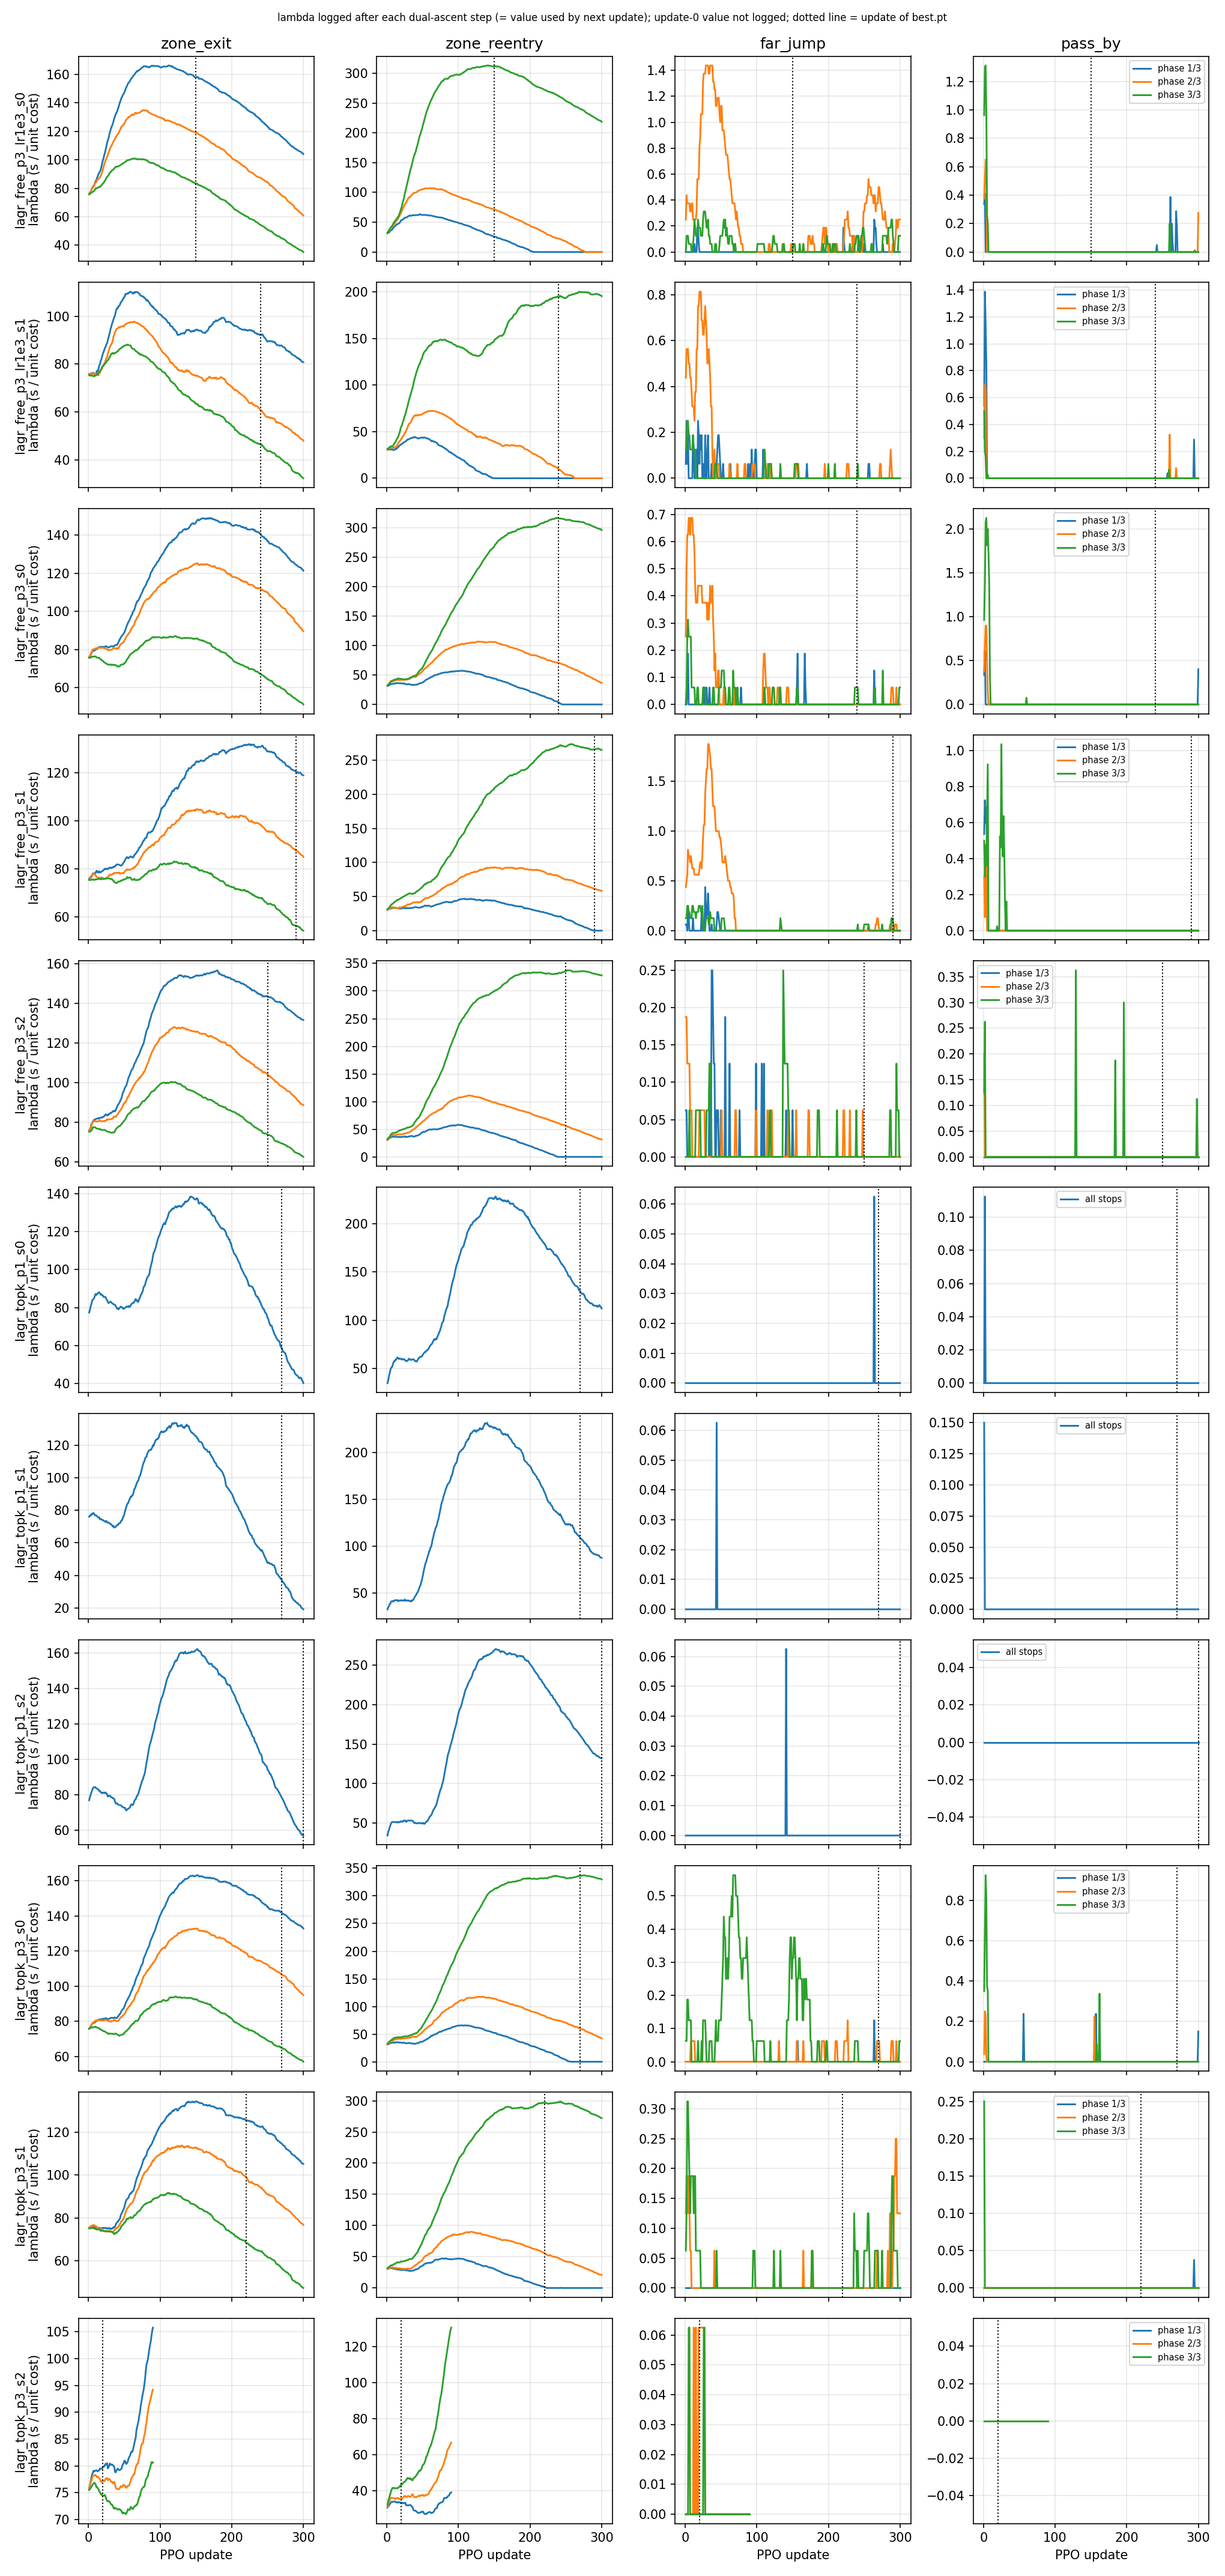

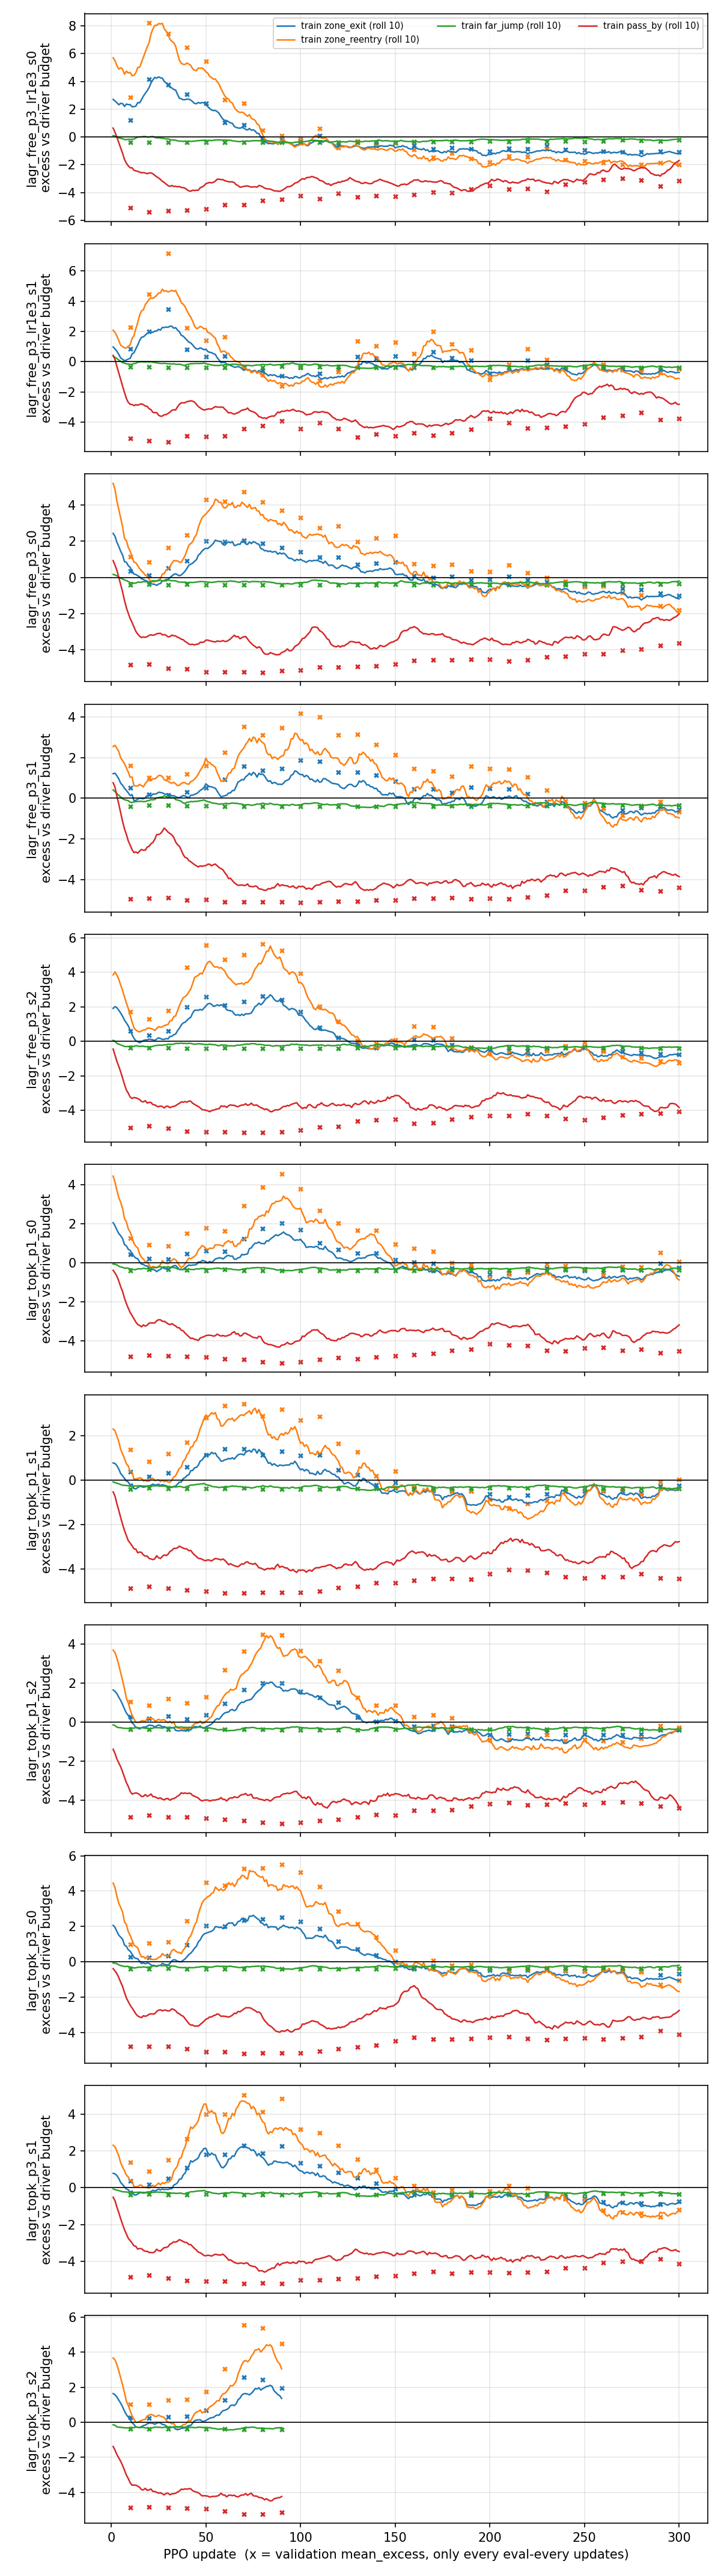

In [20]:
from IPython.display import Image, display
for f in ("lambda_over_updates.png", "excess_over_updates.png"):
    p = Path(EXPLAIN_DIR) / "macro" / f
    if p.exists():
        display(Image(str(p)))

## 6. Decision level: why did the policy pick this stop?
One greedy rollout from `best.pt`; the actor logits of every step are recomputed with `Policy.evaluate`. **Captum Integrated Gradients** then attributes the pre-softmax logit of the greedy action at the explained step to
- **dynamic** decision features of that candidate (`t_cand/tau, extra_vs_nearest, same_zone, reentry, passby`),
- **static_candidate**: the candidate's static input (16 GCN embedding dims + 4 route stats) into the candidate MLP,
- **static_history**: the same 20 static dims of every stop visited so far, which reach the actor through the LSTM (summed over history).

The attribution function is the model's real forward path (LSTM recomputed over the full history); the script aborts if it does not reproduce `Policy.evaluate` (|diff| < 1e-4). Baselines: **`mean_valid`** (primary: average valid candidate of that step) and **`zero`** (sensitivity). Completeness: sum(attributions) = logit(input) − logit(baseline); the saved `completeness_gap` and `n_steps` show convergence. Values are **baseline-relative attributions of one logit, not causal effects**. Progress and time-of-day inputs are held at their real values here (see section 7).


### 6.1 Decision & Attribution across seeds


In [26]:
failed = []
for s in seeds():
    ck = ckpt_path(EXPLAIN_MODEL, s)
    if not ck.exists():
        print(f"MISSING s{s}: {ck}"); failed.append(s); continue
    rc = run_fresh("explain_decision.py",
                   ["--cache-dir", CACHE, "--ckpt", ck, "--split", EXPLAIN_SPLIT, "--route-index", 0,
                    "--out-dir", f"{EXPLAIN_DIR}/decision/s{s}"], f"explain_decision.py  {EXPLAIN_MODEL}_s{s}")
    if rc: failed.append(s)
if failed:
    raise RuntimeError(f"explain_decision.py failed or checkpoint missing for seeds {failed}")



$ explain_decision.py  frozen_topk_s0
ckpt: /content/drive/MyDrive/lastmile_work_v4/runs_full_stratified/frozen_topk_s0/best.pt
  run=frozen_topk_s0 update=200 penalty=frozen env={'mask': 'topk', 'top_k': 12, 'n_phases': 1, 'farjump_regret_s': 300.0, 'passby_slack': 0.1}

DECISION step 10 (phase 1/1): at JM, 12 valid candidates.
CHOSEN (greedy = max logit): node 18 / stop CW   logit=1.2129

--- CAPTUM INTEGRATED GRADIENTS (baseline-relative, target = pre-softmax logit of the chosen stop) ---
forward-path check: IG function 1.212908 vs Policy.evaluate 1.212908  |diff|=4.77e-07

[baseline=mean_valid] logit(input)=1.2129 logit(baseline)=-2.7984 sum(attr)=4.0090 gap=-2.30e-03 (rel 5.73e-04) n_steps=64 converged=True
  dynamic           signed=   3.4437  magnitude=   3.4437
  static_candidate  signed=   0.5919  magnitude=   0.8186
  static_history    signed=  -0.0266  magnitude=   0.0562
  top |attr|: dynamic:passby=+1.462, dynamic:extra_vs_nearest=+1.251, dynamic:t_cand/tau=+0.730, static

### 6.2 Show decision candidate tables
One file per seed (route index 0, step = first step where the policy does not take the nearest valid stop). `attr_*` columns are filled on the chosen row (primary baseline).


In [27]:
import pandas as pd, glob
from IPython.display import display
d = f"{EXPLAIN_DIR}/decision"
files = sorted(f for f in glob.glob(f"{d}/**/*_step*.csv", recursive=True) if not f.endswith("_ig.csv"))
print(f"Found {len(files)} decision explanation CSV files:")
for f in files:
    print(f)
    display(pd.read_csv(f))


Found 5 decision explanation CSV files:
/content/drive/MyDrive/lastmile_work_v4/explain_full_stratified/decision/frozen_topk_s0_test_RouteID_71570e07-3258-4ab8-b498-bf016c6dbebe_step10.csv


,rank,node,stop_id,logit,prob,t_cand/tau,extra_vs_nearest,same_zone,reentry,passby,travel_s,cost_zone_exit,cost_zone_reentry,cost_far_jump,cost_pass_by,penalty_s,zone,chosen
0,1,18,CW,1.21291,0.33537,0.31550,0.02752,0.0,0.0,0.0,113.5,0.0,0.0,0.0,0.0,0.0,8,True
1,2,70,NN,1.04280,0.28291,0.28798,0.00000,0.0,0.0,0.0,103.6,0.0,0.0,0.0,0.0,0.0,8,False
2,3,45,IK,0.58742,0.17942,0.30493,0.01696,0.0,0.0,0.0,109.7,0.0,0.0,0.0,0.0,0.0,8,False
3,4,74,OR,0.44871,0.15618,0.32606,0.03808,0.0,0.0,0.0,117.3,0.0,0.0,0.0,0.0,0.0,8,False
4,5,137,ZY,-1.56386,0.02087,0.30605,0.01807,0.0,0.0,0.2,110.1,0.0,0.0,0.0,0.2,0.0,8,False
5,6,78,PM,-2.13874,0.01175,0.31994,0.03197,0.0,0.0,0.2,115.1,0.0,0.0,0.0,0.2,0.0,8,False
6,7,89,RX,-2.77543,0.00621,0.38860,0.10063,0.0,0.0,0.0,139.8,0.0,0.0,0.0,0.0,0.0,13,False
7,8,40,GP,-3.16329,0.00422,0.33051,0.04253,0.0,0.0,0.2,118.9,0.0,0.0,0.0,0.2,0.0,8,False


/content/drive/MyDrive/lastmile_work_v4/explain_full_stratified/decision/frozen_topk_s0_test_RouteID_71570e07-3258-4ab8-b498-bf016c6dbebe_steps.csv


,step,phase,cur,chosen,n_valid,chosen_is_nearest_valid,p_chosen,critic_value
0,0,1,DK,OF,12,True,0.249741,-11.443431
1,1,1,OF,FQ,19,True,0.997879,-10.178432
2,2,1,FQ,SY,19,True,0.999982,-10.644645
3,3,1,SY,FB,20,True,0.983196,-10.933036
4,4,1,FB,WJ,12,True,0.827148,-11.115336
...,...,...,...,...,...,...,...,...
132,132,1,NF,GR,5,True,1.000000,-1.253903
133,133,1,GR,SC,4,True,1.000000,-1.436553
134,134,1,SC,RX,3,True,0.400635,-1.335985
135,135,1,RX,AO,2,True,0.983674,-0.040355


/content/drive/MyDrive/lastmile_work_v4/explain_full_stratified/decision/s0/frozen_topk_s0_test_RouteID_71570e07-3258-4ab8-b498-bf016c6dbebe_step10.csv


,rank,node,stop_id,logit,prob,t_cand/tau,extra_vs_nearest,same_zone,reentry,passby,...,penalty_s,zone,chosen,attr_t_cand/tau,attr_extra_vs_nearest,attr_same_zone,attr_reentry,attr_passby,attr_static_candidate_sum,attr_static_history_sum
0,1,18,CW,1.21291,0.33537,0.31550,0.02752,0.0,0.0,0.0,...,0.0,8,True,0.73002,1.25136,0.0,-0.0,1.46232,0.59192,-0.02663
1,2,70,NN,1.04280,0.28291,0.28798,0.00000,0.0,0.0,0.0,...,0.0,8,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,45,IK,0.58742,0.17942,0.30493,0.01696,0.0,0.0,0.0,...,0.0,8,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,74,OR,0.44871,0.15618,0.32606,0.03808,0.0,0.0,0.0,...,0.0,8,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,137,ZY,-1.56386,0.02087,0.30605,0.01807,0.0,0.0,0.2,...,0.0,8,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,6,78,PM,-2.13874,0.01175,0.31994,0.03197,0.0,0.0,0.2,...,0.0,8,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,7,89,RX,-2.77543,0.00621,0.38860,0.10063,0.0,0.0,0.0,...,0.0,13,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,8,40,GP,-3.16329,0.00422,0.33051,0.04253,0.0,0.0,0.2,...,0.0,8,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN


/content/drive/MyDrive/lastmile_work_v4/explain_full_stratified/decision/s1/frozen_topk_s1_test_RouteID_71570e07-3258-4ab8-b498-bf016c6dbebe_step0.csv


,rank,node,stop_id,logit,prob,t_cand/tau,extra_vs_nearest,same_zone,reentry,passby,...,penalty_s,zone,chosen,attr_t_cand/tau,attr_extra_vs_nearest,attr_same_zone,attr_reentry,attr_passby,attr_static_candidate_sum,attr_static_history_sum
0,1,88,RU,-17.64644,0.24429,3.91077,0.01056,0.0,0.0,0.4,...,0.0,9,True,0.04871,0.14793,0.0,0.0,0.98025,0.34928,-0.62557
1,2,73,OF,-17.91227,0.18726,3.90021,0.00000,0.0,0.0,0.4,...,0.0,7,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,36,FQ,-17.94189,0.18180,3.91661,0.01640,0.0,0.0,0.4,...,0.0,7,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,64,LV,-18.47528,0.10665,3.96414,0.06393,0.0,0.0,0.6,...,0.0,9,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,48,IQ,-19.18039,0.05269,3.92050,0.02029,0.0,0.0,0.8,...,0.0,4,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,6,95,SY,-19.29259,0.04710,3.98999,0.08978,0.0,0.0,0.8,...,0.0,7,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,7,108,VD,-19.38970,0.04274,3.99361,0.09340,0.0,0.0,0.8,...,0.0,3,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,8,5,AU,-19.75602,0.02963,3.94302,0.04281,0.0,0.0,1.0,...,0.0,4,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN


/content/drive/MyDrive/lastmile_work_v4/explain_full_stratified/decision/s2/frozen_topk_s2_test_RouteID_71570e07-3258-4ab8-b498-bf016c6dbebe_step0.csv


,rank,node,stop_id,logit,prob,t_cand/tau,extra_vs_nearest,same_zone,reentry,passby,...,penalty_s,zone,chosen,attr_t_cand/tau,attr_extra_vs_nearest,attr_same_zone,attr_reentry,attr_passby,attr_static_candidate_sum,attr_static_history_sum
0,1,88,RU,-19.79829,0.27704,3.91077,0.01056,0.0,0.0,0.4,...,0.0,9,True,0.04334,0.17062,0.0,0.0,0.92162,0.48131,-0.18808
1,2,64,LV,-20.48829,0.13896,3.96414,0.06393,0.0,0.0,0.6,...,0.0,9,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,36,FQ,-20.60807,0.12327,3.91661,0.01640,0.0,0.0,0.4,...,0.0,7,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,73,OF,-20.74489,0.10751,3.90021,0.00000,0.0,0.0,0.4,...,0.0,7,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,48,IQ,-21.23487,0.06586,3.92050,0.02029,0.0,0.0,0.8,...,0.0,4,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,6,108,VD,-21.55152,0.04799,3.99361,0.09340,0.0,0.0,0.8,...,0.0,3,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,7,5,AU,-21.65951,0.04308,3.94302,0.04281,0.0,0.0,1.0,...,0.0,4,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,8,116,WN,-21.69048,0.04176,3.98221,0.08200,0.0,0.0,1.0,...,0.0,16,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 6.3 Integrated Gradients: convergence and attribution summary
Per seed: completeness check (does sum of attributions equal logit(input) − logit(baseline)?), group totals, and the largest attributions. Signed = pushes the chosen logit up (+) or down (−) relative to the baseline; magnitude = absolute value. Machine-readable: `decision/s*/*_ig.csv` and `*_ig.json`.


In [15]:
import json, glob
import pandas as pd
from IPython.display import display

d = f"{EXPLAIN_DIR}/decision"
conv, grp = [], []
for f in sorted(glob.glob(f"{d}/**/*_ig.json", recursive=True)):
    j = json.load(open(f))
    for b, v in j["baselines"].items():
        c = v["convergence"]
        conv.append({"run": j["run"], "route": j["route"], "step": j["step"], "chosen": j["chosen_stop_id"], "baseline": b,
                     "primary": b == j["primary_baseline"], "logit_input": c["logit_input"], "logit_baseline": c["logit_baseline"],
                     "sum_attr": c["sum_attr"], "completeness_gap": c["completeness_gap"], "relative_gap": c["relative_gap"],
                     "n_steps": c["n_steps"], "converged": c["converged"], "forward_check": j["forward_check_abs_diff"]})
        for g, t in v["group_totals"].items():
            grp.append({"run": j["run"], "baseline": b, "group": g, "signed": t["signed"], "magnitude": t["magnitude"]})
conv = pd.DataFrame(conv)
print("Convergence / completeness (one row per run x baseline):")
display(conv)
if len(conv) and not conv["converged"].all():
    print("WARNING: some attributions are above the completeness tolerance; treat those as approximate.")
print("\nGroup totals (signed = net push on the chosen logit vs baseline, magnitude = sum of |attr|):")
display(pd.DataFrame(grp).pivot_table(index=["baseline", "run"], columns="group", values=["signed", "magnitude"]))

rows = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f"{d}/**/*_ig.csv", recursive=True))], ignore_index=True)
for (b, run), g in rows.groupby(["baseline", "run"], sort=False):
    print(f"\n[{b}] {run} - route {g['route'].iloc[0]} step {g['step'].iloc[0]}: ten largest |attribution|")
    display(g.sort_values("magnitude", ascending=False).head(10)[["group", "feature", "signed_attr", "magnitude", "share_of_total_magnitude", "input_value", "baseline_value"]])

print("\nDynamic features, signed attribution by seed (rows: baseline, run). Route/step can differ per seed.")
display(rows[rows["group"] == "dynamic"].pivot_table(index=["baseline", "run"], columns="feature", values="signed_attr"))


Convergence / completeness (one row per run x baseline):


,run,route,step,chosen,baseline,primary,logit_input,logit_baseline,sum_attr,completeness_gap,relative_gap,n_steps,converged,forward_check
0,frozen_topk_s0,RouteID_71570e07-3258-4ab8-b498-bf016c6dbebe,10,CW,mean_valid,True,1.212907,-2.798384,4.008994,-0.002298,0.000573,64,True,1.192093e-07
1,frozen_topk_s0,RouteID_71570e07-3258-4ab8-b498-bf016c6dbebe,10,CW,zero,False,1.212907,16.250029,-15.033038,0.004083,0.000272,64,True,1.192093e-07
2,frozen_topk_s1,RouteID_71570e07-3258-4ab8-b498-bf016c6dbebe,0,RU,mean_valid,True,-17.646441,-18.548906,0.900613,-0.001852,0.002053,64,True,3.814697e-06
3,frozen_topk_s1,RouteID_71570e07-3258-4ab8-b498-bf016c6dbebe,0,RU,zero,False,-17.646441,1.952824,-19.608093,-0.008829,0.000450,64,True,3.814697e-06
4,frozen_topk_s2,RouteID_71570e07-3258-4ab8-b498-bf016c6dbebe,0,RU,mean_valid,True,-19.798294,-21.228378,1.428803,-0.001281,0.000896,64,True,0.000000e+00
5,frozen_topk_s2,RouteID_71570e07-3258-4ab8-b498-bf016c6dbebe,0,RU,zero,False,-19.798294,6.938437,-26.835539,-0.098807,0.003696,64,True,0.000000e+00



Group totals (signed = net push on the chosen logit vs baseline, magnitude = sum of |attr|):


magnitude                                  \
group                        dynamic static_candidate static_history   
baseline   run                                                         
mean_valid frozen_topk_s0   3.443698         0.818569       0.056222   
           frozen_topk_s1   1.176901         1.244531       1.510154   
           frozen_topk_s2   1.135573         1.081447       0.541294   
zero       frozen_topk_s0   7.607239        20.691151       1.703582   
           frozen_topk_s1   9.938317         8.720023       1.220976   
           frozen_topk_s2  12.910352        15.054077       0.125103   

                              signed                                  
group                        dynamic static_candidate static_history  
baseline   run                                                        
mean_valid frozen_topk_s0   3.443698         0.591924      -0.026629  
           frozen_topk_s1   1.176901         0.349279      -0.625565  
           frozen_topk_s2   1.135573         0.481307      -0.188077  
zero       frozen_topk_s0  -7.607239        -8.995822       1.570022  
           frozen_topk_s1  -9.938317        -8.452326      -1.217449  
           frozen_topk_s2 -12.910352       -14.050289       0.125103


[mean_valid] frozen_topk_s0 - route RouteID_71570e07-3258-4ab8-b498-bf016c6dbebe step 10: ten largest |attribution|


,group,feature,signed_attr,magnitude,share_of_total_magnitude,input_value,baseline_value
4,dynamic,passby,1.462320,1.462320,0.338618,0.000000,0.133333
1,dynamic,extra_vs_nearest,1.251356,1.251356,0.289767,0.027519,0.065578
0,dynamic,t_cand/tau,0.730023,0.730023,0.169046,0.315497,0.353556
24,static_candidate,out_time_max,0.339689,0.339689,0.078659,0.608059,0.532333
14,static_candidate,gcn_9,0.096343,0.096343,0.022309,0.914071,0.932688
22,static_candidate,out_time_median,-0.094645,0.094645,0.021916,0.107458,0.084251
20,static_candidate,gcn_15,0.092575,0.092575,0.021437,0.787366,0.805920
21,static_candidate,out_time_mean,0.073203,0.073203,0.016951,0.073373,0.057623
6,static_candidate,gcn_1,0.068218,0.068218,0.015797,0.926302,0.945300
16,static_candidate,gcn_11,0.026223,0.026223,0.006072,0.586672,0.599316


... (8 outputs left out)


[zero] frozen_topk_s2 - route RouteID_71570e07-3258-4ab8-b498-bf016c6dbebe step 0: ten largest |attribution|


,group,feature,signed_attr,magnitude,share_of_total_magnitude,input_value,baseline_value
225,dynamic,t_cand/tau,-11.265655,11.265655,0.401062,3.910771,0.0
230,static_candidate,gcn_0,-4.563712,4.563712,0.162470,1.028118,0.0
237,static_candidate,gcn_7,-3.086019,3.086019,0.109864,0.602398,0.0
229,dynamic,passby,-1.566435,1.566435,0.055766,0.400000,0.0
238,static_candidate,gcn_8,-1.506308,1.506308,0.053625,0.635692,0.0
232,static_candidate,gcn_2,-1.480300,1.480300,0.052699,0.477059,0.0
236,static_candidate,gcn_6,-1.193348,1.193348,0.042484,0.427683,0.0
241,static_candidate,gcn_11,-0.996537,0.996537,0.035477,0.260741,0.0
243,static_candidate,gcn_13,-0.846749,0.846749,0.030145,0.413985,0.0
247,static_candidate,out_time_median,-0.657552,0.657552,0.023409,0.170960,0.0



Dynamic features, signed attribution by seed (rows: baseline, run). Route/step can differ per seed.


feature                    extra_vs_nearest    passby  reentry  same_zone  \
baseline   run                                                              
mean_valid frozen_topk_s0          1.251356  1.462320      0.0        0.0   
           frozen_topk_s1          0.147932  0.980254      0.0        0.0   
           frozen_topk_s2          0.170617  0.921619      0.0        0.0   
zero       frozen_topk_s0         -0.935002  0.000000      0.0        0.0   
           frozen_topk_s1         -0.064157 -1.454000      0.0        0.0   
           frozen_topk_s2         -0.078262 -1.566435      0.0        0.0   

feature                    t_cand/tau  
baseline   run                         
mean_valid frozen_topk_s0    0.730023  
           frozen_topk_s1    0.048714  
           frozen_topk_s2    0.043337  
zero       frozen_topk_s0   -6.672237  
           frozen_topk_s1   -8.420161  
           frozen_topk_s2  -11.265655

## 7. Time-of-day impact: ablation and attribution on the LSTM sin/cos inputs
**What enters the model.** `RouteEnv.progress` gives the LSTM four inputs per step: share delivered, elapsed time, and **sin, cos of the local hour** `h = departure hour + elapsed/3600`. Only the last two are touched. The dataset has one static travel-time matrix per route (no hourly traffic), so any time-of-day effect is learned from how drivers behaved at different hours.

**Reference (neutral) time inputs** replace (sin, cos) at every step of the route:

| reference | (sin, cos) | purpose |
|---|---|---|
| `constant_noon` (headline) | those of 12:00 local, constant | on the unit circle (seen in training): "clock fixed at noon" |
| `zero` | (0, 0) | "no clock"; off the unit circle, never seen in training, sensitivity check |
| `frozen_departure` | those of the departure hour, constant | removes only the clock progression during the route |
| `shift_12h` | those of `h + 12 h` | keeps the progression, flips the time-of-day identity |
| `identity` | unchanged | control, must reproduce the nominal rollout exactly |

**Analyses** (per route × reference; script `explain_time.py`):
- *Teacher-forced*: nominal greedy trajectory fixed, only the LSTM time inputs replaced, logits recomputed. `tf_flip_rate` = share of steps whose argmax changes; `tf_mean_abs_dlogit_chosen`; `tf_mean_kl` = KL(nominal ‖ reference) over valid candidates. Pure input effect, no feedback through the state.
- *Closed-loop*: new greedy rollout with replaced inputs (the environment keeps the true time). Identical tour?, share of positions changed, travel-time change %, change of the four behaviour costs and of the λ-weighted penalty.
- *Integrated Gradients* on the (t+1, 2) sin/cos history: target = logit of the nominal greedy action (and its margin to the runner-up), baseline = the reference sequence, everything else at real values. Completeness gap saved. Baseline-relative attributions, **not causal effects**.

**Routes.** 30 routes evenly strided through the test split (same routes for every seed). IG: 5 of them evenly spaced by departure hour, 3 steps each (10 %, 50 %, 90 % of the tour). **Seeds**: `MACRO_SEEDS`.

**Limits.** Replacing sin/cos with values the policy never saw (`zero`) can change behaviour for reasons unrelated to real time of day; read it next to the on-circle references. Greedy decoding only; one checkpoint (`best.pt`) per seed. Effects are properties of the trained model, not of delivery operations.


### 7.1 Run time-of-day ablation across seeds


In [28]:
TIME_N_ROUTES = 30           # routes per seed, evenly strided through the split (same set for all seeds)
TIME_IG_ROUTES = 5           # of those, evenly spaced by departure hour
TIME_IG_STEPS_PER_ROUTE = 3

failed = []
for s in seeds():
    ck = ckpt_path(EXPLAIN_MODEL, s)
    if not ck.exists():
        print(f"MISSING s{s}: {ck}"); failed.append(s); continue
    rc = run_fresh("explain_time.py",
                   ["--cache-dir", CACHE, "--ckpt", ck, "--split", EXPLAIN_SPLIT,
                    "--n-routes", TIME_N_ROUTES, "--ig-routes", TIME_IG_ROUTES,
                    "--ig-steps-per-route", TIME_IG_STEPS_PER_ROUTE,
                    "--out-dir", f"{EXPLAIN_DIR}/time_ablation"], f"explain_time.py  {EXPLAIN_MODEL}_s{s}")
    if rc: failed.append(s)
if failed:
    raise RuntimeError(f"explain_time.py failed or checkpoint missing for seeds {failed}")



$ explain_time.py  frozen_topk_s0
ckpt: /content/drive/MyDrive/lastmile_work_v4/runs_full_stratified/frozen_topk_s0/best.pt
  run=frozen_topk_s0 update=200 penalty=frozen env={'mask': 'topk', 'top_k': 12, 'n_phases': 1, 'farjump_regret_s': 300.0, 'passby_slack': 0.1}
30 routes of split 'test' (461 total); refs=['constant_noon', 'zero', 'frozen_departure', 'shift_12h']
  rollouts/teacher-forcing: 10/30 routes
  rollouts/teacher-forcing: 20/30 routes
  rollouts/teacher-forcing: 30/30 routes
IG: 60 rows over 5 routes ['RouteID_4d9b0d8e-95d2-4778-b576-273309989a31', 'RouteID_ef341eaa-d1e3-425b-8328-172bf3680b07', 'RouteID_35338f86-fac0-42eb-a0c7-6de4b5742cd2', 'RouteID_901f1e9a-1133-4da0-b3b3-26daf3ec097a', 'RouteID_301f6881-e239-435c-a018-0afd6df1e890']
controls: {'identity_rollout_identical': True, 'identity_teacher_forced_max_abs_dlogit': 0.0, 'nominal_argmax_equals_rollout_action': True}
constant_noon      tf_flip_rate=0.0000  tour_identical=1.00  time_delta=+0.000%  positions_changed

### 7.2 Show time-of-day ablation results
Mean over the routes of each seed. `identity` is the control (all changes must be 0 / tours identical). Columns: `tf_*` teacher-forced, `cl_*` closed-loop.


In [29]:
import json, glob
import pandas as pd
from IPython.display import display

d = f"{EXPLAIN_DIR}/time_ablation"
abl = pd.concat([pd.read_csv(f).assign(run=Path(f).stem.replace("time_ablation_", ""))
                 for f in sorted(glob.glob(f"{d}/time_ablation_*.csv"))], ignore_index=True)
print(f"{abl['run'].nunique()} runs, {abl['route_id'].nunique()} routes per run")
for f in sorted(glob.glob(f"{d}/time_ablation_*.json")):
    j = json.load(open(f))
    print(f"{j['run']}: controls = {j['controls']}")

REF_ORDER = ["identity", "constant_noon", "zero", "frozen_departure", "shift_12h"]
cols = ["tf_flip_rate", "tf_mean_abs_dlogit_chosen", "tf_mean_kl", "cl_identical", "cl_frac_positions_changed",
        "cl_mean_abs_position_shift_over_stops", "cl_time_delta_pct", "cl_penalty_delta"]
summ = (abl.assign(cl_identical=abl["cl_identical"].astype(float))
           .groupby(["run", "reference"])[cols].mean()
           .reindex(pd.MultiIndex.from_product([sorted(abl["run"].unique()), REF_ORDER], names=["run", "reference"])))
display(summ.rename(columns={"cl_identical": "cl_frac_identical_tours"}))


3 runs, 30 routes per run
frozen_topk_s0: controls = {'identity_rollout_identical': True, 'identity_teacher_forced_max_abs_dlogit': 0.0, 'nominal_argmax_equals_rollout_action': True}
frozen_topk_s1: controls = {'identity_rollout_identical': True, 'identity_teacher_forced_max_abs_dlogit': 0.0, 'nominal_argmax_equals_rollout_action': True}
frozen_topk_s2: controls = {'identity_rollout_identical': True, 'identity_teacher_forced_max_abs_dlogit': 0.0, 'nominal_argmax_equals_rollout_action': False}


tf_flip_rate  tf_mean_abs_dlogit_chosen  \
run            reference                                                   
frozen_topk_s0 identity              0.000000                   0.000000   
               constant_noon         0.000000                   0.260230   
               zero                  0.000000                   0.177587   
               frozen_departure      0.000000                   0.174623   
               shift_12h             0.000000                   0.380335   
frozen_topk_s1 identity              0.000000                   0.000000   
               constant_noon         0.000249                   0.047381   
               zero                  0.000655                   0.173759   
               frozen_departure      0.000204                   0.046091   
               shift_12h             0.000655                   0.258804   
frozen_topk_s2 identity              0.000249                   0.000000   
               constant_noon         0.000249                   0.058380   
               zero                  0.000438                   0.285947   
               frozen_departure      0.000000                   0.065659   
               shift_12h             0.000394                   0.611651   

                                   tf_mean_kl  cl_frac_identical_tours  \
run            reference                                                 
frozen_topk_s0 identity          0.000000e+00                 1.000000   
               constant_noon     3.733152e-08                 1.000000   
               zero              5.765660e-08                 1.000000   
               frozen_departure  1.152879e-08                 1.000000   
               shift_12h         2.801914e-07                 1.000000   
frozen_topk_s1 identity          0.000000e+00                 1.000000   
               constant_noon     9.222273e-06                 0.966667   
               zero              4.359231e-05                 0.900000   
               frozen_departure  5.085299e-06                 0.933333   
               shift_12h         7.307871e-05                 0.900000   
frozen_topk_s2 identity          0.000000e+00                 1.000000   
               constant_noon     6.392859e-07                 1.000000   
               zero              6.988553e-06                 0.966667   
               frozen_departure  3.305589e-07                 1.000000   
               shift_12h         2.078111e-05                 0.900000   

                                 cl_frac_positions_changed  \
run            reference                                     
frozen_topk_s0 identity                           0.000000   
               constant_noon                      0.000000   
               zero                               0.000000   
               frozen_departure                   0.000000   
               shift_12h                          0.000000   
frozen_topk_s1 identity                           0.000000   
               constant_noon                      0.000498   
               zero                               0.054653   
               frozen_departure                   0.012358   
               shift_12h                          0.054653   
frozen_topk_s2 identity                           0.000000   
               constant_noon                      0.000000   
               zero                               0.014394   
               frozen_departure                   0.000000   
               shift_12h                          0.026752   

                                 cl_mean_abs_position_shift_over_stops  \
run            reference                                                 
frozen_topk_s0 identity                                       0.000000   
               constant_noon                                  0.000000   
               zero                                           0.000000   
               frozen_departure                         

### 7.3 Time attribution (Integrated Gradients on sin/cos)
Per seed and reference: attribution of the chosen-action logit (and of its margin to the runner-up) to the sin/cos inputs over the whole history that the LSTM saw. `attr_signed_sum` = net push vs the reference, `attr_magnitude_sum` = sum of |attr|, `completeness_gap` ≈ 0 means the attributions add up to logit(input) − logit(reference). Baseline-relative, not causal.


In [30]:
ig = pd.concat([pd.read_csv(f).assign(run=Path(f).stem.replace("time_ig_", ""))
                for f in sorted(glob.glob(f"{d}/time_ig_*.csv"))], ignore_index=True)
print(f"{len(ig)} IG rows; routes per run: {ig.groupby('run')['route_id'].nunique().to_dict()}")
agg = (ig.assign(abs_logit_diff=ig["logit_diff"].abs(), abs_signed=ig["attr_signed_sum"].abs())
         .groupby(["target", "reference", "run"])
         .agg(mean_abs_logit_diff=("abs_logit_diff", "mean"), mean_attr_magnitude=("attr_magnitude_sum", "mean"),
              mean_abs_signed_attr=("abs_signed", "mean"), max_abs_completeness_gap=("completeness_gap", lambda x: x.abs().max()),
              frac_converged=("converged", "mean")))
display(agg)
print("\nPer route/step, headline reference, chosen-action logit (departure hour spans the time of day):")
display(ig[(ig["reference"] == "constant_noon") & (ig["target"] == "chosen_logit")]
        .sort_values(["run", "dep_hour", "step"])[["run", "route_id", "dep_hour", "step", "attr_sin_sum", "attr_cos_sum", "attr_signed_sum",
                                                  "attr_current_step_signed", "attr_earlier_steps_signed", "logit_diff", "completeness_gap", "converged"]])


180 IG rows; routes per run: {'frozen_topk_s0': 5, 'frozen_topk_s1': 5, 'frozen_topk_s2': 5}


mean_abs_logit_diff  \
target              reference     run                                   
chosen_logit        constant_noon frozen_topk_s0             0.260257   
                                  frozen_topk_s1             0.069829   
                                  frozen_topk_s2             0.086521   
                    zero          frozen_topk_s0             0.199939   
                                  frozen_topk_s1             0.153301   
                                  frozen_topk_s2             0.259054   
margin_vs_runner_up constant_noon frozen_topk_s0             0.001076   
                                  frozen_topk_s1             0.022742   
                                  frozen_topk_s2             0.004877   
                    zero          frozen_topk_s0             0.000703   
                                  frozen_topk_s1             0.014135   
                                  frozen_topk_s2             0.007459   

                                                  mean_attr_magnitude  \
target              reference     run                                   
chosen_logit        constant_noon frozen_topk_s0             0.334847   
                                  frozen_topk_s1             0.193738   
                                  frozen_topk_s2             0.420421   
                    zero          frozen_topk_s0             0.463905   
                                  frozen_topk_s1             0.255313   
                                  frozen_topk_s2             0.643286   
margin_vs_runner_up constant_noon frozen_topk_s0             0.001252   
                                  frozen_topk_s1             0.038116   
                                  frozen_topk_s2             0.023274   
                    zero          frozen_topk_s0             0.001757   
                                  frozen_topk_s1             0.040469   
                                  frozen_topk_s2             0.024821   

                                                  mean_abs_signed_attr  \
target              reference     run                                    
chosen_logit        constant_noon frozen_topk_s0              0.260257   
                                  frozen_topk_s1              0.069853   
                                  frozen_topk_s2              0.086575   
                    zero          frozen_topk_s0              0.199935   
                                  frozen_topk_s1              0.153339   
                                  frozen_topk_s2              0.259063   
margin_vs_runner_up constant_noon frozen_topk_s0              0.001075   
                                  frozen_topk_s1              0.022798   
                                  frozen_topk_s2              0.004880   
                    zero          frozen_topk_s0              0.000702   
                                  frozen_topk_s1              0.014150   
                                  frozen_topk_s2              0.007449   

                                                  max_abs_completeness_gap  \
target              reference     run                                        
chosen_logit        constant_noon frozen_topk_s0                  0.000031   
                                  frozen_topk_s1                  0.000211   
                                  frozen_topk_s2                  0.000538   
                    zero          frozen_topk_s0                  0.000088   
                                  frozen_topk_s1                  0.000669   
                                  frozen_topk_s2                  0.000269   
margin_vs_runner_up constant_noon frozen_topk_s0                  0.000004   
                                  frozen_topk_s1                  0.000910   
                                  frozen_topk_s2                  0.000032   
                    zero          frozen_topk_s0                  0.000003   
                               


Per route/step, headline reference, chosen-action logit (departure hour spans the time of day):


,run,route_id,dep_hour,step,attr_sin_sum,attr_cos_sum,attr_signed_sum,attr_current_step_signed,attr_earlier_steps_signed,logit_diff,completeness_gap,converged
0,frozen_topk_s0,RouteID_4d9b0d8e-95d2-4778-b576-273309989a31,6.730278,19,0.512207,0.007394,0.519601,0.191286,0.328315,0.519611,-1.066923e-05,True
4,frozen_topk_s0,RouteID_4d9b0d8e-95d2-4778-b576-273309989a31,6.730278,95,0.415398,0.087719,0.503117,0.183627,0.319490,0.503086,3.063679e-05,True
8,frozen_topk_s0,RouteID_4d9b0d8e-95d2-4778-b576-273309989a31,6.730278,171,0.239798,0.061270,0.301068,0.084619,0.216449,0.301069,-9.238720e-07,True
12,frozen_topk_s0,RouteID_ef341eaa-d1e3-425b-8328-172bf3680b07,7.490556,12,0.470633,0.020370,0.491003,0.187918,0.303085,0.491027,-2.342463e-05,True
16,frozen_topk_s0,RouteID_ef341eaa-d1e3-425b-8328-172bf3680b07,7.490556,58,0.354781,0.074137,0.428918,0.138817,0.290101,0.428917,1.043081e-06,True
20,frozen_topk_s0,RouteID_ef341eaa-d1e3-425b-8328-172bf3680b07,7.490556,104,0.191921,0.024181,0.216102,0.063893,0.152209,0.216101,1.326203e-06,True
24,frozen_topk_s0,RouteID_35338f86-fac0-42eb-a0c7-6de4b5742cd2,8.507778,12,0.364431,0.010416,0.374847,0.135225,0.239622,0.374846,1.758337e-06,True
28,frozen_topk_s0,RouteID_35338f86-fac0-42eb-a0c7-6de4b5742cd2,8.507778,60,0.209534,0.027793,0.237327,0.085767,0.151560,0.237327,5.960464e-07,True
32,frozen_topk_s0,RouteID_35338f86-fac0-42eb-a0c7-6de4b5742cd2,8.507778,107,0.098143,0.008284,0.106426,0.033537,0.072889,0.106424,1.855195e-06,True
36,frozen_topk_s0,RouteID_901f1e9a-1133-4da0-b3b3-26daf3ec097a,9.182500,17,0.258243,0.005670,0.263913,0.101766,0.162147,0.263916,-3.039837e-06,True


### 7.4 Findings (generated from the saved results)
Numbers below are computed from `time_ablation/` at run time; nothing here is typed in by hand. Rule of thumb used for the wording: a reference is called *negligible* for a seed if teacher-forced argmax flips in under 1 % of steps and at least 95 % of closed-loop tours stay identical. That threshold is a convention, not a statistical test.


In [31]:
runs = sorted(abl["run"].unique())
print("control (identity) clean:", bool((abl[abl["reference"] == "identity"]["tf_flip_rate"] == 0).all()
                                         and abl[abl["reference"] == "identity"]["cl_identical"].all()))
for ref in ["constant_noon", "zero", "frozen_departure", "shift_12h"]:
    sub = abl[abl["reference"] == ref]
    print(f"\n{ref}")
    verdicts = []
    for r in runs:
        g = sub[sub["run"] == r]
        flip, same, dt = g["tf_flip_rate"].mean(), g["cl_identical"].mean(), g["cl_time_delta_pct"]
        negl = flip < 0.01 and same >= 0.95
        verdicts.append(negl)
        print(f"  {r}: flip rate {100*flip:5.2f}% of steps | identical tours {100*same:5.1f}% | "
              f"travel time {dt.mean():+.3f}% (mean), |{dt.abs().max():.2f}|% (max over routes) | "
              f"mean KL {g['tf_mean_kl'].mean():.4f} | {'negligible' if negl else 'not negligible'}")
    print("  across seeds:", "negligible in all seeds" if all(verdicts) else
          ("not negligible in any seed" if not any(verdicts) else "seed-dependent"))
print("\nIG share of |attribution| (chosen logit, constant_noon): see 7.3. Large IG magnitude with no flips = time inputs move logits "
      "but not the argmax; flips with small IG = interaction with other inputs (IG is baseline-relative).")


control (identity) clean: False

constant_noon
  frozen_topk_s0: flip rate  0.00% of steps | identical tours 100.0% | travel time +0.000% (mean), |0.00|% (max over routes) | mean KL 0.0000 | negligible
  frozen_topk_s1: flip rate  0.02% of steps | identical tours  96.7% | travel time +0.000% (mean), |0.00|% (max over routes) | mean KL 0.0000 | negligible
  frozen_topk_s2: flip rate  0.02% of steps | identical tours 100.0% | travel time +0.000% (mean), |0.00|% (max over routes) | mean KL 0.0000 | negligible
  across seeds: negligible in all seeds

zero
  frozen_topk_s0: flip rate  0.00% of steps | identical tours 100.0% | travel time +0.000% (mean), |0.00|% (max over routes) | mean KL 0.0000 | negligible
  frozen_topk_s1: flip rate  0.07% of steps | identical tours  90.0% | travel time -0.023% (mean), |0.87|% (max over routes) | mean KL 0.0000 | not negligible
  frozen_topk_s2: flip rate  0.04% of steps | identical tours  96.7% | travel time +0.066% (mean), |1.98|% (max over routes) | m

## 8. Route level: one route across models, baselines and driver
Part A uses only `eval_test*.json` (time, amazon score, behaviour costs vs driver budget and vs nn / nn_2opt / ortools tours). Part B (`--replay`) replays tours through the environment (no model) to add per-phase costs, zone switches and the list of cost events.


### 8.1 Run route-level explanation across seeds


In [32]:
failed = []
for s in seeds():
    evals = [p for m in ROUTE_MODELS for p in eval_files(m, s)]
    for m in ROUTE_MODELS:
        if not eval_files(m, s):
            print(f"s{s}: no eval_{EXPLAIN_SPLIT}*.json for {m}_s{s} (not in {RUNS}); compared without it")
    if not evals:
        print(f"MISSING s{s}: no eval files at all"); failed.append(s); continue
    rc = run_fresh("explain_route.py",
                   ["--evals", *evals, "--cache-dir", CACHE, "--auto", "worst:zone_reentry", "--replay",
                    "--out-dir", f"{EXPLAIN_DIR}/route/s{s}"], f"explain_route.py  seed {s}")
    if rc: failed.append(s)
if failed:
    raise RuntimeError(f"explain_route.py failed or no eval files for seeds {failed}")



$ explain_route.py  seed 0
route RouteID_f673034d-c37a-4a6b-8ff3-18b93bae205d   (4 eval files)

PART A - from eval JSON only (costs, time, amazon_score all belong to the stored sequence)
label                  seed split  pert stops     min  /driver     /nn  /nn2opt /ortools  amazon
frozen_topk               0  test   0.0   137   180.1    0.993   1.010    1.014    1.144  0.2177
frozen_topk+zls           0  test   0.0   137   180.1    0.993   1.010    1.014    1.144  0.2177
lagr_free_p3              0  test   0.0   137   205.4    1.132   1.152    1.156    1.304  0.1101
lagr_free_p3+zls          0  test   0.0   137   205.4    1.132   1.152    1.156    1.304  0.1101

label                     zone_exit (got/budget) zone_reentry (got/budget)     far_jump (got/budget)      pass_by (got/budget)
frozen_topk                    17.20/1.00  OVER         32.00/1.00  OVER          0.00/0.00    ok          1.40/6.60    ok
frozen_topk+zls                17.20/1.00  OVER         32.00/1.00  OVER    

### 8.2 Show replay tables


In [33]:
import pandas as pd
from pathlib import Path
from IPython.display import display
route_dir = Path(f"{EXPLAIN_DIR}/route")
for f in sorted(route_dir.glob("s*/*_replay_summary.csv")):
    print(f)
    display(pd.read_csv(f))
for f in sorted(route_dir.glob("s*/*_replay_events.csv")):
    print(f)
    ev = pd.read_csv(f)
    display(ev.groupby("tour")[[c for c in ev.columns if c.startswith("cost_")]].sum())


/content/drive/MyDrive/lastmile_work_v4/explain_full_stratified/route/s0/route_RouteID_f673034d-c37a-4a6b-8ff3-18b93bae205d_replay_summary.csv


,tour,eval_label,seed,time_min_nominal_T,zone_exit,zone_reentry,far_jump,pass_by,budget_zone_exit,budget_zone_reentry,budget_far_jump,budget_pass_by,zone_switches,n_zones_visited,stored_time_min,stored_zone_exit,stored_zone_reentry,stored_far_jump,stored_pass_by
0,driver,frozen_topk,0,181.441667,1.000000,1.0,0.0,6.599999,1.0,1.0,0.0,6.6,21,21,NaN,NaN,NaN,NaN,NaN
1,nn,frozen_topk,0,178.275000,29.800001,49.0,0.0,1.000000,1.0,1.0,0.0,6.6,69,21,NaN,NaN,NaN,NaN,NaN
2,nn_2opt,frozen_topk,0,177.598333,29.800001,49.0,0.0,1.200000,1.0,1.0,0.0,6.6,69,21,NaN,NaN,NaN,NaN,NaN
3,ortools,frozen_topk,0,157.476667,28.799999,44.0,0.0,2.800000,1.0,1.0,0.0,6.6,64,21,NaN,NaN,NaN,NaN,NaN
4,frozen_topk[s0] final,frozen_topk,0,180.136667,17.199997,32.0,0.0,1.400000,1.0,1.0,0.0,6.6,52,21,180.136667,17.199997,32.0,0.0,1.4
5,frozen_topk+zls[s0] final,frozen_topk+zls,0,180.136667,17.199997,32.0,0.0,1.400000,1.0,1.0,0.0,6.6,52,21,180.136667,17.199997,32.0,0.0,1.4
6,lagr_free_p3[s0] final,lagr_free_p3,0,205.381667,3.400000,5.0,0.0,3.600000,1.0,1.0,0.0,6.6,25,21,205.381667,3.400000,5.0,0.0,3.6
7,lagr_free_p3+zls[s0] final,lagr_free_p3+zls,0,205.381667,3.400000,5.0,0.0,3.600000,1.0,1.0,0.0,6.6,25,21,205.381667,3.400000,5.0,0.0,3.6


/content/drive/MyDrive/lastmile_work_v4/explain_full_stratified/route/s1/route_RouteID_f673034d-c37a-4a6b-8ff3-18b93bae205d_replay_summary.csv


,tour,eval_label,seed,time_min_nominal_T,zone_exit,zone_reentry,far_jump,pass_by,budget_zone_exit,budget_zone_reentry,budget_far_jump,budget_pass_by,zone_switches,n_zones_visited,stored_time_min,stored_zone_exit,stored_zone_reentry,stored_far_jump,stored_pass_by
0,driver,frozen_topk,1,181.441667,1.000000,1.0,0.0,6.599999,1.0,1.0,0.0,6.6,21,21,NaN,NaN,NaN,NaN,NaN
1,nn,frozen_topk,1,178.275000,29.800001,49.0,0.0,1.000000,1.0,1.0,0.0,6.6,69,21,NaN,NaN,NaN,NaN,NaN
2,nn_2opt,frozen_topk,1,177.598333,29.800001,49.0,0.0,1.200000,1.0,1.0,0.0,6.6,69,21,NaN,NaN,NaN,NaN,NaN
3,ortools,frozen_topk,1,157.476667,28.799999,44.0,0.0,2.800000,1.0,1.0,0.0,6.6,64,21,NaN,NaN,NaN,NaN,NaN
4,frozen_topk[s1] final,frozen_topk,1,179.685000,15.799998,27.0,0.0,1.200000,1.0,1.0,0.0,6.6,47,21,179.685000,15.799998,27.0,0.0,1.2
5,frozen_topk+zls[s1] final,frozen_topk+zls,1,179.685000,15.799998,27.0,0.0,1.200000,1.0,1.0,0.0,6.6,47,21,179.685000,15.799998,27.0,0.0,1.2
6,lagr_free_p3[s1] final,lagr_free_p3,1,200.006667,0.800000,3.0,0.0,3.400000,1.0,1.0,0.0,6.6,23,21,200.006667,0.800000,3.0,0.0,3.4
7,lagr_free_p3+zls[s1] final,lagr_free_p3+zls,1,194.953333,0.800000,3.0,0.0,3.400000,1.0,1.0,0.0,6.6,23,21,194.953333,0.800000,3.0,0.0,3.4


/content/drive/MyDrive/lastmile_work_v4/explain_full_stratified/route/s2/route_RouteID_b1a12bc1-d0e2-4e5c-8a53-08adab21b9da_replay_summary.csv


,tour,eval_label,seed,time_min_nominal_T,zone_exit,zone_reentry,far_jump,pass_by,budget_zone_exit,budget_zone_reentry,budget_far_jump,budget_pass_by,zone_switches,n_zones_visited,stored_time_min,stored_zone_exit,stored_zone_reentry,stored_far_jump,stored_pass_by
0,driver,frozen_topk,2,222.623333,0.000000,0.0,1.0,10.799998,0.0,0.0,1.0,10.8,18,20,NaN,NaN,NaN,NaN,NaN
1,nn,frozen_topk,2,208.900000,34.000004,52.0,0.0,0.400000,0.0,0.0,1.0,10.8,70,20,NaN,NaN,NaN,NaN,NaN
2,nn_2opt,frozen_topk,2,200.963333,33.400002,51.0,0.0,2.200000,0.0,0.0,1.0,10.8,69,20,NaN,NaN,NaN,NaN,NaN
3,ortools,frozen_topk,2,158.583333,35.600002,48.0,0.0,2.600000,0.0,0.0,1.0,10.8,66,20,NaN,NaN,NaN,NaN,NaN
4,frozen_topk[s2] final,frozen_topk,2,202.206667,12.400000,22.0,0.0,2.200000,0.0,0.0,1.0,10.8,40,20,202.206667,12.4,22.0,0.0,2.200000
5,frozen_topk+zls[s2] final,frozen_topk+zls,2,202.206667,12.400000,22.0,0.0,2.200000,0.0,0.0,1.0,10.8,40,20,202.206667,12.4,22.0,0.0,2.200000
6,lagr_free_p3[s2] final,lagr_free_p3,2,198.680000,1.200000,2.0,0.0,3.600001,0.0,0.0,1.0,10.8,20,20,198.680000,1.2,2.0,0.0,3.600001
7,lagr_free_p3+zls[s2] final,lagr_free_p3+zls,2,198.680000,1.200000,2.0,0.0,3.600001,0.0,0.0,1.0,10.8,20,20,198.680000,1.2,2.0,0.0,3.600001


... (2 outputs left out)

/content/drive/MyDrive/lastmile_work_v4/explain_full_stratified/route/s1/route_RouteID_f673034d-c37a-4a6b-8ff3-18b93bae205d_replay_events.csv


,cost_zone_exit,cost_zone_reentry,cost_far_jump,cost_pass_by
tour,,,,
driver,1.0,1.0,0.0,6.6
frozen_topk+zls[s1] final,15.8,27.0,0.0,1.2
frozen_topk[s1] final,15.8,27.0,0.0,1.2
lagr_free_p3+zls[s1] final,0.8,3.0,0.0,3.4
lagr_free_p3[s1] final,0.8,3.0,0.0,3.4
nn,29.8,49.0,0.0,1.0
nn_2opt,29.8,49.0,0.0,1.2
ortools,28.8,44.0,0.0,2.8


/content/drive/MyDrive/lastmile_work_v4/explain_full_stratified/route/s2/route_RouteID_b1a12bc1-d0e2-4e5c-8a53-08adab21b9da_replay_events.csv


,cost_zone_exit,cost_zone_reentry,cost_far_jump,cost_pass_by
tour,,,,
driver,0.0,0.0,1.0,10.8
frozen_topk+zls[s2] final,12.4,22.0,0.0,2.2
frozen_topk[s2] final,12.4,22.0,0.0,2.2
lagr_free_p3+zls[s2] final,1.2,2.0,0.0,3.6
lagr_free_p3[s2] final,1.2,2.0,0.0,3.6
nn,34.0,52.0,0.0,0.4
nn_2opt,33.4,51.0,0.0,2.2
ortools,35.6,48.0,0.0,2.6


## 9. Route level, all routes: aggregation over seeds, driver, Nearest Neighbor and OR-Tools (Phase 2)
Section 8 explains **one** route. This section aggregates **every test route** of the eval files, for every seed, and compares with the stored baselines. It reads `eval_test.json` / `eval_test_zls.json` only (JSON; no model, no checkpoint, no environment replay, no training, no `evaluate`) via `explain_route.py --aggregate` (cell `### 3.4`). Output folder: `explain_<preset>_<split>/route_all/`.

**What is compared** (labels as in the eval files): policies in `AGG_MODELS` (`frozen_topk`, `lagr_free_p3`; each also as `<n>+zls` = policy + zone local search, a post-processing of the same tour, so it is **not** an independent method) and the baselines stored in every record: `driver` (Amazon driver sequence), `nn`, `nn_2opt`, `ortools`. Baselines come from `lastmile_rl.py prepare`: they do not depend on the seed and are counted **once**, not once per seed.

**Metrics = project definitions** (`lastmile_rl.summarize`): `time_over_<b>` = time / baseline time; costs `zone_exit`, `zone_reentry`, `far_jump`, `pass_by` as stored for the tour (`stored_<cost>`), driver budget = `driver_costs` (= the cost of the driver's own sequence), satisfied = cost <= budget + 1e-9, `excess_<cost>` = cost - budget; `amazon_score` = challenge score (lower = closer to the driver). The driver's own `amazon_score` is 0 **by definition**, so it is stored as NaN (undefined) and no amazon comparison with the driver is made.

**Missing data is never imputed.** The expected route set is `splits['test']` of `cache_*/index.json`. A route absent from an eval file, a baseline absent from a record (e.g. no OR-Tools tour) or a non-finite value stays NaN, is excluded from that statistic and is listed in `missing_routes.csv`; a record for a route outside the expected split is listed in `unmatched_routes.csv`. Every statistic reports `n_valid`.

**Statistics.**
- *Route-to-route variability*: spread of per-route values (box = IQR, whiskers 5-95 %, dots = routes). For a policy the route value is the mean over its seeds, using only routes present in **all** seeds of that method.
- *Seed-to-seed variability*: the seeds are separate **trained models** (greedy evaluation of each is deterministic), so this is training variability. It is shown as one marker per seed (seed mean with its own interval over routes), plus range and SD of the seed means, and a route x seed variance decomposition (route / seed / route-x-seed shares). With 2-3 seeds the seed and interaction components are rough; no precision is claimed.
- *Intervals*: percentile bootstrap over **routes** (route = resampling unit, seeds of a route stay together), 95 %, B = 5000. They are conditional on the trained seeds and do **not** contain training-seed uncertainty; that is what the per-seed markers and `seed_variability.csv` show. A t-interval over seed means (df = seeds - 1) is also stored, flagged as indicative.
- *Paired comparisons* (`paired_comparisons.csv`): A - B per shared route, lower is better for every metric, so a negative difference means A is lower. Per seed and pooled over seeds; mean difference with bootstrap CI, median, counts A lower / tie / A higher, Wilcoxon p as in `lastmile_rl.report` (`p_holm` = Holm adjustment over the pooled comparisons; exploratory).

**Reading caution.** `nn`, `nn_2opt` and `ortools` minimise travel time only (OR-Tools under a time limit, not a proven optimum) and do not see the behaviour costs, so higher constraint costs than the policy are expected by construction: the comparison shows a time / constraint trade-off, not that one method "wins".


### 9.1 Which eval files exist, and which are missing


In [34]:
AGG_MODELS = list(ROUTE_MODELS)       # policies aggregated here (same two as section 8); append e.g. "lagr_topk_p3" to include more
AGG_INCLUDE_ZLS = True                # also aggregate <n>+zls (eval_test_zls.json)
AGG_OUT = f"{EXPLAIN_DIR}/route_all"  # NEW output folder

import pandas as pd
from pathlib import Path
from IPython.display import display

variants = [("", f"eval_{EXPLAIN_SPLIT}.json")] + ([("+zls", f"eval_{EXPLAIN_SPLIT}_zls.json")] if AGG_INCLUDE_ZLS else [])
agg_evals, agg_expect, rows, todo = [], [], [], []
for m in AGG_MODELS:
    for s in seeds():
        ck = ckpt_path(m, s)
        for suffix, fname in variants:
            p = run_dir(m, s) / fname
            agg_expect.append(f"{m}{suffix}:{s}")
            rows.append({"model": m + suffix, "seed": s, "eval_file": p.exists(), "best.pt": ck.exists(), "path": str(p)})
            if p.exists():
                agg_evals.append(str(p))
            elif suffix == "" or not (run_dir(m, s) / variants[0][1]).exists():
                todo.append((m, s, ck.exists()))
display(pd.DataFrame(rows))

missing = sorted(set(todo))
if not missing:
    print("all expected eval files exist")
for m, s, has_ck in missing:
    print(f"\nMISSING eval for {m}_s{s}:")
    if has_ck:
        print("  checkpoint exists -> inference only (this notebook never runs it); same call as the pipeline's stage 6:")
        print(f'  !python /content/lastmile_rl.py evaluate --cache-dir "{CACHE}" --runs-dir "{RUNS}" --device cpu '
              f'--ckpt "{ckpt_path(m, s)}" --split {EXPLAIN_SPLIT} --local-search')
    else:
        print(f"  no best.pt in {run_dir(m, s)} -> the model for this seed was never trained to completion, so there is nothing to evaluate.")
        print("  training is needed: run `## 4. Run the pipeline` of the TRAINING notebook for this seed only (it resumes unfinished variants of that seed,")
        print(f'  not only {m}, and it evaluates them): --preset {PRESET} --split-by {SPLIT_BY} --work-dir "{WORK_DIR}" --seeds {s}  (plus your --data-root)')
print(f"\nwill aggregate {len(agg_evals)} eval file(s); methods/seeds without a file are reported as missing by the aggregation, not filled.")


,model,seed,eval_file,best.pt,path
0,frozen_topk,0,True,True,/content/drive/MyDrive/lastmile_work_v4/runs_f...
1,frozen_topk+zls,0,True,True,/content/drive/MyDrive/lastmile_work_v4/runs_f...
2,frozen_topk,1,True,True,/content/drive/MyDrive/lastmile_work_v4/runs_f...
3,frozen_topk+zls,1,True,True,/content/drive/MyDrive/lastmile_work_v4/runs_f...
4,frozen_topk,2,True,True,/content/drive/MyDrive/lastmile_work_v4/runs_f...
5,frozen_topk+zls,2,True,True,/content/drive/MyDrive/lastmile_work_v4/runs_f...
6,lagr_free_p3,0,True,True,/content/drive/MyDrive/lastmile_work_v4/runs_f...
7,lagr_free_p3+zls,0,True,True,/content/drive/MyDrive/lastmile_work_v4/runs_f...
8,lagr_free_p3,1,True,True,/content/drive/MyDrive/lastmile_work_v4/runs_f...
9,lagr_free_p3+zls,1,True,True,/content/drive/MyDrive/lastmile_work_v4/runs_f...


all expected eval files exist

will aggregate 12 eval file(s); methods/seeds without a file are reported as missing by the aggregation, not filled.


If `lagr_free_p3_s2` is missing from the inventory above, run the next cell to train it from `bc_topk_s2/best.pt` and evaluate the test split. With `--local-search`, evaluation writes both the nominal `eval_test.json` and zone-local-search `eval_test_zls.json`. The aggregation cell re-scans the run folders when it executes, so run it after this cell completes.

In [12]:
!python /content/lastmile_rl.py train \
  --runs-dir "{RUNS}" \
  --cache-dir "{CACHE}" \
  --name lagr_free_p3 \
  --seed 2 \
  --mask free \
  --phases 3 \
  --penalty lagrangian \
  --updates 300 \
  --val-routes 50 \
  --device cuda \
  --resume

!python /content/lastmile_rl.py evaluate \
  --runs-dir "{RUNS}" \
  --cache-dir "{CACHE}" \
  --ckpt "{RUNS}/lagr_free_p3_s2/best.pt" \
  --split test \
  --local-search \
  --device cuda

Installing missing packages: ['ijson>=3.1', 'ortools']
resuming /content/drive/MyDrive/lastmile_work_v4/runs_full_stratified/lagr_free_p3_s2 at update 91
params=102114 train_routes=2130 penalty=lagrangian dual_ascent=['zone_exit', 'zone_reentry', 'far_jump', 'pass_by'] env={'mask': 'free', 'top_k': 12, 'n_phases': 3, 'farjump_regret_s': 300.0, 'passby_slack': 0.1}
update 100: train_ratio=1.0308 val_ratio=1.0031 feasible=False kl=0.0001 lambda=[[145.3, 58.1, 0.0, 0.0], [122.6, 107.2, 0.0, 0.0], [99.2, 236.6, 0.0, 0.0]]
update 110: train_ratio=1.0590 val_ratio=1.0203 feasible=False kl=0.0002 lambda=[[150.0, 55.7, 0.1, 0.0], [125.2, 109.6, 0.0, 0.0], [100.1, 258.2, 0.0, 0.0]]
update 120: train_ratio=1.0517 val_ratio=1.0261 feasible=False kl=0.0001 lambda=[[152.7, 53.1, 0.0, 0.0], [128.0, 110.2, 0.0, 0.0], [100.2, 276.7, 0.0, 0.0]]
update 130: train_ratio=1.0215 val_ratio=1.0325 feasible=False kl=0.0005 lambda=[[153.8, 50.2, 0.0, 0.0], [127.7, 107.6, 0.0, 0.0], [98.8, 287.6, 0.0, 0.0]]
upd

### 9.2 Run the aggregation (fresh process, JSON only)


In [40]:
# Re-scan now so evaluation files generated after the inventory cell are included.
agg_evals, agg_expect = [], []

for m in AGG_MODELS:
    for s in seeds():
        for suffix, fname in variants:
            p = run_dir(m, s) / fname
            agg_expect.append(f"{m}{suffix}:{s}")
            if p.exists():
                agg_evals.append(str(p))

if not agg_evals:
    raise RuntimeError("no eval files found: see 9.1 for the exact files and how to generate them")
rc = run_fresh("explain_route.py",
               ["--aggregate", "--evals", *agg_evals, "--cache-dir", CACHE, "--split", EXPLAIN_SPLIT,
                "--expect", *agg_expect, "--out-dir", AGG_OUT, "--n-boot", 5000, "--ci", 0.95],
               "explain_route.py --aggregate")
if rc:
    raise RuntimeError(f"explain_route.py --aggregate failed (exit {rc})")


$ explain_route.py --aggregate
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scip

RuntimeError: explain_route.py --aggregate failed (exit 1)

### 9.3 Route coverage: matched, missing and unmatched routes
Per method and seed: routes of the expected test split that have a record (`matched_routes`), expected routes without one (`missing_routes`), records for routes outside the split (`unmatched_routes`). `n_valid_*` = matched routes with a finite value of that metric; `n_valid_time_over_<b>` = routes where baseline `<b>` exists in the record (the paired comparison vs `<b>` can only use those).


In [ ]:
from IPython.display import Image, display
A = Path(AGG_OUT)
cov = pd.read_csv(A / "coverage.csv")
display(cov[["method", "seed", "status", "expected_routes", "matched_routes", "missing_routes", "unmatched_routes", "coverage"]
            + [c for c in cov.columns if c.startswith("n_valid_time_over_")]])
miss = pd.read_csv(A / "missing_routes.csv")
print(f"{len(miss)} missing / unusable (route, method, seed) entries; full list: {A / 'missing_routes.csv'}")
if len(miss):
    display(miss.groupby(["method", "seed", "reason"], dropna=False).size().rename("n_routes").reset_index())
unm = pd.read_csv(A / "unmatched_routes.csv")
print(f"{len(unm)} unmatched entries (records for routes outside the expected test split); full list: {A / 'unmatched_routes.csv'}")
inc = pd.read_csv(A / "baseline_inconsistencies.csv")
print(f"{len(inc)} baseline value mismatches between eval files (0 = the stored baselines agree across all files)")
if len(inc):
    display(inc.head(20))
display(Image(str(A / "coverage.png")))


### 9.4 Route-to-route distribution and seed-to-seed spread
Box / dots = routes (policy: mean over seeds, routes present in all seeds). Black diamond = mean over routes with bootstrap CI over routes. Coloured side markers = single seeds, each with its own CI over routes: the horizontal distance between them is the seed-to-seed spread, the box is the route-to-route spread.


In [ ]:
agg = pd.read_csv(A / "aggregate_results.csv")
HEAD = ["time_over_driver", "amazon_score", "stored_zone_exit", "stored_zone_reentry", "stored_far_jump", "stored_pass_by"]
display(Image(str(A / "route_distributions.png")))
pooled = agg[agg.scope.isin(["pooled_seeds", "baseline"]) & agg.metric.isin(HEAD)]
print("Mean over routes [bootstrap CI over routes], SD / quantiles across routes. Policies: route value = mean over seeds (n_valid = routes complete in all seeds).")
display(pooled[["metric", "method", "n_seeds", "n_valid", "coverage", "mean", "ci_lo", "ci_hi", "sd", "median", "q25", "q75", "p05", "p95"]]
        .sort_values(["metric", "method"]).round(4).reset_index(drop=True))
per_seed = agg[(agg.scope == "per_seed") & agg.metric.isin(HEAD)]
print("Per seed (one trained model each): mean over its routes [CI over routes]")
display(per_seed[["metric", "method", "seed", "n_valid", "mean", "ci_lo", "ci_hi", "sd", "median"]]
        .sort_values(["metric", "method", "seed"]).round(4).reset_index(drop=True))


### 9.5 Seed-to-seed vs route-to-route variability
Top: share of the variance (routes x seeds, one value per cell) that is route-to-route (some routes are simply harder), seed-to-seed (a seed shifts all routes), or route x seed (a seed treats particular routes differently). Bottom: per-route range across seeds. Only methods with at least 2 seeds are shown; `S` = number of seeds.


In [22]:
sv = pd.read_csv(A / "seed_variability.csv")
if sv.empty:
    print("no policy has >= 2 seeds in the aggregated files: no seed-to-seed statistics")
else:
    display(Image(str(A / "seed_vs_route_variability.png")))
    mean_cols = [c for c in sv.columns if c.startswith("mean_s")]
    display(sv[sv.metric.isin(HEAD)][["method", "metric", "n_seeds", *mean_cols, "seed_mean_range", "seed_mean_sd", "seed_mean_t_ci_lo", "seed_mean_t_ci_hi",
                                      "n_routes_complete", "route_to_route_sd_of_route_means", "mean_within_route_seed_sd",
                                      "sd_route", "sd_seed", "sd_residual", "share_route", "share_seed", "share_residual"]]
            .sort_values(["metric", "method"]).round(4).reset_index(drop=True))
    print("seed_mean_t_ci_*: t-interval over seed means (df = seeds - 1), indicative only with 2-3 seeds.")


NameError: name 'pd' is not defined

### 9.6 Constraint satisfaction against the driver budget
Share of test routes whose cost is at most the driver's own cost on that route (project definition `satisfied_<cost>`); `costs_le_driver` = all four costs, `both_le_driver` = also travel time <= driver. Per seed with Wilson CI over routes; pooled = bootstrap over per-route share across seeds. The driver is omitted (it meets its own budget by definition).


In [ ]:
sat = pd.read_csv(A / "satisfaction_results.csv")
display(Image(str(A / "constraint_satisfaction.png")))
display(sat[sat.scope.isin(["per_seed", "baseline", "pooled_seeds"])][["metric", "method", "scope", "seed", "n_valid", "share", "ci_lo", "ci_hi"]]
        .sort_values(["metric", "method", "scope", "seed"]).round(4).reset_index(drop=True))


### 9.7 Paired comparisons on shared routes
Policy minus baseline on the routes both have (`n_pairs` = shared routes with finite values; routes without an OR-Tools tour drop out of the OR-Tools comparison only). Negative = policy lower (better). Box = route-to-route spread of the paired differences (mean over seeds), diamond = pooled mean with CI over routes, side markers = single seeds.


In [ ]:
pc = pd.read_csv(A / "paired_comparisons.csv")
display(Image(str(A / "paired_time_amazon.png")))
display(Image(str(A / "paired_constraints.png")))
BASES = ["driver", "nn", "nn_2opt", "ortools"]
pols = [m for m in dict.fromkeys(pc.A) if m not in BASES]
sel = pc[(pc.scope == "pooled_seeds") & pc.A.isin(pols) & pc.B.isin(BASES)
         & (((pc.metric == "time_min") & (pc["transform"] == "pct")) | pc.metric.str.startswith("stored_") | (pc.metric == "amazon_score"))]
cols = ["A", "B", "metric", "n_pairs", "mean_diff", "ci_lo", "ci_hi", "median_diff", "n_A_lower", "n_tie", "n_A_higher", "p_wilcoxon", "p_holm"]
print("Policy vs baseline, pooled over seeds (time_min rows are % difference; costs / amazon are absolute differences):")
display(sel[cols].round(4).reset_index(drop=True))
pp = pc[(pc.scope == "pooled_seeds") & pc.A.isin(pols) & pc.B.isin(pols) & (((pc.metric == "time_min") & (pc["transform"] == "pct")) | pc.metric.str.startswith("stored_"))]
print("Policy vs policy (shared routes and seeds), pooled over seeds:")
display(pp[cols].round(4).reset_index(drop=True))


### 9.8 Findings (generated from the saved results)
Every number below is read from `route_all/*.csv` when this cell runs; nothing is typed in by hand. Wording follows the intervals: "CI above/below 0" means the bootstrap CI over routes excludes 0, "CI includes 0" means no clear difference. Intervals are conditional on the trained seeds. Differences are descriptive, not causal.


In [ ]:
def f(v, p=3):
    return "nan" if pd.isna(v) else f"{v:.{p}f}"

def verdict(lo, hi, lower="lower", higher="higher"):
    if pd.isna(lo) or pd.isna(hi):
        return "CI n/a"
    return f"{higher}, CI above 0" if lo > 0 else f"{lower}, CI below 0" if hi < 0 else "CI includes 0"

COSTS4 = ["zone_exit", "zone_reentry", "far_jump", "pass_by"]
out = []

# self-contained: re-read the saved tables (so this cell also works after a restart of sections 9.3-9.7)
A = Path(AGG_OUT)
cov, agg, sat, sv, pc = (pd.read_csv(A / n) for n in ("coverage.csv", "aggregate_results.csv", "satisfaction_results.csv", "seed_variability.csv", "paired_comparisons.csv"))
unm, inc = pd.read_csv(A / "unmatched_routes.csv"), pd.read_csv(A / "baseline_inconsistencies.csv")
BASES = ["driver", "nn", "nn_2opt", "ortools"]

# --- coverage
bad = cov[cov.status != "loaded"]
if len(bad):
    out.append("COVERAGE GAPS: " + "; ".join(
        f"{r.method} {'s' + str(int(r.seed)) if pd.notna(r.seed) else '(baseline)'}: {int(r.matched_routes)}/{int(r.expected_routes)} routes ({r.status})" for r in bad.itertuples()))
else:
    out.append("COVERAGE: every method and seed covers all expected test routes.")
if len(unm):
    out.append(f"{unm.route_id.nunique()} route(s) outside the expected test split appear in {len(unm)} (method, seed) entr{'y' if len(unm) == 1 else 'ies'} and were excluded (unmatched_routes.csv).")
if len(inc):
    out.append(f"WARNING: {len(inc)} baseline mismatch(es) between eval files (see baseline_inconsistencies.csv).")

pol_main = [m for m in AGG_MODELS if m in set(agg.method)]
for m in pol_main:
    p = agg[(agg.method == m) & (agg.scope == "pooled_seeds")]
    t = p[p.metric == "time_over_driver"]
    if t.empty:
        continue
    t = t.iloc[0]
    ps = agg[(agg.method == m) & (agg.scope == "per_seed") & (agg.metric == "time_over_driver")].sort_values("seed")
    seeds_txt = ", ".join(f"s{int(r.seed)}={f(r['mean'])}" for _, r in ps.iterrows())
    out.append(f"{m}: travel time / driver = {f(t['mean'])} [{f(t.ci_lo)}, {f(t.ci_hi)}] over {int(t.n_valid)} routes complete in {int(t.n_seeds)} seed(s) "
               f"(route-to-route SD {f(t.sd)}); per seed: {seeds_txt}.")
    ex = []
    for c in COSTS4:
        e = p[p.metric == f"excess_{c}"]
        if len(e):
            e = e.iloc[0]
            ex.append(f"{c} {f(e['mean'], 2)} [{f(e.ci_lo, 2)}, {f(e.ci_hi, 2)}] ({verdict(e.ci_lo, e.ci_hi, 'below budget', 'above budget')})")
    out.append(f"  mean excess over driver budget: " + "; ".join(ex))
    sa = sat[(sat.method == m) & (sat.metric == "costs_le_driver") & (sat.scope == "per_seed")].sort_values("seed")
    sb = sat[(sat.method == m) & (sat.metric == "both_le_driver") & (sat.scope == "per_seed")].sort_values("seed")
    out.append("  routes with ALL four costs <= driver budget, per seed: " + ", ".join(f"s{int(r.seed)}={f(r.share, 3)} [{f(r.ci_lo, 3)}, {f(r.ci_hi, 3)}]" for r in sa.itertuples())
               + "; time AND costs: " + ", ".join(f"s{int(r.seed)}={f(r.share, 3)}" for r in sb.itertuples()))

# --- paired vs baselines
for m in pol_main:
    for b in BASES:
        q = pc[(pc.A == m) & (pc.B == b) & (pc.scope == "pooled_seeds")]
        t = q[(q.metric == "time_min") & (q["transform"] == "pct")]
        if t.empty or t.iloc[0].n_pairs == 0:
            out.append(f"{m} vs {b}: no shared routes with a {b} tour: no paired comparison.")
            continue
        t = t.iloc[0]
        parts = []
        for c in COSTS4:
            r = q[q.metric == f"stored_{c}"]
            if len(r) and r.iloc[0].n_pairs:
                r = r.iloc[0]
                parts.append(f"{c} {f(r.mean_diff, 2)} ({verdict(r.ci_lo, r.ci_hi)})")
        out.append(f"{m} vs {b} ({int(t.n_pairs)} shared routes): time {f(t.mean_diff, 2)} % [{f(t.ci_lo, 2)}, {f(t.ci_hi, 2)}] ({verdict(t.ci_lo, t.ci_hi)}; "
                   f"policy faster on {int(t.n_A_lower)}, equal {int(t.n_tie)}, slower {int(t.n_A_higher)} routes; Holm p {f(t.p_holm, 4)}); costs: " + "; ".join(parts))

# --- zone local search
for m in pol_main:
    q = pc[(pc.A == m + "+zls") & (pc.B == m) & (pc.scope == "pooled_seeds") & (pc.metric == "time_min") & (pc["transform"] == "pct")]
    if len(q) and q.iloc[0].n_pairs:
        q = q.iloc[0]
        out.append(f"{m}+zls vs {m}: time {f(q.mean_diff, 3)} % [{f(q.ci_lo, 3)}, {f(q.ci_hi, 3)}] over {int(q.n_pairs)} routes (post-processing of the same tour, not an independent method).")

# --- variability
if not sv.empty:
    for m in pol_main:
        for met, name in (("time_over_driver", "time/driver"), ("stored_zone_reentry", "zone_reentry")):
            r = sv[(sv.method == m) & (sv.metric == met)]
            if r.empty:
                continue
            r = r.iloc[0]
            sh = {k: r[f"share_{k}"] for k in ("route", "seed", "residual")}
            big = max(sh, key=lambda k: sh[k] if pd.notna(sh[k]) else -1)
            out.append(f"{m} {name}: seed means range {f(r.seed_mean_range, 4)} (SD {f(r.seed_mean_sd, 4)}, {int(r.n_seeds)} seeds) vs route-to-route SD {f(r.route_to_route_sd_of_route_means, 4)}; "
                       f"variance shares route {f(sh['route'], 2)}, seed {f(sh['seed'], 2)}, route x seed {f(sh['residual'], 2)} (largest: {big}).")
out.append("Limits: seeds are 2-3 trained models, so seed-level statistics are rough; intervals over routes do not include training uncertainty; "
           "nn / nn_2opt / ortools ignore the behaviour costs; OR-Tools is time-limited; the driver amazon_score is 0 by definition.")
print("\n".join("- " + l if not l.startswith("  ") else l for l in out))


## 10. Notes
- `eval_test.json` in this run is the **pure greedy policy tour**; `eval_test_zls.json` (label `<n>+zls`) is policy + zone local search. Their stored `costs` belong to the stored `sequence`.
- `sequence` holds cache node indices, not stop ids; the scripts map them with `node_ids` from `cache_*/routes/<route>.npz`.
- Outputs are in `explain_<preset>_<split>/{macro,decision/s<seed>,time_ablation,route/s<seed>,route_all}`. Seeds come from `MACRO_SEEDS` (5.1); run folders are `<n>_s<seed>`.
- **Captum IG (`explain_decision.py`):** baseline-relative attribution of the pre-softmax logit of the greedy action to dynamic features, the candidate's static embedding and the static embeddings of the visited history (via the LSTM). Primary baseline `mean_valid` (average valid candidate of the step), sensitivity baseline `zero`. Completeness gap and `n_steps` saved in `*_ig.json` / `*_ig.csv`. Not causal effects; a different baseline gives different numbers. Progress/time inputs are held fixed there.
- **Time-of-day (`explain_time.py`):** teacher-forced and closed-loop ablation of the LSTM sin/cos inputs against `constant_noon` (headline), `zero`, `frozen_departure`, `shift_12h`, plus IG on the sin/cos history; definitions and limits in section 7. Results: `time_ablation/time_ablation_<run>.{csv,json}`, `time_ig_<run>.csv`.
- **All-route aggregation (`explain_route.py --aggregate`, section 9):** reads the stored `records` of `eval_test*.json` only. Files: `route_all/{route_level_results,aggregate_results,satisfaction_results,seed_variability,paired_comparisons,coverage,missing_routes,unmatched_routes,baseline_inconsistencies}.csv`, `route_aggregation.json` (tables + manifest of files, definitions, issues) and the `*.png` plots.
- **Limits of the aggregation:** (1) seeds are separately trained models (2-3 here): seed-level SD, t-intervals and variance shares are rough; (2) bootstrap intervals resample routes and are conditional on the trained seeds; (3) baselines are seed-independent and counted once; they come from the first eval file that holds them and are checked against every other file (`baseline_inconsistencies.csv`); (4) a baseline that is absent from a record (e.g. OR-Tools) is a missing value, not a result; (5) baseline costs are replays stored in the eval records: a test route that has no record in any aggregated eval file has no baseline cost here (it would need `explain_route.py --replay`, which uses the environment); (6) models with a missing seed are aggregated over the seeds they have and flagged in the coverage table; (7) p-values are descriptive and unadjusted except `p_holm`.
- **Scope:** Phase 1 (sections 5-8) and Phase 2 route-level aggregation (section 9). Not covered: any model retraining, per-step or per-phase aggregation over all routes, perturbed-time evaluations (`eval_test_perturb*.json` are skipped by design).
